# FIT5196 Assessment 2 - Data Cleansing, Audit and Transformation

**Group:** Group005  
**Members:**
- Minh Cao - 37068113
- Tiansheng Zhang - 32196253
- Tianpu Le - 36400661
- Sally Vu - 36071668
- Riley Calnan - 37127810

This notebook is the group's technical report. Section 0 sets the paths and checks the environment.
Task 1 investigates the three batches (1.0), repairs the dirty batch (1.1), recovers the missing batch
(1.2), removes delivery-charge outliers (1.3) and exports the cleaned CSVs (1.4). Task 2 writes the
field-level audit log and validates every output read back from disk. Task 3 builds customer profiles
from the cleaned CSVs and compares scaling and nonlinear transformations. Check IDs such as `DIRTY-02`
or `DELIV-07` label the evidence that the audit log and the text cite.

## 0. Configuration and environment

The allocated package is expected in `Group005_A2/` beside this notebook, holding the three input
CSVs, `warehouses.csv`, the manifests, README and `resources/`. To run elsewhere, change `GROUP_ID`,
`DATA_DIR` or `OUTPUT_DIR` in the next cell only; paths are relative to the working directory.
Outputs are written to `OUTPUT_DIR`, and the original inputs are never overwritten.

In [1]:
from pathlib import Path

GROUP_ID = "Group005"
DATA_DIR = Path(f"{GROUP_ID}_A2")
OUTPUT_DIR = Path(".")

DIRTY_INPUT = DATA_DIR / f"{GROUP_ID}_dirty_data.csv"
MISSING_INPUT = DATA_DIR / f"{GROUP_ID}_missing_data.csv"
OUTLIER_INPUT = DATA_DIR / f"{GROUP_ID}_outlier_data.csv"
WAREHOUSES_INPUT = DATA_DIR / "warehouses.csv"
RESOURCE_CONTRACT = DATA_DIR / "resource_contract.json"
NLTK_DATA_DIR = DATA_DIR / "resources" / "nltk_data"

DIRTY_OUTPUT = OUTPUT_DIR / f"{GROUP_ID}_dirty_clean.csv"
MISSING_OUTPUT = OUTPUT_DIR / f"{GROUP_ID}_missing_clean.csv"
OUTLIER_OUTPUT = OUTPUT_DIR / f"{GROUP_ID}_outlier_clean.csv"
AUDIT_OUTPUT = OUTPUT_DIR / "audit_log.csv"


### 0.1 Dependencies and local resources

The next cell imports the libraries, fixes `RANDOM_SEED = 5196` for every split, prints the Python
and package versions of this run and compares them with `requirements.txt`. The VADER lexicon is
loaded from the supplied `resources/` directory and verified against `resource_contract.json` in
the happiness section (spec 3.4). Once the dependencies are installed, the notebook runs offline: it
downloads nothing and needs no Drive mount. `group005_eda_scaling.py` must sit beside the notebook,
because 1.0 and 3.3 import their helpers from it.

In [2]:
import json
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

RANDOM_SEED = 5196          # every split in this notebook reproduces from this

# Show all 16 fields rather than an elided middle, and clip the long cart JSON
# to a readable width instead of wrapping it across the page.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 34)

print("Python", sys.version.split()[0])
for module in (pd, np, sklearn, nltk):
    print(f"  {module.__name__:12s} {module.__version__}")

# Report any difference from requirements.txt; a mismatch is shown, not fatal.
from importlib.metadata import PackageNotFoundError, version
REQUIREMENTS = Path("requirements.txt")
if REQUIREMENTS.is_file():
    pins = dict(line.split("==") for line in REQUIREMENTS.read_text().splitlines()
                if "==" in line and not line.lstrip().startswith("#"))
    def _installed(name):
        try:
            return version(name)
        except PackageNotFoundError:
            return "not installed"
    differ = {name: (pin, _installed(name)) for name, pin in pins.items() if _installed(name) != pin}
    print(f"requirements.txt: {len(pins)} pinned packages; "
          + ("all match this environment" if not differ else f"different here (pinned, installed): {differ}"))
else:
    print("requirements.txt not found beside the notebook")

Python 3.13.9
  pandas       2.3.3
  numpy        2.3.5
  sklearn      1.7.2
  nltk         3.9.2
requirements.txt not found beside the notebook


This run used Python 3.13.3 with the versions pinned in `requirements.txt`, and the check above
reports any difference in the marker's environment. NLTK must be 3.9.2, the version stated in
`resource_contract.json`; the other pins record the tested environment.

## Task 1 - Data cleansing and explanation (15 marks)

### 1.0 Initial investigation and shared evidence

The batches are read as text, so blank cells and original spellings stay visible and every audit
value can quote its source exactly. The audit set-up comes first, because every later repair and
removal is recorded when it is made. The raw-batch EDA follows (EDA-01 to EDA-04). Then the shared
rules, applied the same way to every batch: current prices (spec 3.1), totals (3.2), location,
dates and seasons (3.3) and happiness (3.4). The seasonal delivery model (3.5) is fitted and
evaluated last, on the 420 complete rows of the missing batch.

#### Audit set-up: input integrity checks

Check the allocated input and frozen-resource checksums before recording decisions. Check 6 in 2.2 compares them again after export, which shows the original files are unchanged.

In [3]:
# Audit set-up: verify allocated inputs before any cleaning or export.
import hashlib


def _audit_digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def _audit_preflight():
    if sys.flags.optimize:
        raise RuntimeError("Run without -O: validation uses assertions")
    manifest = json.loads((DATA_DIR / "A2_manifest.json").read_text())
    entries = {entry["path"]: entry for entry in manifest["files"]}
    required = {
        "Group005_dirty_data.csv", "Group005_missing_data.csv",
        "Group005_outlier_data.csv", "warehouses.csv", "resource_contract.json",
        "resources/nltk_data/sentiment/vader_lexicon.zip",
    }
    for name in sorted(required):
        path = DATA_DIR / name
        if not path.is_file():
            raise FileNotFoundError(f"Missing allocated input: {path}")
        if _audit_digest(path) != entries[name]["sha256"]:
            raise ValueError(f"Input checksum mismatch: {name}")
    return {str(path.resolve()): _audit_digest(path)
            for path in DATA_DIR.rglob("*") if path.is_file()}


audit_input_hashes = _audit_preflight()
print("AUDIT_INPUTS: PASS; allocated inputs and resource checksums verified")


AUDIT_INPUTS: PASS; allocated inputs and resource checksums verified


In [4]:
# Read every batch as text.
def read_batch(path, source):
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    df["source_batch"] = source
    return df

dirty = read_batch(DIRTY_INPUT, "dirty")
missing = read_batch(MISSING_INPUT, "missing")
outlier = read_batch(OUTLIER_INPUT, "outlier")
warehouses = pd.read_csv(WAREHOUSES_INPUT)

for name, df in [("dirty", dirty), ("missing", missing), ("outlier", outlier)]:
    print(f"{name:8s} shape={df.shape[0]}x{df.shape[1] - 1}  "
          f"unique order_id={df.order_id.nunique()}")

all_ids = pd.concat([dirty.order_id, missing.order_id, outlier.order_id])
print(f"\n1,500 order ids, all distinct: {all_ids.nunique() == 1500}")

dirty    shape=500x16  unique order_id=500
missing  shape=500x16  unique order_id=500
outlier  shape=500x16  unique order_id=500

1,500 order ids, all distinct: True


#### Audit set-up: nine-column recorder and value validation

The recorder is defined here before any cleaning decisions. It validates metadata, field domains and canonical replacements, rejects cross-batch key collisions, and records only actual changes or row removals.

In [5]:
from collections import Counter, defaultdict
from dataclasses import dataclass
from tempfile import TemporaryDirectory

import csv
import datetime as dt
import json
import re
import warnings
from collections.abc import Iterable
from decimal import Decimal, InvalidOperation
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
from pandas.api.types import is_scalar


AUDIT_COLUMNS = (
    "source_file", "record_key", "field_name", "issue_type",
    "original_value", "corrected_value", "method", "evidence", "confidence",
)

ORDER_COLUMNS = frozenset({
    "order_id", "customer_id", "date", "nearest_warehouse", "shopping_cart",
    "order_price", "delivery_charges", "customer_lat", "customer_long",
    "coupon_discount", "order_total", "season", "is_expedited_delivery",
    "distance_to_nearest_warehouse", "latest_customer_review",
    "is_happy_customer",
})

NUMERIC_COLUMNS = frozenset({
    "order_price", "delivery_charges", "customer_lat", "customer_long",
    "coupon_discount", "order_total", "distance_to_nearest_warehouse",
})

BOOLEAN_COLUMNS = frozenset({"is_expedited_delivery", "is_happy_customer"})
DECIMALS = {
    "order_price": 2, "order_total": 2, "delivery_charges": 2,
    "distance_to_nearest_warehouse": 4,
}
AUDIT_SEASONS = frozenset({"Summer", "Autumn", "Winter", "Spring"})
ISO_DATE = re.compile(r"[0-9]{4}-[0-9]{2}-[0-9]{2}\Z")
PLAIN_NUMBER = re.compile(r"-?[0-9]+(?:\.[0-9]+)?\Z")
BOOL_TEXT = {"true": "True", "1": "True", "false": "False", "0": "False"}
CONFIDENCE_LEVELS = frozenset({"high", "medium", "low"})
GUARANTEED_CORRECT = frozenset({
    "order_id", "customer_id", "shopping_cart", "customer_long",
    "coupon_discount", "latest_customer_review",
})
INPUT_NAME = re.compile(r"(Group\d{3})_(dirty|missing|outlier)_data\.csv\Z")


def _missing(value: Any) -> bool:
    """An empty CSV field, including its usual pandas scalar representations."""
    if value is None:
        return True
    if isinstance(value, str):
        return value == ""
    if not is_scalar(value):
        raise TypeError("Pass a scalar CSV field, not a collection")
    return bool(pd.isna(value))


def _value(value: Any, *, source: bool = False) -> str:
    if _missing(value):
        if source:
            return "<MISSING>"
        raise ValueError("The submitted replacement must be nonempty")
    result = str(value)
    if not result.strip():
        raise ValueError("The submitted replacement must be nonempty")
    if not source and result in {"<MISSING>", "ROW_REMOVED"}:
        raise ValueError("Reserved audit sentinel is not a replacement value")
    return result


def _check_text(field: str, text: str) -> str:
    """Validate an already-formatted replacement against its field's domain."""
    if text != text.strip():
        raise ValueError(f"{field} has surrounding whitespace: {text!r}")
    if field == "date":
        if not ISO_DATE.fullmatch(text):
            raise ValueError(f"date must be YYYY-MM-DD, got {text!r}")
        dt.date.fromisoformat(text)  # Also rejects impossible calendar dates.
    elif field == "season":
        if text not in AUDIT_SEASONS:
            raise ValueError(f"season must be one of {sorted(AUDIT_SEASONS)}, got {text!r}")
    elif field in BOOLEAN_COLUMNS:
        if text.lower() not in BOOL_TEXT:
            raise ValueError(f"{field} must be boolean text, got {text!r}")
        return BOOL_TEXT[text.lower()]
    elif field in NUMERIC_COLUMNS:
        if not PLAIN_NUMBER.fullmatch(text):
            raise ValueError(f"{field} must be a plain decimal number, got {text!r}")
        number = Decimal(text)
        if field in DECIMALS and number != round(number, DECIMALS[field]):
            raise ValueError(f"{field} has more than {DECIMALS[field]} dp: {text!r}")
    return text


def canonical_value(field: str, value: Any) -> str:
    """Represent a replacement as it must also be written to the cleaned CSV.

    Strings are validated without rounding. Native date, boolean, and numeric
    values are formatted for their target field. Call this on the value assigned
    to the output DataFrame as well as the value sent to ``record_change``.
    """
    if field not in ORDER_COLUMNS:
        raise ValueError(f"Unknown order field: {field!r}")
    if _missing(value):
        raise ValueError("The submitted replacement must be nonempty")
    if isinstance(value, (pd.Timestamp, dt.date)):
        if field != "date":
            raise ValueError("A date value must be recorded against the date field")
        if isinstance(value, dt.datetime) and value.time() != dt.time(0):
            raise ValueError("date has a non-midnight time component")
        return _check_text(field, _value(value.strftime("%Y-%m-%d")))
    if isinstance(value, (bool, np.bool_)):
        if field not in BOOLEAN_COLUMNS:
            raise ValueError("A boolean value must be recorded against a boolean field")
        return _check_text(field, _value(str(bool(value))))
    if field in DECIMALS and isinstance(value, (int, float, np.number, Decimal)):
        if not Decimal(str(value)).is_finite():
            raise ValueError("A reconstructed numeric value must be finite")
        return _check_text(field, _value(f"{value:.{DECIMALS[field]}f}"))
    return _check_text(field, _value(value))


def _same_meaning(field: str, before: str, after: str) -> bool:
    """Suppress exact matches and harmless numeric/boolean representations."""
    if before == after:
        return True
    if field in NUMERIC_COLUMNS:
        try:
            return Decimal(before) == Decimal(after)
        except InvalidOperation:
            return False
    if field in BOOLEAN_COLUMNS:
        normalised = {"true": True, "1": True, "false": False, "0": False}
        left, right = normalised.get(before.lower()), normalised.get(after.lower())
        return left is not None and left == right
    if field == "shopping_cart":
        # A loop over every input field can encounter equivalent cart JSON.
        # Suppress that no-op before rejecting actual edits to guaranteed-correct carts.
        try:
            left, right = json.loads(before), json.loads(after)
            if not isinstance(left, list) or not isinstance(right, list):
                return False
            # Dict key order and cart-entry order have no effect on cart meaning.
            canonical = lambda items: sorted(
                json.dumps(item, sort_keys=True, separators=(",", ":"))
                for item in items
            )
            return canonical(left) == canonical(right)
        except (TypeError, ValueError):
            return False
    return False


def same_meaning(field: str, before: str, after: str) -> bool:
    """Use the recorder's equivalence rule for input/output reconciliation."""
    return _same_meaning(field, before, after)


def _filename(source_file: str | Path, issue_type: str) -> tuple[str, str]:
    name = Path(source_file).name
    match = INPUT_NAME.fullmatch(name)
    if match is None:
        raise ValueError("source_file must name a GroupNNN_*_data.csv input")
    group_id, batch = match.groups()
    expected_batch = "outlier" if issue_type == "outlier_row" else issue_type
    if batch != expected_batch:
        raise ValueError(f"{issue_type!r} must refer to the {expected_batch} input")
    return name, group_id


def _required_text(label: str, value: str) -> str:
    if not isinstance(value, str) or not value.strip():
        raise ValueError(f"{label} must be a nonempty string")
    return value


class AuditRecorder:
    """Collect exactly one audit entry for each changed source field or removed row."""

    def __init__(self, warehouse_names: Iterable[str] | None = None) -> None:
        """Optionally validate repaired warehouse names against warehouses.csv."""
        if isinstance(warehouse_names, (str, bytes)):
            raise TypeError("Pass a collection of warehouse names, not one string")
        self._warehouse_names = (
            None if warehouse_names is None else frozenset(warehouse_names)
        )
        if self._warehouse_names is not None and (
            not self._warehouse_names
            or any(
                not isinstance(name, str) or not name.strip()
                or name != name.strip()
                for name in self._warehouse_names
            )
        ):
            raise ValueError("warehouse_names must be a nonempty set of unpadded strings")
        self._rows: list[dict[str, str]] = []
        self._keys: set[tuple[str, str, str]] = set()
        self._key_source: dict[str, str] = {}
        self._dirty_fields: dict[str, str] = {}
        self._group_id: str | None = None

    @property
    def rows(self) -> tuple[dict[str, str], ...]:
        """Snapshot of audit entries in recording order."""
        return tuple(row.copy() for row in self._rows)

    def to_frame(self) -> pd.DataFrame:
        """Nine-column audit view, including its schema when empty."""
        return pd.DataFrame(self._rows, columns=list(AUDIT_COLUMNS))

    def summary(self) -> pd.DataFrame:
        """Counts for notebook evidence; this is not input/output reconciliation."""
        return (
            self.to_frame()
            .groupby(["source_file", "issue_type", "field_name", "confidence"])
            .size().rename("n").reset_index()
        )

    def record_change(
        self, *, source_file: str | Path, record_key: str, field_name: str,
        issue_type: str, original_value: Any, corrected_value: Any,
        method: str, evidence: str, confidence: str,
    ) -> bool:
        """Record a dirty repair or missing-value recovery; return False if unchanged."""
        if issue_type not in {"dirty", "missing"}:
            raise ValueError("issue_type must be 'dirty' or 'missing'")
        if field_name not in ORDER_COLUMNS:
            raise ValueError(f"Unknown order field: {field_name!r}")
        source = self._check_metadata(
            source_file, record_key, issue_type, method, evidence, confidence,
        )
        was_missing = _missing(original_value)
        if (issue_type == "missing") != was_missing:
            raise ValueError("'missing' requires an empty source; 'dirty' requires a value")
        before = _value(original_value, source=True)
        after = canonical_value(field_name, corrected_value)
        if not was_missing and _same_meaning(field_name, before, after):
            return False
        if field_name in GUARANTEED_CORRECT:
            raise ValueError(f"{field_name} is guaranteed complete and error-free")
        if (
            field_name == "nearest_warehouse"
            and self._warehouse_names is not None
            and after not in self._warehouse_names
        ):
            raise ValueError(f"Warehouse {after!r} is not in warehouses.csv")
        self._append(
            source=source, record_key=record_key, field_name=field_name,
            issue_type=issue_type, original_value=before, corrected_value=after,
            method=method, evidence=evidence, confidence=confidence,
        )
        return True

    def record_removed(
        self, *, source_file: str | Path, record_key: str,
        original_charge: Any, method: str, evidence: str, confidence: str,
    ) -> None:
        """Record one removed outlier row against its delivery_charges field."""
        source = self._check_metadata(
            source_file, record_key, "outlier_row", method, evidence, confidence,
        )
        if _missing(original_charge):
            raise ValueError("An outlier row must have an observed delivery charge")
        self._append(
            source=source, record_key=record_key,
            field_name="delivery_charges", issue_type="outlier_row",
            original_value=_value(original_charge), corrected_value="ROW_REMOVED",
            method=method, evidence=evidence, confidence=confidence,
        )

    def _check_metadata(
        self, source_file: str | Path, record_key: str, issue_type: str,
        method: str, evidence: str, confidence: str,
    ) -> tuple[str, str]:
        name, group_id = _filename(source_file, issue_type)
        _required_text("record_key", record_key)
        if record_key != record_key.strip():
            raise ValueError(f"record_key has surrounding whitespace: {record_key!r}")
        _required_text("method", method)
        _required_text("evidence", evidence)
        if confidence not in CONFIDENCE_LEVELS:
            raise ValueError("confidence must be high, medium or low")
        if self._group_id is not None and group_id != self._group_id:
            raise ValueError(f"Mixed group inputs: {self._group_id} and {group_id}")
        return name, group_id

    def _append(
        self, *, source: tuple[str, str], record_key: str, field_name: str,
        issue_type: str, original_value: str, corrected_value: str,
        method: str, evidence: str, confidence: str,
    ) -> None:
        name, group_id = source
        key = record_key
        entry_key = (name, key, field_name)
        if entry_key in self._keys:
            raise ValueError(f"Duplicate audit entry for {entry_key!r}")
        previous_source = self._key_source.get(key)
        if previous_source is not None and previous_source != name:
            raise ValueError(f"{key} logged in both {previous_source} and {name}")
        row = dict(zip(AUDIT_COLUMNS, (
            name, key, field_name, issue_type, original_value, corrected_value,
            method, evidence, confidence,
        )))
        previous_dirty_field = self._dirty_fields.get(key)
        if issue_type == "dirty" and previous_dirty_field is not None and previous_dirty_field != field_name:
            warnings.warn(
                f"{key}: second dirty field {field_name!r} (already {previous_dirty_field!r})",
                UserWarning, stacklevel=3,
            )
        self._rows.append(row)
        self._keys.add(entry_key)
        self._key_source[key] = name
        if issue_type == "dirty":
            self._dirty_fields.setdefault(key, field_name)
        self._group_id = group_id

    def write_csv(self, path: str | Path) -> Path:
        """Export UTF-8 CSV with the required header, even if there are no changes."""
        target = Path(path)
        target.parent.mkdir(parents=True, exist_ok=True)
        with target.open("w", encoding="utf-8", newline="") as handle:
            writer = csv.DictWriter(handle, fieldnames=AUDIT_COLUMNS)
            writer.writeheader()
            writer.writerows(self._rows)
        return target


# Notebook Task 2.1 prose, kept beside the code that enforces it.

#### Audit set-up: CSV export and reconciliation functions

These functions compare the actual raw/clean file differences with the nine-column log. Task 2.2 runs them when all three cleaned outputs exist.

In [6]:
ORDER_SCHEMA = (
    "order_id", "customer_id", "date", "nearest_warehouse", "shopping_cart",
    "order_price", "delivery_charges", "customer_lat", "customer_long",
    "coupon_discount", "order_total", "season", "is_expedited_delivery",
    "distance_to_nearest_warehouse", "latest_customer_review",
    "is_happy_customer",
)
CHANGE_COLUMNS = (
    "source_file", "record_key", "field_name", "issue_type",
    "original_value", "corrected_value",
)
import textwrap

CHECK_COLUMNS = ("check_id", "observed", "passed", "interpretation")


@dataclass(frozen=True)
class AuditReconResult:
    checks: pd.DataFrame
    missing_entries: pd.DataFrame
    extra_entries: pd.DataFrame
    removed_ids: tuple[str, ...] = ()
    retained_ids: tuple[str, ...] = ()

    @property
    def passed(self) -> bool:
        return bool(self.checks["passed"].all())


def _read(path: str | Path) -> pd.DataFrame:
    """Read original field text; reject irregular CSV widths and hidden indexes."""
    target = Path(path)
    try:
        with target.open(encoding='utf-8-sig', newline='') as handle:
            records = csv.reader(handle, strict=True)
            header = tuple(next(records))
            if not header:
                raise ValueError(f'{target}: missing CSV header')
            for record_number, record in enumerate(records, start=2):
                if not record:  # Empty physical lines do not represent orders.
                    continue
                if len(record) != len(header):
                    raise ValueError(f'{target}: CSV record {record_number} has '
                                     f'{len(record)} fields; expected {len(header)}')
    except (csv.Error, StopIteration) as error:
        raise ValueError(f'{target}: malformed or empty CSV') from error
    frame = pd.read_csv(target, dtype=str, keep_default_na=False, encoding='utf-8-sig')
    frame.attrs['csv_header'] = header
    return frame


def _table(rows: list[dict[str, str]]) -> pd.DataFrame:
    return pd.DataFrame(rows, columns=list(CHANGE_COLUMNS))


def _check(check_id: str, observed: str, passed: bool, interpretation: str) -> dict:
    return dict(
        check_id=check_id, observed=observed, passed=passed,
        interpretation=interpretation,
    )


def print_checks(frame: pd.DataFrame, width: int = 110) -> None:
    """Print a check table one check at a time, wrapping long observed values."""
    for row in frame.to_dict("records"):
        status = row.get("status") or ("PASS" if row["passed"] else "FAIL")
        print(f"{row['check_id']}: {status}")
        for label in ("observed", "interpretation"):
            print(textwrap.fill(f"{label}: {row[label]}", width,
                                initial_indent="    ", subsequent_indent="      "))


def _output_value_problems(frame: pd.DataFrame) -> list[str]:
    """Check parseable final values without rounding valid source information."""
    problems: list[str] = []
    for row in frame.itertuples(index=False):
        for field in NUMERIC_COLUMNS:
            text = getattr(row, field)
            try:
                valid = bool(text.strip()) and Decimal(text).is_finite()
            except InvalidOperation:
                valid = False
            if not valid:
                problems.append(f"{row.order_id}: {field} is not a finite number")
        if row.date:
            try:
                if not ISO_DATE.fullmatch(row.date):
                    raise ValueError("non-ISO date")
                dt.date.fromisoformat(row.date)
            except ValueError:
                problems.append(f"{row.order_id}: invalid YYYY-MM-DD date")
        else:
            problems.append(f"{row.order_id}: empty date")
        for field in BOOLEAN_COLUMNS:
            if getattr(row, field).lower() not in BOOL_TEXT:
                problems.append(f"{row.order_id}: {field} is not boolean")
        if row.season not in AUDIT_SEASONS:
            problems.append(f"{row.order_id}: invalid season")
    return problems


def _cart_problems(frame: pd.DataFrame) -> list[str]:
    """Validate JSON structure; price inference belongs to the shared rules."""
    problems: list[str] = []
    for row in frame.itertuples(index=False):
        try:
            cart = json.loads(row.shopping_cart)
            valid = isinstance(cart, list) and bool(cart) and all(
                isinstance(item, dict)
                and set(item) == {"product", "quantity"}
                and isinstance(item["product"], str) and bool(item["product"].strip())
                and type(item["quantity"]) is int and item["quantity"] > 0
                for item in cart
            )
        except (TypeError, ValueError):
            valid = False
        if not valid:
            problems.append(f"{row.order_id}: invalid cart structure")
    return problems


def reconcile_audit(
    *, dirty_input: str | Path, dirty_clean: str | Path,
    missing_input: str | Path, missing_clean: str | Path,
    outlier_input: str | Path, outlier_clean: str | Path,
    audit_log: str | Path, expected_batch_rows: int | None = 500,
) -> AuditReconResult:
    """Compare actual field differences and removed IDs to the on-disk audit.

    ``expected_batch_rows=None`` is useful only for small synthetic smoke tests;
    the real A2 notebook should keep the 500-row default. Every comparison is
    by the original order_id, independent of DataFrame index or row ordering.
    """
    files = {
        "dirty": (Path(dirty_input), Path(dirty_clean)),
        "missing": (Path(missing_input), Path(missing_clean)),
        "outlier": (Path(outlier_input), Path(outlier_clean)),
    }
    pairs = {batch: (_read(src), _read(dst)) for batch, (src, dst) in files.items()}
    log = _read(audit_log)
    checks: list[dict] = []
    empty = _table([])

    bad_schema = [
        str(path)
        for batch, paths in files.items()
        for path, frame in zip(paths, pairs[batch])
        if tuple(frame.columns) != ORDER_SCHEMA
    ]
    if tuple(log.columns) != AUDIT_COLUMNS:
        bad_schema.append(str(audit_log))
    schema_ok = not bad_schema
    checks.append(_check(
        "AUDIT_SCHEMA", f"incorrect schemas: {bad_schema}", schema_ok,
        "All six order CSVs must retain the ordered 16-column schema; the audit needs nine ordered columns.",
    ))
    if not schema_ok:
        checks.append(_check(
            "AUDIT_RECON", "not run: schema mismatch", False,
            "Fix the reported schema before comparing records.",
        ))
        return AuditReconResult(pd.DataFrame(checks, columns=CHECK_COLUMNS), empty, empty.copy())

    inputs = [pairs[batch][0] for batch in files]
    unique_inputs = all(frame["order_id"].is_unique for frame in inputs)
    all_input_ids = [oid for frame in inputs for oid in frame["order_id"]]
    nonempty_ids = all(oid != "" for oid in all_input_ids)
    unique_across = len(all_input_ids) == len(set(all_input_ids))
    unique_outputs = all(dst["order_id"].is_unique for _, dst in pairs.values())
    id_sets = {
        batch: (set(src["order_id"]), set(dst["order_id"]))
        for batch, (src, dst) in pairs.items()
    }
    row_rules = (
        id_sets["dirty"][0] == id_sets["dirty"][1]
        and id_sets["missing"][0] == id_sets["missing"][1]
        and id_sets["outlier"][1] <= id_sets["outlier"][0]
    )
    counts_ok = expected_batch_rows is None or all(
        len(src) == expected_batch_rows for src, _ in pairs.values()
    )
    ids_ok = nonempty_ids and unique_inputs and unique_across and unique_outputs and row_rules and counts_ok
    checks.append(_check(
        "AUDIT_IDS",
        f"input counts={{{', '.join(f'{b}: {len(p[0])}' for b, p in pairs.items())}}}; "
        f"output counts={{{', '.join(f'{b}: {len(p[1])}' for b, p in pairs.items())}}}; "
        f"unique across inputs={unique_across}; ID sets valid={row_rules}",
        ids_ok, "Dirty/missing retain all IDs; outlier output is a subset; IDs are unique.",
    ))
    if not ids_ok:
        checks.append(_check(
            "AUDIT_RECON", "not run: ID or row-count mismatch", False,
            "Resolve IDs and row counts before pairing source and output orders.",
        ))
        return AuditReconResult(pd.DataFrame(checks, columns=CHECK_COLUMNS), empty, empty.copy())

    missing_cells = {
        batch: int((dst == "").to_numpy().sum())
        for batch, (_, dst) in pairs.items()
    }
    completeness_ok = not any(missing_cells.values())
    checks.append(_check(
        "AUDIT_COMPLETENESS", f"empty output fields: {missing_cells}",
        completeness_ok, "Submitted cleaned order fields must be complete.",
    ))

    value_problems = {
        batch: _output_value_problems(dst) for batch, (_, dst) in pairs.items()
    }
    checks.append(_check(
        "AUDIT_PARSEABLE",
        f"invalid values={sum(map(len, value_problems.values()))}; "
        f"examples={[(b, p) for b, items in value_problems.items() for p in items][:5]}",
        not any(value_problems.values()),
        "Final dates, numeric values, booleans and seasons must be valid and parseable.",
    ))
    cart_problems = {
        batch: _cart_problems(dst) for batch, (_, dst) in pairs.items()
    }
    checks.append(_check(
        "AUDIT_CART_STRUCTURE",
        f"invalid carts={sum(map(len, cart_problems.values()))}; "
        f"examples={[(b, p) for b, items in cart_problems.items() for p in items][:5]}",
        not any(cart_problems.values()),
        "Cart JSON must contain product names and positive integer quantities; prices are checked by the shared price rule (spec 3.1).",
    ))

    expected: list[dict[str, str]] = []
    violations: list[str] = []
    dirty_change_counts: Counter[str] = Counter()
    for batch, (src, dst) in pairs.items():
        input_name = files[batch][0].name
        source = src.set_index("order_id", drop=False)
        submitted = dst.set_index("order_id", drop=False)
        for oid in dst["order_id"]:
            original = source.loc[oid]
            clean = submitted.loc[oid]
            for field in ORDER_SCHEMA[1:]:
                before, after = original[field], clean[field]
                if same_meaning(field, before, after):
                    continue
                if field in GUARANTEED_CORRECT:
                    violations.append(f"{batch} order {oid}: guaranteed-correct {field} changed")
                if batch == "outlier":
                    violations.append(f"retained outlier order {oid}: {field} changed")
                    continue
                if (batch == "dirty" and before == "") or (batch == "missing" and before != ""):
                    violations.append(f"{batch} order {oid}: {field} violates batch guarantee")
                expected.append(dict(
                    source_file=input_name, record_key=oid, field_name=field,
                    issue_type=batch,
                    original_value="<MISSING>" if before == "" else before,
                    corrected_value=after,
                ))
                if batch == "dirty":
                    dirty_change_counts[oid] += 1
        if batch == "outlier":
            for oid in src["order_id"]:
                if oid not in id_sets["outlier"][1]:
                    expected.append(dict(
                        source_file=input_name, record_key=oid,
                        field_name="delivery_charges", issue_type="outlier_row",
                        original_value=source.at[oid, "delivery_charges"],
                        corrected_value="ROW_REMOVED",
                    ))
    violations.extend(
        f"dirty order {oid}: {count} changed fields"
        for oid, count in dirty_change_counts.items() if count > 1
    )
    preservation_ok = not violations
    checks.append(_check(
        "AUDIT_PRESERVATION", f"batch/preservation violations={len(violations)}; examples={violations[:5]}",
        preservation_ok, "Observed nonempty missing-batch values and retained outlier rows must not change.",
    ))

    metadata_ok = bool(
        Path(audit_log).name == "audit_log.csv"
        and log["method"].str.strip().ne("").all()
        and log["evidence"].str.strip().ne("").all()
        and log["confidence"].isin(CONFIDENCE_LEVELS).all()
    )
    checks.append(_check(
        "AUDIT_METADATA", f"rows={len(log)}; nonempty method/evidence and valid confidence={metadata_ok}",
        metadata_ok, "Every logged decision needs its method, traceable evidence, and defined confidence.",
    ))

    removed_ids = tuple(sorted(id_sets["outlier"][0] - id_sets["outlier"][1]))
    retained_ids = tuple(sorted(id_sets["outlier"][1]))
    logged_removed = log.loc[
        (log["source_file"] == files["outlier"][0].name)
        & (log["issue_type"] == "outlier_row")
    ]
    outlier_ids_ok = (
        Counter(logged_removed["record_key"]) == Counter(removed_ids)
        and logged_removed["field_name"].eq("delivery_charges").all()
    )
    checks.append(_check(
        "AUDIT_OUTLIER_IDS",
        f"removed IDs={list(removed_ids)}; retained count={len(retained_ids)}; "
        f"logged removal count={len(logged_removed)}",
        outlier_ids_ok, "Removed IDs equal the logged outlier_row IDs; retained IDs are the output ID set.",
    ))

    # Pair rows one-to-one on identity and the exact original source value.
    # A corrected numeric/boolean/cart representation may differ harmlessly.
    base_columns = CHANGE_COLUMNS[:-1]
    remaining: defaultdict[tuple[str, ...], list[str]] = defaultdict(list)
    for row in log.loc[:, CHANGE_COLUMNS].itertuples(index=False, name=None):
        remaining[row[:-1]].append(row[-1])
    missing: list[dict[str, str]] = []
    for change in expected:
        key = tuple(change[col] for col in base_columns)
        alternatives = remaining[key]
        match_index = next(
            (i for i, value in enumerate(alternatives)
             if same_meaning(change["field_name"], change["corrected_value"], value)),
            None,
        )
        if match_index is None:
            missing.append(change)
        else:
            alternatives.pop(match_index)
    extra = [
        dict(zip(CHANGE_COLUMNS, (*key, value)))
        for key, values in remaining.items() for value in values
    ]
    matched = not missing and not extra
    failed_prerequisites = [check["check_id"] for check in checks if not check["passed"]]
    checks.append(_check(
        "AUDIT_RECON",
        f"actual changes/removals={len(expected)}; log rows={len(log)}; "
        f"missing entries={len(missing)}; extra entries={len(extra)}; "
        f"failed prerequisites={failed_prerequisites}",
        matched and not failed_prerequisites,
        "Compare every actual field change and removed ID with exactly one corresponding audit entry.",
    ))
    return AuditReconResult(
        pd.DataFrame(checks, columns=CHECK_COLUMNS), _table(missing), _table(extra),
        removed_ids, retained_ids,
    )


def export_and_reconcile(
    audit: AuditRecorder, *, dirty_input: str | Path, dirty_clean: str | Path,
    missing_input: str | Path, missing_clean: str | Path,
    outlier_input: str | Path, outlier_clean: str | Path,
    audit_log: str | Path, expected_batch_rows: int | None = 500,
) -> AuditReconResult:
    """Export the actual log and check it against the six on-disk order CSVs.

    Call from the notebook after Blocks 1–4 write their three clean CSVs.
    The same ``audit`` object must have recorded each real change and removal.
    """
    if Path(audit_log).name != "audit_log.csv":
        raise ValueError("The audit output must be named audit_log.csv")
    path = audit.write_csv(audit_log)
    disk = _read(path)
    if tuple(disk.columns) != AUDIT_COLUMNS or (
        disk.to_dict("records") != audit.to_frame().to_dict("records")
    ):
        raise AssertionError("AUDIT_EXPORT failed: read-back differs from the recorder")
    print(f"AUDIT_EXPORT: PASS — {len(disk)} rows, nine columns, exact read-back")
    result = reconcile_audit(
        dirty_input=dirty_input, dirty_clean=dirty_clean,
        missing_input=missing_input, missing_clean=missing_clean,
        outlier_input=outlier_input, outlier_clean=outlier_clean,
        audit_log=path, expected_batch_rows=expected_batch_rows,
    )
    print(result.checks.to_string(index=False))
    print(f"Removed outlier IDs: {list(result.removed_ids)}")
    print(f"Retained outlier IDs: {len(result.retained_ids)}")
    if not result.missing_entries.empty:
        print("Changes missing from audit log:")
        print(result.missing_entries.to_string(index=False))
    if not result.extra_entries.empty:
        print("Audit entries without corresponding change:")
        print(result.extra_entries.to_string(index=False))
    if not result.passed:
        raise AssertionError("AUDIT_RECON failed; inspect the displayed checks")
    return result


# Self-contained, data-free smoke test.

In [7]:
# One recorder shared by all cleaning decisions.
for variable in ('clean_dirty', 'clean_missing'):
    globals().pop(variable, None)
audit = AuditRecorder(warehouse_names=warehouses['warehouse'])
audit_raw = {DIRTY_INPUT.name: dirty.drop(columns='source_batch').copy(),
             MISSING_INPUT.name: missing.drop(columns='source_batch').copy(),
             OUTLIER_INPUT.name: outlier.drop(columns='source_batch').copy()}


def apply_audited_change(clean_frame, *, source_file, record_key, field_name,
                         issue_type, corrected_value, method, evidence, confidence):
    """Blocks 2/3 call this when making a justified field-level decision."""
    original = audit_raw[Path(source_file).name].set_index('order_id').at[record_key, field_name]
    target = clean_frame['order_id'].eq(record_key)
    if target.sum() != 1:
        raise ValueError(f'Expected exactly one clean row for {record_key!r}')
    replacement = canonical_value(field_name, corrected_value)
    recorded = audit.record_change(source_file=source_file, record_key=record_key,
        field_name=field_name, issue_type=issue_type, original_value=original,
        corrected_value=replacement, method=method, evidence=evidence, confidence=confidence)
    if recorded:
        clean_frame.loc[target, field_name] = replacement
    return recorded


In [8]:
# First look at each batch, transposed so all sixteen fields of an order read
# down the page instead of across it. These are the raw strings, so the stored
# date formats, boolean spellings and empty cells appear exactly as supplied.
for name, df in [("dirty", dirty), ("missing", missing), ("outlier", outlier)]:
    print("=" * 96)
    print(f"{name}  -  {df.shape[0]} rows x {df.shape[1] - 1} fields")
    print("=" * 96)
    print(df.drop(columns="source_batch").head(5).T)
    print()

dirty  -  500 rows x 16 fields
                                                               0                                  1                                  2                                  3                                  4
order_id                                              CORD000001                         CORD000002                         CORD000003                         CORD000004                         CORD000005
customer_id                                             CUS00077                           CUS00304                           CUS00310                           CUS00030                           CUS00472
date                                                  2019-09-25                         2019-02-15                         2019-11-17                         2019-04-26                         2019-02-08
nearest_warehouse                                      Nickolson                          Nickolson                          Nickolson               

### Raw-batch exploratory analysis — evidence for Task 1.0

The following read-only investigation is separate from the audit and export set-up above. It checks the raw batches before any repairs and leaves their original values unchanged.

EDA-01 · Structure, keys and row-level missingness


,rows,columns,schema_matches,all_raw_fields_text,blank_order_ids,duplicate_order_ids,duplicate_rows,rows_with_blanks,blanks,invalid_carts
batch,,,,,,,,,,
dirty,500,16,True,True,0,0,0,0,0,0
missing,500,16,True,True,0,0,0,80,80,0
outlier,500,16,True,True,0,0,0,0,0,0


Cross-batch order-ID collisions: 0

EDA-02 · Blank cells by batch and field (zero-only fields omitted)


,nearest_warehouse,order_price,delivery_charges,order_total,season,is_expedited_delivery,distance_to_nearest_warehouse,is_happy_customer
dirty,0,0,0,0,0,0,0,0
missing,10,10,10,10,10,10,10,10
outlier,0,0,0,0,0,0,0,0



EDA-03 · Categorical domains, including exact raw spellings


batch,field,blank,invalid_nonblank,observed_values
dirty,nearest_warehouse,0,8,"Baker's: 3, Bakers: 217, Nickolsen: 2, Nickolson: 91, THOMPSON WH: 3, Thompson: 184"
dirty,season,0,0,"Autumn: 119, Spring: 115, Summer: 134, Winter: 132"
dirty,is_expedited_delivery,0,0,"False: 405, True: 95"
dirty,is_happy_customer,0,0,"False: 87, True: 413"
missing,nearest_warehouse,10,0,": 10, Bakers: 188, Nickolson: 92, Thompson: 210"
missing,season,10,0,": 10, Autumn: 110, Spring: 119, Summer: 127, Winter: 134"
missing,is_expedited_delivery,10,0,": 10, False: 389, True: 101"
missing,is_happy_customer,10,0,": 10, False: 94, True: 396"
outlier,nearest_warehouse,0,0,"Bakers: 197, Nickolson: 94, Thompson: 209"
outlier,season,0,0,"Autumn: 128, Spring: 110, Summer: 137, Winter: 125"



Coupon levels (percent):
  dirty: {'0': 129, '10': 99, '15': 96, '20': 53, '25': 27, '5': 96}
  missing: {'0': 111, '10': 103, '15': 96, '20': 57, '25': 38, '5': 95}
  outlier: {'0': 118, '10': 116, '15': 95, '20': 56, '25': 28, '5': 87}

EDA-04 · Raw numeric distributions; not yet cleaned


batch,field,n,parse_failures,min,q1,median,q3,max
dirty,order_price,500,0,149.090000,2616.660000,3940.795000,5702.895000,12586.650000
dirty,delivery_charges,500,0,7.540000,10.840000,12.980000,16.945000,53.420000
dirty,order_total,500,0,129.180000,2293.935000,3526.825000,5133.447500,11481.400000
dirty,distance_to_nearest_warehouse,500,0,0.021100,2.967700,4.941400,6.938800,12.103500
dirty,customer_lat,500,0,-37.888600,-37.848600,-37.809300,-37.779200,37.885100
dirty,customer_long,500,0,144.875300,144.929700,144.979000,145.015500,145.064900
dirty,coupon_discount,500,0,0.000000,0.000000,10.000000,15.000000,25.000000
missing,order_price,490,0,149.090000,2243.540000,3558.100000,5297.735000,14149.880000
missing,delivery_charges,490,0,7.210000,11.242500,13.400000,17.975000,32.070000
missing,order_total,490,0,126.360000,1986.112500,3259.620000,4736.645000,13455.030000


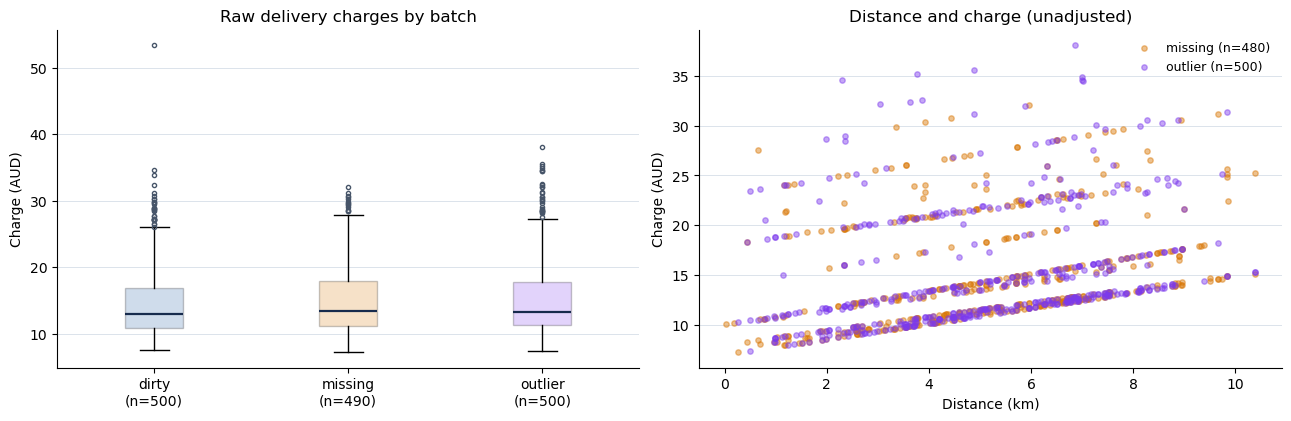

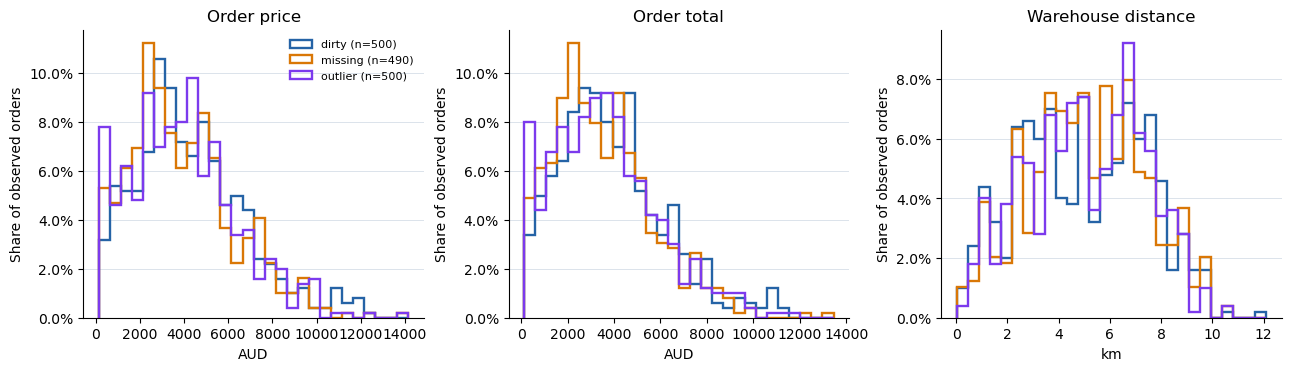

In [9]:
# Task 1.0: inspect raw strings, identities, blanks, domains and distributions.
# The helper is read-only: no repairs or imputation happen in this section.
from group005_eda_scaling import initial_eda
eda = initial_eda({"dirty": dirty, "missing": missing, "outlier": outlier}, warehouses)

**Figure EDA-1.** Raw delivery charges by batch and their unadjusted relationship with distance. Boxplot labels report nonblank charge counts; the scatter legend reports orders with both distance and charge observed. The dirty batch is omitted from the scatter because either field may be corrupted. A high raw charge is not, by itself, an outlier decision; conditional modelling and residual checks follow under *Seasonal delivery-charge model* and *1.3 Outlier data*.

**Figure EDA-2.** Raw order-price, order-total and warehouse-distance distributions. Each histogram uses the same bins across batches for that attribute and shows the percentage of observed orders in each bin. For each attribute, the observed counts are dirty 500, missing 490 and outlier 500; blank values are excluded. These plots describe the uncleaned inputs, not validated final values.

#### Key findings and implications for cleaning

All three inputs have 500 rows and the same 16-field order schema. Within and across batches, order IDs are unique; therefore `order_id` is a safe repair/audit key, while `customer_id` is a grouping key and may repeat. The CSVs are first read as strings so blank cells and original spellings remain distinguishable from conversions or repairs. The tables above check cart structure and numeric parseability as well as keys.

The missing batch has 80 blank cells in 80 different orders: ten each in warehouse, order price, charge, total, season, expedited flag, distance and happiness. The dirty and outlier batches have no blanks. This is an *investigation*, not the Task 1.2 filling work; those 80 decisions need separate row-level evidence and audit records.

Exact category counts expose eight non-canonical warehouse names in the dirty batch (`Baker's`, `Nickolsen`, `THOMPSON WH`) while the other observed warehouse names match the reference table. The dirty latitude range includes positive values despite the negative-latitude Melbourne cluster, which is a sign-error candidate, not grounds for blindly changing every extreme coordinate. Seasons and boolean fields should be checked against their allowed domains; a blank is distinct from an invalid nonblank value.

Figure EDA-2 shows right-tailed order prices and totals, while warehouse distances have medians near 5 km in all three batches and are mostly between roughly 2 and 8 km. These raw order-level shapes are descriptive; they do not establish that later customer-level attributes are already clean or well scaled.

The numeric table and plots describe *raw*, not verified, values. Prices, totals and delivery charges are on very different scales; neither a high charge nor a boxplot point alone proves an outlier because distance, season, coupon and expedited status affect expected charge. Accordingly later sections infer product prices only from guaranteed-correct outlier-batch order prices, fit and validate the seasonal charge relationship on eligible non-outlier rows, and judge outlier charges by residuals rather than an unconditional threshold. The dirty batch must not train those relationships until repaired. All Task 3 customer-level analysis must use the three final cleaned outputs, never these raw exploratory frames.

### Current unit prices (spec 3.1)

A product has one current unit price across the three batches, so every order
is a linear equation in those prices: the cart quantities are the coefficients
and `order_price` is the right-hand side.

The equations must come from orders whose cart **and** `order_price` are both
trustworthy. The outlier batch is the only batch that guarantees this: the
batch guarantees state it contains anomalous `delivery_charges` only, with no
missing values and no other corrupted fields. The dirty batch is unusable as a
source because `order_price` may itself be the corrupted field, and the missing
batch has ten orders with no `order_price` at all.

The A1 catalogue prices and any other group's inferred prices are not used
anywhere in this notebook. Spec 3.1 says they are not authoritative for A2, so
every price below is derived only from this group's own A2 equations.

We solve on a seeded 60% of the outlier batch and keep the remaining 40% as
unused equations, so the check below is genuinely held out.

In [10]:
def parse_cart(cart_json):
    """Parse one shopping_cart cell into a list of {product, quantity} dicts.

    Uses a JSON parser, never eval. Raises ValueError on any malformed cell,
    including an empty cart, rather than returning something that would quietly
    turn into an all-zero equation row with a non-zero order_price.
    """
    items = json.loads(cart_json)
    if not isinstance(items, list) or not items:
        raise ValueError(f"shopping_cart is not a non-empty JSON array: {cart_json!r}")
    for item in items:
        if not isinstance(item, dict) or set(item) != {"product", "quantity"}:
            raise ValueError(f"unexpected cart entry: {item!r}")
        if not isinstance(item["product"], str) or not item["product"].strip():
            raise ValueError(f"product is not a non-empty string: {item!r}")
        quantity = item["quantity"]
        # bool is a subclass of int, so True would otherwise pass as quantity 1.
        if isinstance(quantity, bool) or not isinstance(quantity, int) or quantity <= 0:
            raise ValueError(f"quantity is not a positive integer: {item!r}")
    return items


def cart_items(df):
    """Explode a batch into a tidy frame of order_id, product, quantity."""
    rows = []
    for order_id, cart_json in zip(df["order_id"], df["shopping_cart"]):
        for item in parse_cart(cart_json):
            rows.append((order_id, item["product"], item["quantity"]))
    return pd.DataFrame(rows, columns=["order_id", "product", "quantity"])


# Every cart in all three batches parses, and the product vocabulary is shared.
catalogue = {name: set(cart_items(df)["product"])
             for name, df in [("dirty", dirty), ("missing", missing),
                              ("outlier", outlier)]}
print("distinct products per batch:",
      {k: len(v) for k, v in catalogue.items()})
print("all three batches share one vocabulary:",
      catalogue["dirty"] == catalogue["missing"] == catalogue["outlier"])

outlier_items = cart_items(outlier)
print("\norders containing each product:")
print(outlier_items.groupby("product")["order_id"].nunique()
      .sort_values().to_string())

distinct products per batch: {'dirty': 12, 'missing': 12, 'outlier': 12}
all three batches share one vocabulary: True

orders containing each product:
product
Candle Flux 1098      82
Candle Bloom 262      91
Candle Bloom 1000    105
Candle Flux 990      112
Candle Orbit 656     118
Candle Edge 680      122
Candle Quest 498     122
Candle Quest 354     124
Candle Bloom 1054    134
Candle Orbit 1034    165
Vela Halo 659        165
Vela Halo 569        175


In [11]:
def infer_price_vector(items, order_prices, expected_products=None):
    """Solve for one current unit price per product.

    Returns (prices, diagnostics). The diagnostics report the rank, any thinly
    observed product, and (when expected_products is given) any product the
    equations never mention, rather than silently returning a vector that
    cannot price every cart.
    """
    design = items.pivot_table(index="order_id", columns="product",
                               values="quantity", aggfunc="sum",
                               fill_value=0).sort_index()
    target = pd.to_numeric(order_prices).reindex(design.index)
    if target.isna().any():
        raise ValueError("every order used to solve must carry an order_price")

    matrix = design.to_numpy(dtype=float)
    observed = target.to_numpy(dtype=float)
    rank = int(np.linalg.matrix_rank(matrix))
    raw = np.linalg.lstsq(matrix, observed, rcond=None)[0]
    # Computed directly: lstsq returns an empty residual array when the system
    # is rank deficient, and reporting that as 0.0 would read as a perfect fit.
    residual = float(np.sum((matrix @ raw - observed) ** 2))

    # float() so the built-in round applies, the convention the source data
    # follows; NumPy's float64 rounds half cents differently.
    prices = {p: round(float(v), 2) for p, v in zip(design.columns, raw)}
    appearances = items.groupby("product")["order_id"].nunique().to_dict()
    diagnostics = {
        "equations": int(matrix.shape[0]),
        "products": int(matrix.shape[1]),
        "rank": rank,
        "full_rank": rank == matrix.shape[1],
        "sparse_products": sorted(p for p, n in appearances.items() if n < 3),
        "max_snap_distance": max(abs(v - prices[p])
                                 for p, v in zip(design.columns, raw)),
        "unpriced_products": sorted(set(expected_products or ())
                                    - set(design.columns)),
        "lstsq_residual": residual,
    }
    return prices, diagnostics


# Seeded 60 / 40 split of the outlier batch: solve on one part, verify on the
# other. Splitting on order_id keeps whole equations on one side or the other.
ids = np.array(sorted(outlier.order_id.unique()))
np.random.default_rng(RANDOM_SEED).shuffle(ids)
solve_ids = set(ids[:int(len(ids) * 0.6)])
holdout_ids = set(ids[int(len(ids) * 0.6):])

solve_rows = outlier[outlier.order_id.isin(solve_ids)]
prices, diagnostics = infer_price_vector(
    outlier_items[outlier_items.order_id.isin(solve_ids)],
    solve_rows.set_index("order_id").order_price,
    expected_products=set().union(*catalogue.values()))

# Fail loudly on Run All if the equations ever stop identifying every price.
assert diagnostics["full_rank"] and not diagnostics["unpriced_products"], diagnostics

for key, value in diagnostics.items():
    print(f"  {key:20s} {value}")
print("\ninferred current unit prices (AUD):")
print(pd.Series(prices).sort_values().to_string())

  equations            300
  products             12
  rank                 12
  full_rank            True
  sparse_products      []
  max_snap_distance    4.604316927725449e-12
  unpriced_products    []
  lstsq_residual       1.5765791056622214e-20

inferred current unit prices (AUD):
Vela Halo 569         149.09
Vela Halo 659         264.71
Candle Quest 354      402.78
Candle Bloom 1054     449.85
Candle Orbit 1034     581.92
Candle Flux 1098      796.24
Candle Bloom 262     1118.27
Candle Quest 498     1308.33
Candle Bloom 1000    1815.84
Candle Flux 990      2094.45
Candle Edge 680      2251.40
Candle Orbit 656     2262.06


The system is comfortably over-determined: 300 equations for 12 unknowns, at
full rank, with no product seen in fewer than three orders and no product
from any of the three batches left without a price. Two numbers matter
more than the fit itself.

The least-squares residual (the sum of squared errors, computed directly from
the solution) is of order `1e-20`, which is about `6e-12` AUD per equation:
floating-point noise at the scale of these prices rather than "small". The
equations are therefore exactly consistent, so the per-item rounding in spec
3.2 is a no-op here: the prices are exact two-decimal amounts. The snap distance confirms this independently, at around `1e-12`
between each raw solution and its rounded value. Had either number been larger
we would be looking at an approximation and would have to justify it; instead
we are recovering an exact price vector.

R-squared style goodness of fit is not the evidence for these prices. The
evidence is whether they reproduce `order_price` under the published rule, on
equations that were not used to derive them.

What the equations look like. Each order contributes one row: the left side is
its cart (quantity times the unknown unit price, summed over its items) and the
right side is the `order_price` recorded in the file. The cell below picks one
order with 1, 2 and 3 cart items from the solving set, writes each as an
equation in the unknown prices, then substitutes the solved prices using the
spec 3.2 rounding to show the arithmetic closing. These are the equations the
system was solved on, so this illustrates the method; the held-out check further
down is the evidence.

In [12]:
# Three concrete equations, chosen by cart length so the structure is visible.
solve_by_id = solve_rows.set_index("order_id")

for n_items in (1, 2, 3):
    candidates = [o for o in sorted(solve_ids)
                  if len(parse_cart(solve_by_id.loc[o, "shopping_cart"])) == n_items]
    if not candidates:
        continue
    order_id = candidates[0]
    cart = parse_cart(solve_by_id.loc[order_id, "shopping_cart"])
    observed = float(solve_by_id.loc[order_id, "order_price"])

    amounts = [round(prices[i["product"]] * i["quantity"], 2) for i in cart]
    total = round(sum(amounts), 2)
    assert total == observed, (order_id, total, observed)

    print(f"{order_id}  ({n_items} item{'s' if n_items > 1 else ''})")
    print("  equation :", " + ".join(f"{i['quantity']} x p[{i['product']}]"
                                      for i in cart), f"= {observed}")
    print("  solved   :", " + ".join(f"{i['quantity']} x {prices[i['product']]:.2f}"
                                      for i in cart))
    print("           :", " + ".join(f"{a:.2f}" for a in amounts), f"= {total:.2f}\n")

CORD001004  (1 item)
  equation : 1 x p[Candle Flux 1098] = 796.24
  solved   : 1 x 796.24
           : 796.24 = 796.24

CORD001002  (2 items)
  equation : 1 x p[Vela Halo 659] + 1 x p[Candle Quest 354] = 667.49
  solved   : 1 x 264.71 + 1 x 402.78
           : 264.71 + 402.78 = 667.49

CORD001017  (3 items)
  equation : 2 x p[Candle Orbit 656] + 1 x p[Candle Bloom 1054] + 1 x p[Vela Halo 659] = 5238.68
  solved   : 2 x 2262.06 + 1 x 449.85 + 1 x 264.71
           : 4524.12 + 449.85 + 264.71 = 5238.68



In [13]:
def compute_order_price(cart, prices):
    """Spec 3.2 step 1: round each item amount to 2 dp, sum, round to 2 dp.

    Prices are cast to float so the built-in round applies even when a NumPy
    value is passed in.
    """
    subtotal = 0.0
    for item in cart:
        subtotal += round(float(prices[item["product"]]) * item["quantity"], 2)
    return round(subtotal, 2)


def verify_price_vector(prices, df):
    """Reproduce order_price with the spec 3.2 rule on the given orders.

    Evidence must come from the published rule, not from the least-squares
    residual. Returns (summary, mismatches).
    """
    matched, mismatches, unknown = 0, [], set()
    for order_id, cart_json, observed in zip(
            df["order_id"], df["shopping_cart"],
            pd.to_numeric(df["order_price"])):
        cart = parse_cart(cart_json)
        absent = {i["product"] for i in cart} - set(prices)
        if absent:
            unknown |= absent
            mismatches.append((order_id, None, float(observed)))
            continue
        expected = compute_order_price(cart, prices)
        if expected == float(observed):
            matched += 1
        else:
            mismatches.append((order_id, expected, float(observed)))
    return ({"orders": len(df), "matched": matched,
             "unknown_products": sorted(unknown)}, mismatches)


checks = [
    ("outlier, held-out 40% (unused equations)",
     outlier[outlier.order_id.isin(holdout_ids)]),
    ("outlier, all 500 orders", outlier),
    ("missing batch, the 490 orders that carry an order_price",
     missing[missing.order_price != ""]),
]
for label, frame in checks:
    summary, _ = verify_price_vector(prices, frame)
    print(f"  {summary['matched']:3d}/{summary['orders']:3d}   {label}")
    if summary["unknown_products"]:
        print(f"        unpriced products: {summary['unknown_products']}")

  200/200   outlier, held-out 40% (unused equations)
  500/500   outlier, all 500 orders
  490/490   missing batch, the 490 orders that carry an order_price


### Totals and the rounding convention (spec 3.2)

The missing batch is an independent source: it shares no orders with the
outlier batch the prices were derived from, and the batch guarantees state its
non-missing values are correct. Reproducing 490 of its `order_price` values
exactly is therefore stronger evidence than any in-sample statistic.

Applying the same rule to `order_total` exposed a subtlety. Our first
implementation used `Decimal` with `ROUND_HALF_UP`, on the reasoning that
currency should not use banker's rounding. It reproduced only 412 of the 420
fully complete rows in the missing batch — rows the batch guarantees are
correct. All eight disagreements were exactly one cent high.

The cause is representation, not arithmetic. For order CORD000526,
`5309.70 * 0.85 + 14.61` is 4527.855 as a decimal, but the nearest double lies
just below it, so Python's `round` returns 4527.85 while `Decimal` returns
4527.86. The supplied data was produced with plain float arithmetic, and the
cell below compares these conventions against the guaranteed-correct rows.

We follow the source. This matters beyond the marking tolerance in spec 5:
a stricter rule would make our own validation flag eight valid rows as
inconsistent, and the dirty-batch diagnosis would then chase corruption that
does not exist.

One consequence applies to every later block. pandas `Series.round(2)` and
`np.round` use NumPy's rounding, which disagrees with the built-in `round` on
values that sit exactly on a half cent, so the same formula written in vector
form misses guaranteed-correct rows (the NumPy line in the comparison below).
Totals are therefore always computed row by row with `compute_order_total`,
never with `.round(2)` on a column; otherwise valid rows would look corrupted.


In [14]:
from decimal import Decimal, ROUND_HALF_UP, ROUND_HALF_EVEN


def compute_order_total(order_price, coupon_discount, delivery_charges):
    """round(order_price * (1 - coupon_discount / 100) + delivery_charges, 2).

    The discounted subtotal is not rounded separately before delivery is added.
    Call it row by row: pandas .round(2) and np.round round half cents the NumPy
    way and disagree with the source on some guaranteed-correct rows, as the
    comparison below shows.
    """
    discounted = float(order_price) * (1 - float(coupon_discount) / 100)
    return round(discounted + float(delivery_charges), 2)


# The worked example printed in spec 3.2: AUD 100 of items, a 10% coupon and AUD 8
# delivery gives AUD 98. A 50% coupon on the same order must leave the delivery
# charge untouched, because the coupon applies to the item price only.
assert compute_order_total(100, 10, 8) == 98.0
assert compute_order_total(100, 50, 8) == 58.0


def _total_with(rounding, order_price, coupon_discount, delivery_charges):
    """The same formula under an explicit Decimal rounding mode."""
    discounted = (Decimal(str(order_price))
                  * (1 - Decimal(str(coupon_discount)) / 100))
    return float((discounted + Decimal(str(delivery_charges)))
                 .quantize(Decimal("0.01"), rounding=rounding))


complete = missing[(missing.drop(columns="source_batch") == "").sum(axis=1) == 0]
print(f"fully complete rows in the missing batch: {len(complete)}\n")

conventions = {
    "float + built-in round (adopted)":
        lambda r: compute_order_total(r.order_price, r.coupon_discount,
                                      r.delivery_charges),
    "Decimal ROUND_HALF_UP":
        lambda r: _total_with(ROUND_HALF_UP, r.order_price, r.coupon_discount,
                              r.delivery_charges),
    "NumPy round (what pandas .round(2) uses)":
        lambda r: float(np.round(float(r.order_price)
                                 * (1 - float(r.coupon_discount) / 100)
                                 + float(r.delivery_charges), 2)),
    "Decimal ROUND_HALF_EVEN":
        lambda r: _total_with(ROUND_HALF_EVEN, r.order_price,
                              r.coupon_discount, r.delivery_charges),
}
for label, rule in conventions.items():
    agree = sum(rule(row) == float(row.order_total)
                for row in complete.itertuples())
    print(f"  {agree:3d}/{len(complete)}   {label}")

# Read the first disagreeing row out of the data rather than transcribing it,
# so the worked example reproduces on a fresh run and nothing is hard coded.
disagreeing = [r for r in complete.itertuples()
               if compute_order_total(r.order_price, r.coupon_discount,
                                      r.delivery_charges)
               != _total_with(ROUND_HALF_UP, r.order_price, r.coupon_discount,
                              r.delivery_charges)]
row = disagreeing[0]
exact = (float(row.order_price) * (1 - float(row.coupon_discount) / 100)
         + float(row.delivery_charges))
print(f"\nworked example {row.order_id}: the double holds {exact!r}")
print(f"  built-in round  -> {round(exact, 2)}")
print(f"  Decimal HALF_UP -> {_total_with(ROUND_HALF_UP, row.order_price, row.coupon_discount, row.delivery_charges)}")
print(f"  file records    -> {float(row.order_total)}")


fully complete rows in the missing batch: 420

  420/420   float + built-in round (adopted)
  412/420   Decimal ROUND_HALF_UP
  416/420   NumPy round (what pandas .round(2) uses)
  411/420   Decimal ROUND_HALF_EVEN

worked example CORD000526: the double holds 4527.855
  built-in round  -> 4527.85
  Decimal HALF_UP -> 4527.86
  file records    -> 4527.85


### Location: haversine distance and nearest warehouse (spec 3.3)

`distance_to_nearest_warehouse` is the great-circle (haversine) distance from
the customer to the closest of the three warehouses in `warehouses.csv`, with an
Earth radius of 6,371 km. `nearest_warehouse` is the name of that closest
warehouse. Both are therefore *derived* from `customer_lat` and
`customer_long`, which is what lets us check them.

Before relying on a distance we check that the coordinates are consistent with
Melbourne. The plausibility box below is deliberately generous (roughly Greater
Melbourne). It is not tuned to the data: the evidence printed underneath is the
observed coordinate range in each batch, and a coordinate that fails the box
fails it by thousands of kilometres rather than by a borderline margin.

In [15]:
EARTH_RADIUS_KM = 6371.0

# Greater Melbourne, deliberately generous. It only needs to separate a real
# Melbourne address from one that is not in Melbourne at all.
MELBOURNE_LAT = (-38.5, -37.4)
MELBOURNE_LONG = (144.4, 145.6)


def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in km using EARTH_RADIUS_KM."""
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    d_phi = phi2 - phi1
    d_lambda = math.radians(lon2 - lon1)
    a = (math.sin(d_phi / 2) ** 2
         + math.cos(phi1) * math.cos(phi2) * math.sin(d_lambda / 2) ** 2)
    return 2 * EARTH_RADIUS_KM * math.asin(math.sqrt(a))


def warehouse_distances(lat, lon, warehouses=warehouses):
    """Unrounded distance from one customer to every warehouse."""
    return {name: haversine_km(float(lat), float(lon), w_lat, w_lon)
            for name, w_lat, w_lon in zip(warehouses.warehouse,
                                          warehouses.latitude,
                                          warehouses.longitude)}


def nearest_warehouse(lat, lon, warehouses=warehouses):
    """Return (warehouse_name, distance_km) for the smallest haversine distance.

    Distances are compared at full precision; only the reported distance is
    rounded, to four decimal places.
    """
    distances = warehouse_distances(lat, lon, warehouses)
    name = min(distances, key=distances.get)
    return name, round(distances[name], 4)


def coordinates_plausible(lat, lon):
    """True when the coordinates are consistent with Melbourne."""
    lat, lon = float(lat), float(lon)
    return (MELBOURNE_LAT[0] <= lat <= MELBOURNE_LAT[1]
            and MELBOURNE_LONG[0] <= lon <= MELBOURNE_LONG[1])


print("observed coordinate ranges (non-empty cells):")
for name, df in [("dirty", dirty), ("missing", missing), ("outlier", outlier)]:
    lat = pd.to_numeric(df.customer_lat.replace("", np.nan))
    lon = pd.to_numeric(df.customer_long.replace("", np.nan))
    implausible = sum(not coordinates_plausible(a, b)
                      for a, b in zip(lat, lon) if pd.notna(a) and pd.notna(b))
    print(f"  {name:8s} lat [{lat.min():.6f}, {lat.max():.6f}]  "
          f"long [{lon.min():.6f}, {lon.max():.6f}]  "
          f"outside Melbourne: {implausible}")

# How close is the closest call? If the runner-up warehouse is only metres
# further away, rounding coordinates or distances too early could change which
# warehouse is nearest.
guaranteed = pd.concat([outlier, complete])
margins = []
for order_id, lat, lon in zip(guaranteed.order_id, guaranteed.customer_lat,
                              guaranteed.customer_long):
    first, second = sorted(warehouse_distances(lat, lon).values())[:2]
    margins.append((second - first, order_id))
gap, gap_id = min(margins)
print(f"\nsmallest nearest/runner-up gap: {gap * 1000:.2f} m ({gap_id})")

observed coordinate ranges (non-empty cells):
  dirty    lat [-37.888622, 37.885145]  long [144.875300, 145.064883]  outside Melbourne: 8
  missing  lat [-37.888397, -37.739267]  long [144.875300, 145.064883]  outside Melbourne: 0
  outlier  lat [-37.888622, -37.739267]  long [144.875300, 145.064883]  outside Melbourne: 0

smallest nearest/runner-up gap: 0.75 m (CORD001326)


The outlier batch and the missing batch, whose location fields the batch
guarantees say are correct wherever present, sit entirely inside the box. The
dirty batch has eight coordinates outside it. Its maximum latitude is
`+37.885145`, the mirror image of a Melbourne latitude: the sign has been lost.
The batch guarantees also rule out the longitude as the culprit, because
`customer_long` is complete and error-free in all three batches.

The sign flip also changes the distance and the nearest warehouse computed from
that row, so all three checks fail at once. Following the spec, only one field
in a dirty row is wrong. These rows need the latitude restored; the stored
distance and warehouse should then agree again without being edited. That
diagnosis belongs to section 1.1, which can call these functions.

The smallest nearest/runner-up gap is under a metre. This is why
`nearest_warehouse` compares distances at full precision and only rounds the
distance it reports: rounding coordinates or distances first could pick the
wrong warehouse for that order.

### Dates and seasons (spec 3.3)

The spec fixes how each date layout is read: a slash-formatted
day/month/year value is **day first**, and a year-first value keeps its
year-first reading. Letting a library guess the layout would break this, since
a value like `04/05/2019` can be parsed month first. Instead we list every raw
layout found in the three batches and give each its one published
interpretation. An unrecognised layout raises an error instead of being guessed.

Season then follows the Australian calendar-month table in spec 3.3.

In [16]:
import re
from datetime import datetime

# Every raw layout observed in the three batches, with its one published
# reading. %b expects English month abbreviations.
DATE_LAYOUTS = {
    r"\d{4}-\d{2}-\d{2}": "%Y-%m-%d",          # standard output format
    r"\d{4}/\d{2}/\d{2}": "%Y/%m/%d",          # year first keeps year first
    r"\d{1,2}/\d{1,2}/\d{4}": "%d/%m/%Y",      # slash day/month/year: day first
    r"[A-Za-z]{3} \d{1,2}, \d{4}": "%b %d, %Y",
}

SEASON_BY_MONTH = {12: "Summer", 1: "Summer", 2: "Summer",
                   3: "Autumn", 4: "Autumn", 5: "Autumn",
                   6: "Winter", 7: "Winter", 8: "Winter",
                   9: "Spring", 10: "Spring", 11: "Spring"}


def parse_order_date(raw):
    """Return YYYY-MM-DD.

    A slash-formatted day/month/year value is day first; a year-first form
    retains its year-first interpretation.
    """
    text = str(raw).strip()
    for pattern, layout in DATE_LAYOUTS.items():
        if re.fullmatch(pattern, text):
            return datetime.strptime(text, layout).strftime("%Y-%m-%d")
    raise ValueError(f"unrecognised date layout: {raw!r}")


def season_of(date_iso):
    """Australian season from the calendar month (spec 3.3 table)."""
    return SEASON_BY_MONTH[int(date_iso[5:7])]


def date_shape(raw):
    """The layout of a raw date with digits masked, e.g. 9999-99-99."""
    return re.sub(r"\d", "9", raw)


print("raw date layouts per batch:")
for name, df in [("dirty", dirty), ("missing", missing), ("outlier", outlier)]:
    counts = df.date.map(date_shape).value_counts()
    print(f"  {name:8s}", {k: int(v) for k, v in counts.items()})

# Every non-standard date, with its parse. For a day-first slash date we also
# show what a month-first reading would have implied, and whether the stored
# season supports the published day-first reading.
rows = []
for r in dirty[dirty.date.map(date_shape) != "9999-99-99"].itertuples():
    iso = parse_order_date(r.date)
    month_first = ""
    if re.fullmatch(r"\d{1,2}/\d{1,2}/\d{4}", r.date):
        try:
            alt = datetime.strptime(r.date, "%m/%d/%Y").strftime("%Y-%m-%d")
            month_first = f"{alt} ({season_of(alt)})" if alt != iso else "same"
        except ValueError:
            month_first = "impossible"
    rows.append({"order_id": r.order_id, "raw": r.date, "parsed": iso,
                 "season_of_parsed": season_of(iso), "stored_season": r.season,
                 "month_first_reading": month_first})
print()
print(pd.DataFrame(rows).to_string(index=False))

parsed_all = pd.concat([dirty.date, missing.date, outlier.date]).map(parse_order_date)
print(f"\nall 1,500 raw dates parse; calendar range "
      f"{parsed_all.min()} to {parsed_all.max()}")
for name, df in [("outlier", outlier), ("missing (season present)",
                                        missing[missing.season != ""])]:
    agree = sum(season_of(parse_order_date(d)) == s
                for d, s in zip(df.date, df.season))
    print(f"  season agrees with date: {agree:3d}/{len(df)}   {name}")

raw date layouts per batch:
  dirty    {'9999-99-99': 492, '9999/99/99': 3, '99/99/9999': 3, 'Nov 99, 9999': 1, 'Sep 99, 9999': 1}
  missing  {'9999-99-99': 500}
  outlier  {'9999-99-99': 500}

  order_id          raw     parsed season_of_parsed stored_season month_first_reading
CORD000028   2019/12/30 2019-12-30           Summer        Summer                    
CORD000056 Nov 12, 2019 2019-11-12           Spring        Spring                    
CORD000106   2019/07/05 2019-07-05           Winter        Winter                    
CORD000150   23/04/2019 2019-04-23           Autumn        Autumn          impossible
CORD000168   04/04/2019 2019-04-04           Autumn        Autumn                same
CORD000242 Sep 30, 2019 2019-09-30           Spring        Spring                    
CORD000366   11/05/2019 2019-05-11           Autumn        Autumn 2019-11-05 (Spring)
CORD000409   2019/10/20 2019-10-20           Spring        Spring                    

all 1,500 raw dates parse; cale

The missing and outlier batches store every date in the standard layout, and
the season agrees with the date on every row that has one. The dirty batch has
eight dates in three other layouts. These are representation problems: each
parses to one calendar date under the published rule, and in every case the
stored season agrees with that date. For the day-first slash dates, the
`month_first_reading` column shows why the published rule matters. `11/05/2019`
read month first would be a Spring date, but the stored season is Autumn, which
agrees with the day-first reading (11 May).

A date that is already in the standard layout but disagrees with its season
is a different problem. Either field could be the corrupted one. Section 1.1
must resolve that with independent evidence rather than by assuming the date is
right.

### Prior-review happiness (spec 3.4)

`is_happy_customer` is derived from `latest_customer_review` by NLTK VADER:
`True` when the compound score is at least 0.05. The spec freezes this
resource. We must use NLTK 3.9.2 and the package-local lexicon, verify its
checksum against `resource_contract.json`, and never download a substitute.
`configure_vader` enforces all three before returning an analyser, and points
NLTK *only* at the package-local directory, so a lexicon installed elsewhere on
the machine cannot be picked up by accident.

The exact text `No review submitted` is a documented sentinel meaning "no prior
review", and the rule gives it `is_happy_customer = True`. Scoring the sentinel
with VADER would not give that answer, so `is_happy` intercepts it before
scoring. Reviews are otherwise scored exactly as supplied, with no case folding,
punctuation removal or translation.

In [17]:
import hashlib

import nltk

NO_REVIEW_SENTINEL = "No review submitted"


def configure_vader(nltk_data_dir=NLTK_DATA_DIR, contract_path=RESOURCE_CONTRACT):
    """Verify the frozen resource and return (analyser, contract).

    Checks the NLTK version and the lexicon checksum against the contract, then
    loads only the package-local resource. Nothing is downloaded.
    """
    contract = json.loads(Path(contract_path).read_text())
    if nltk.__version__ != contract["nltk_version"]:
        raise RuntimeError(f"NLTK {nltk.__version__} installed, contract "
                           f"requires {contract['nltk_version']}")
    lexicon = DATA_DIR / contract["vader_lexicon_relative_path"]
    digest = hashlib.sha256(lexicon.read_bytes()).hexdigest()
    if digest != contract["vader_lexicon_sha256"]:
        raise RuntimeError(f"lexicon checksum mismatch: {digest}")

    nltk.data.path[:] = [str(Path(nltk_data_dir).resolve())]
    from nltk.sentiment.vader import SentimentIntensityAnalyzer
    return SentimentIntensityAnalyzer(), contract


def is_happy(review, analyser, threshold=0.05):
    """True when the VADER compound score is >= threshold.

    The no-prior-review sentinel is intercepted first and is always True.
    The review is scored exactly as supplied.
    """
    if review == NO_REVIEW_SENTINEL:
        return True
    return analyser.polarity_scores(review)["compound"] >= threshold


analyser, contract = configure_vader()
HAPPY_THRESHOLD = contract["compound_threshold"]
print(f"NLTK {nltk.__version__} (contract {contract['nltk_version']}), "
      f"lexicon checksum verified")
# The file NLTK actually loads must be the one whose checksum was verified.
# Paths are compared resolved and printed as configured, so this also works
# when DATA_DIR points outside the working directory.
lexicon_path = DATA_DIR / contract["vader_lexicon_relative_path"]
loaded_from = Path(nltk.data.find("sentiment/vader_lexicon.zip").zipfile.filename)
assert loaded_from.resolve() == lexicon_path.resolve(), (loaded_from, lexicon_path)
print("lexicon loaded from:", lexicon_path)
print(f"compound threshold: {HAPPY_THRESHOLD}")
print(f"raw VADER score of the sentinel: "
      f"{analyser.polarity_scores(NO_REVIEW_SENTINEL)['compound']}  "
      f"-> is_happy returns {is_happy(NO_REVIEW_SENTINEL, analyser, HAPPY_THRESHOLD)}")

compound = {}
for df in (dirty, missing, outlier):
    for order_id, review in zip(df.order_id, df.latest_customer_review):
        if review != NO_REVIEW_SENTINEL:
            compound[order_id] = analyser.polarity_scores(review)["compound"]
sentinels = sum((df.latest_customer_review == NO_REVIEW_SENTINEL).sum()
                for df in (dirty, missing, outlier))
closest = min(compound, key=lambda k: abs(compound[k] - HAPPY_THRESHOLD))
print(f"\nsentinel reviews across the three batches: {sentinels}")
print(f"score closest to the threshold: {compound[closest]} ({closest})")

print("\nrecomputed happiness against the stored flag:")
disagreements = {}
for name, df in [("outlier", outlier), ("missing (flag present)",
                                        missing[missing.is_happy_customer != ""]),
                 ("dirty", dirty)]:
    wrong = [(order_id, compound[order_id], flag)
             for order_id, review, flag in zip(df.order_id,
                                               df.latest_customer_review,
                                               df.is_happy_customer)
             if is_happy(review, analyser, HAPPY_THRESHOLD) != (flag == "True")]
    disagreements[name] = wrong
    print(f"  {len(df) - len(wrong):3d}/{len(df)}   {name}")
print("\ndirty-batch disagreements (order, compound, stored flag):")
for row in disagreements["dirty"]:
    print("  ", row)

NLTK 3.9.2 (contract 3.9.2), lexicon checksum verified
lexicon loaded from: Group005_A2/resources/nltk_data/sentiment/vader_lexicon.zip
compound threshold: 0.05
raw VADER score of the sentinel: -0.296  -> is_happy returns True

sentinel reviews across the three batches: 0
score closest to the threshold: 0.0685 (CORD000186)

recomputed happiness against the stored flag:
  500/500   outlier
  490/490   missing (flag present)
  492/500   dirty

dirty-batch disagreements (order, compound, stored flag):
   ('CORD000002', -0.9834, 'True')
   ('CORD000062', 0.9158, 'False')
   ('CORD000105', 0.9841, 'False')
   ('CORD000163', 0.9896, 'False')
   ('CORD000275', 0.8929, 'False')
   ('CORD000327', -0.9442, 'True')
   ('CORD000483', -0.971, 'True')
   ('CORD000494', -0.9669, 'True')



sentinel reviews across the three batches: 0
score closest to the threshold: 0.0685 (CORD000186)

recomputed happiness against the stored flag:


  500/500   outlier


  490/490   missing (flag present)


  492/500   dirty

dirty-batch disagreements (order, compound, stored flag):
   ('CORD000002', -0.9834, 'True')
   ('CORD000062', 0.9158, 'False')
   ('CORD000105', 0.9841, 'False')
   ('CORD000163', 0.9896, 'False')
   ('CORD000275', 0.8929, 'False')
   ('CORD000327', -0.9442, 'True')
   ('CORD000483', -0.971, 'True')
   ('CORD000494', -0.9669, 'True')


The frozen rule reproduces the stored flag on every outlier-batch order and on
every missing-batch order where the flag is present. That confirms both the
resource configuration and the threshold direction on data the batch guarantees
say is correct. No review in any batch sits close enough to the threshold for
floating-point detail to matter, so agreement does not hinge on borderline
scores.

No batch actually contains the sentinel. We keep the interception anyway,
because it is a published rule: VADER scores the sentinel text as negative,
which would silently give the wrong answer if the sentinel ever appeared.

The eight dirty-batch disagreements are not borderline either. Each review is
strongly positive or strongly negative, and the stored flag says the opposite.
Since the review text is guaranteed error-free, the evidence points at
`is_happy_customer` itself. Section 1.1 can confirm this and repair the flag.

### Validating the shared rules on the outlier batch

The batch guarantees say the outlier batch has anomalous `delivery_charges`
only: no missing values and no other corrupted fields. So every rule above
should reproduce its stored values exactly. Any systematic disagreement would
mean a bug in our functions, not in the data. The fully complete rows of the
missing batch are an independent second check. The batch guarantees say they
are correct, and they share no orders with the outlier batch.

`check_shared_rules` returns one boolean per rule per order, where `True` means
the stored value agrees with the published rule. It is written for any complete
batch so sections 1.1 to 1.3 can reuse it.

In [18]:
def check_shared_rules(df):
    """One row per order, one boolean per published rule (True = agrees).

    Needs a batch with no empty cells in the fields it recomputes.
    """
    rows = []
    for r in df.itertuples(index=False):
        iso = parse_order_date(r.date)
        name, distance = nearest_warehouse(r.customer_lat, r.customer_long)
        rows.append({
            "order_id": r.order_id,
            "date_standard": r.date == iso,
            "season": season_of(iso) == r.season,
            "location_plausible": coordinates_plausible(r.customer_lat,
                                                        r.customer_long),
            "nearest_warehouse": name == r.nearest_warehouse,
            "distance": distance == float(r.distance_to_nearest_warehouse),
            "happiness": (is_happy(r.latest_customer_review, analyser,
                                   HAPPY_THRESHOLD)
                          == (r.is_happy_customer == "True")),
            "order_price": (compute_order_price(parse_cart(r.shopping_cart),
                                                prices)
                            == float(r.order_price)),
            "order_total": (compute_order_total(r.order_price, r.coupon_discount,
                                                r.delivery_charges)
                            == float(r.order_total)),
        })
    return pd.DataFrame(rows).set_index("order_id")


outlier_checks = check_shared_rules(outlier)
complete_checks = check_shared_rules(complete)
summary = pd.DataFrame({
    f"outlier ({len(outlier_checks)})": outlier_checks.sum(),
    f"missing, complete rows ({len(complete_checks)})": complete_checks.sum(),
})
print("orders agreeing with each published rule:")
print(summary.to_string())

# The one rule that does not hold everywhere in the outlier batch.
failing = outlier_checks.index[~outlier_checks.order_total]
detail = outlier.set_index("order_id").loc[failing]
discounted = (detail.order_price.astype(float)
              * (1 - detail.coupon_discount.astype(float) / 100))
implied = pd.DataFrame({
    "delivery_charges": detail.delivery_charges.astype(float),
    "order_total": detail.order_total.astype(float),
    "charge_implied_by_total": (detail.order_total.astype(float)
                                - discounted).round(2),
})
implied["excess"] = (implied.delivery_charges
                     - implied.charge_implied_by_total).round(2)
print(f"\noutlier orders whose order_total disagrees: {len(failing)}")
print(implied.to_string())
print(f"\nstored charge above the charge implied by the total: "
      f"{(implied.excess > 0).sum()}/{len(implied)}")
print("distinct excess amounts:", sorted(implied.excess.unique()))

orders agreeing with each published rule:
                    outlier (500)  missing, complete rows (420)
date_standard                 500                           420
season                        500                           420
location_plausible            500                           420
nearest_warehouse             500                           420
distance                      500                           420
happiness                     500                           420
order_price                   500                           420
order_total                   476                           420

outlier orders whose order_total disagrees: 24
            delivery_charges  order_total  charge_implied_by_total  excess
order_id                                                                  
CORD001026             38.10       558.10                    23.35   14.75
CORD001036             28.47      3489.59                    22.22    6.25
CORD001049             21.90      

*Evidence summary for spec 3.3 and 3.4.* On all 500 outlier-batch orders and
all 420 complete missing-batch orders, the rules reproduce the stored date
layout, season, nearest warehouse, distance (exactly, to four decimal places),
happiness flag and `order_price`, and every coordinate is consistent with
Melbourne. None of these relationships involves `delivery_charges`, and none of
them fails.

The one relationship that does fail is `order_total`, on 24 outlier orders. It
is also the only rule in this list that uses `delivery_charges`, the one field
the batch guarantees say is anomalous there. In each of these rows the stored
charge is *higher* than the charge the stored total implies. This reads as the
total having been computed from the original charge before the charge was
altered. The excess is not arbitrary either: it takes only four distinct
values, which looks like a fixed amount added to the charge rather than noise.
This is strong, independent evidence that these 24 charges are
anomalous, and section 1.3 should weigh it alongside the seasonal-model
residuals. It is not a complete detector: an anomalous charge whose total was
altered consistently would pass this check. So the residual rule in section 1.3
remains the primary method. The complete missing-batch rows agree on every
rule, including `order_total`, which is consistent with this reading.

These functions are the shared basis for sections 1.1 to 1.3. Section 1.1 can
run `check_shared_rules` on the dirty batch to locate disagreeing fields. It
already has three findings to resolve from this section: eight latitudes with a
lost sign, eight non-standard date layouts and eight happiness flags that
contradict their review.

### Seasonal delivery-charge model (spec 3.5)

Delivery charge follows a separate linear tariff in each season:

$$\text{delivery\_charges} = \beta_0 + \beta_1\,\text{distance} + \beta_2\,\text{expedited} + \beta_3\,\text{happy} + \varepsilon$$

This section fits and evaluates the four models. Section 1.3 uses them to find the anomalous
charges. Labels such as DELIV-05 name each piece of evidence so the audit log can cite it.

#### Model inputs and constants

The model reads only the 16 supplied fields, so it works on `SCHEMA` copies of the three batches,
without the `source_batch` tag. These copies are never modified, so repairs made later in 1.1 and
1.2 cannot change a result here. Holding out 25% leaves about 25 test orders and 80 fitting rows
per season for four parameters. The cut-off 3.5 and the MAD-to-sigma constant 1.4826 are the
standard modified z-score values (Iglewicz and Hoaglin, 1993).

In [19]:
# The only fields the delivery model reads. Encoded copies stay inside this
# section; the output CSVs keep True/False.
SEASONS = ("Summer", "Autumn", "Winter", "Spring")
SCHEMA = [
    "order_id", "customer_id", "date", "nearest_warehouse", "shopping_cart",
    "order_price", "delivery_charges", "customer_lat", "customer_long",
    "coupon_discount", "order_total", "season", "is_expedited_delivery",
    "distance_to_nearest_warehouse", "latest_customer_review",
    "is_happy_customer",
]
DELIVERY_TARGET = "delivery_charges"
DELIVERY_PREDICTORS = [
    "distance_to_nearest_warehouse", "is_expedited_delivery", "is_happy_customer",
]
DELIVERY_BOOLEANS = ["is_expedited_delivery", "is_happy_customer"]
DELIVERY_HOLDOUT_FRACTION = 0.25   # about 25 held-out orders per season
MODIFIED_Z_CUTOFF = 3.5            # Iglewicz and Hoaglin (1993) outlier cut-off
MAD_TO_SIGMA = 1.4826              # MAD -> standard-deviation scale
DELIVERY_SPLIT = {}                # the recorded split, filled by fit_seasonal_models

In [20]:
dirty_raw = dirty[SCHEMA].copy()        # evidence only: never trained on, never changed
missing_raw = missing[SCHEMA].copy()
outlier_raw = outlier[SCHEMA].copy()

for name, df in (("missing", missing_raw), ("outlier", outlier_raw), ("dirty", dirty_raw)):
    assert list(df.columns) == SCHEMA and len(df) == 500 and df["order_id"].is_unique, name
    print(f"{name:8s} {df.shape[0]} rows x {df.shape[1]} cols | schema order OK | order_id unique")
print(f"RANDOM_SEED = {RANDOM_SEED} | SEASONS = {SEASONS}")

missing  500 rows x 16 cols | schema order OK | order_id unique
outlier  500 rows x 16 cols | schema order OK | order_id unique
dirty    500 rows x 16 cols | schema order OK | order_id unique
RANDOM_SEED = 5196 | SEASONS = ('Summer', 'Autumn', 'Winter', 'Spring')


#### Training rows - DELIV-01

Spec 3.5 asks for reliable complete observations. We train only on the 420 fully complete rows of
the missing batch, because the batch guarantees say its observed values are correct.

- The outlier batch is excluded. It holds the charges being judged, and training on them would pull
  the coefficients towards the anomalies.
- The dirty batch is excluded. Any of the five model fields may be its one wrong field, and it has
  not been repaired yet.

Also using the 30 rows that are complete on the model fields alone would move the coefficients by
less than AUD 0.001 (alternative (c) under Material alternatives), so the stricter choice costs nothing.

In [21]:
def _blank_mask(df):
    """True where a cell is empty: '' or whitespace in a string read, NaN otherwise."""
    return df.isna() | df.astype(str).apply(lambda col: col.str.strip() == "")


def select_training_rows(missing_df):
    """Return the rows of the missing batch with no empty field."""
    complete = ~_blank_mask(missing_df).any(axis=1)
    train = missing_df.loc[complete].copy()
    if not train["order_id"].is_unique:
        raise ValueError("training rows must have unique order_id values")
    absent = sorted(set(SEASONS) - set(train["season"]))
    if absent:
        raise ValueError(f"no complete training rows for season(s) {absent}")
    return train

In [22]:
train_df = select_training_rows(missing_raw)
blank = _blank_mask(missing_raw)
print(f"DELIV-01  missing batch: {len(missing_raw)} rows -> {len(train_df)} fully complete training rows")
print(f"          excluded {int(blank.any(axis=1).sum())} incomplete rows; empty cells per excluded row: "
      f"{sorted(set(blank.sum(axis=1)[blank.any(axis=1)]))}")
print("\nexcluded rows, by the one field that is empty:")
print(blank[blank.any(axis=1)].sum()[lambda s: s > 0].to_string())

sources = pd.DataFrame([
    (MISSING_INPUT.name, len(missing_raw), len(train_df), "observed cells guaranteed correct; complete rows only"),
    (OUTLIER_INPUT.name, len(outlier_raw), 0, "holds the anomalous charges that 1.3 judges"),
    (DIRTY_INPUT.name, len(dirty_raw), 0, "unrepaired: its one wrong field may be a model field"),
], columns=["source_file", "rows", "rows_used_for_training", "reason"])
print("\n" + sources.to_string(index=False))

num = train_df[["distance_to_nearest_warehouse", "delivery_charges"]].apply(pd.to_numeric)   # raw check, pre-encoding
profile = train_df.assign(**num).groupby("season").agg(
    n=("order_id", "size"),
    expedited=("is_expedited_delivery", lambda s: int((s == "True").sum())),
    unhappy=("is_happy_customer", lambda s: int((s == "False").sum())),
    distance_km_min=("distance_to_nearest_warehouse", "min"),
    distance_km_max=("distance_to_nearest_warehouse", "max"),
    charge_min=("delivery_charges", "min"),
    charge_max=("delivery_charges", "max"),
).reindex(list(SEASONS))
print("\ntraining composition by season:\n" + profile.round(3).to_string())

input_contract = {
    "season is one of the four published seasons": train_df["season"].isin(SEASONS).all(),
    "boolean fields are exactly True/False": train_df[DELIVERY_BOOLEANS].isin(["True", "False"]).all().all(),
    "distance numeric, within 0-20 km of a warehouse": num["distance_to_nearest_warehouse"].between(0, 20).all(),
    "delivery charge numeric and positive": (num["delivery_charges"] > 0).all(),
    "order_id unique": train_df["order_id"].is_unique,
}
print("\nDelivery-model input contract on the training rows:")
for check, passed in input_contract.items():
    print(f"  [{'PASS' if passed else 'FAIL'}] {check}")
assert all(input_contract.values())

# The same 420 rows that section 1.0 already checked against the season,
# distance, happiness and order-total rules (check_shared_rules: 420/420 each).
same_rows = set(train_df["order_id"]) == set(complete["order_id"])
print("\nsame 420 rows as the complete missing-batch rows checked in 1.0:", same_rows)
assert same_rows

DELIV-01  missing batch: 500 rows -> 420 fully complete training rows
          excluded 80 incomplete rows; empty cells per excluded row: [1]

excluded rows, by the one field that is empty:
nearest_warehouse                10
order_price                      10
delivery_charges                 10
order_total                      10
season                           10
is_expedited_delivery            10
distance_to_nearest_warehouse    10
is_happy_customer                10

              source_file  rows  rows_used_for_training                                                reason
Group005_missing_data.csv   500                     420 observed cells guaranteed correct; complete rows only
Group005_outlier_data.csv   500                       0           holds the anomalous charges that 1.3 judges
  Group005_dirty_data.csv   500                       0  unrepaired: its one wrong field may be a model field

training composition by season:
          n  expedited  unhappy  distance_km_mi

Each of the 80 excluded rows lacks exactly one field, 10 per field. Every season keeps 93–117 rows
with both levels of both flags.

#### Boolean encoding - DELIV-02

Both flags are coded 1 = `True`, so β₂ is the expedited surcharge and β₃ the happy-customer
adjustment. Only `True`/`False` or `1`/`0` are accepted and anything else raises, because a
mis-cast flag would shift a charge by a whole surcharge. Encoding works on copies, so the output
CSVs keep `True`/`False`.

In [23]:
def _to_binary(value):
    """Map one boolean-like cell to 1.0/0.0; blank -> NaN; anything else raises."""
    if isinstance(value, (bool, np.bool_)):
        return float(value)
    if value is None or (not isinstance(value, str) and pd.isna(value)):
        return np.nan
    token = str(value).strip().lower()
    if token == "":
        return np.nan
    if token in ("true", "1", "1.0"):
        return 1.0
    if token in ("false", "0", "0.0"):
        return 0.0
    raise ValueError(f"unrecognised boolean value {value!r}")


def _to_number(series, name):
    """Numeric column with blanks as NaN; a non-numeric token raises, never coerces."""
    blank = series.isna() | (series.astype(str).str.strip() == "")
    numbers = pd.to_numeric(series.where(~blank), errors="coerce")
    bad = numbers.isna() & ~blank
    if bad.any():
        raise ValueError(f"non-numeric {name}: {sorted(set(series[bad].astype(str)))[:5]}")
    return numbers.astype(float)


def encode_predictors(df):
    """Encode is_expedited_delivery and is_happy_customer consistently as 0/1."""
    out = df.copy()                                   # never mutate the source batch
    for col in DELIVERY_BOOLEANS:                     # 1 = expedited, 1 = happy
        out[col] = out[col].map(_to_binary).astype(float)
    for col in ("distance_to_nearest_warehouse", DELIVERY_TARGET):
        if col in out.columns:
            out[col] = _to_number(out[col], col)
    return out

In [24]:
enc_train = encode_predictors(train_df)
mapping = pd.concat(
    {col: pd.crosstab(train_df[col], enc_train[col].astype(int)) for col in DELIVERY_BOOLEANS},
    names=["field", "raw value"])
mapping.columns.name = "encoded as"
print("DELIV-02  raw value -> 0/1 code on the 420 training rows:\n" + mapping.to_string())
print("\nsource frame is untouched:", sorted(train_df["is_expedited_delivery"].unique()), "(still text)")
for token in ("Yes", "T"):
    try:
        _to_binary(token)
    except ValueError as err:
        print("rejected, not guessed ->", err)

DELIV-02  raw value -> 0/1 code on the 420 training rows:
encoded as                         0    1
field                 raw value          
is_expedited_delivery False      330    0
                      True         0   90
is_happy_customer     False       79    0
                      True         0  341

source frame is untouched: ['False', 'True'] (still text)
rejected, not guessed -> unrecognised boolean value 'Yes'
rejected, not guessed -> unrecognised boolean value 'T'


#### Seeded, stratified split - DELIV-03

Seed `RANDOM_SEED` (5196), 25% held out, stratified on season × expedited × happy. The rarest
combination, expedited and unhappy, has only 4–5 orders per season, and stratifying is what puts it
in both the fitting and the held-out part. The cell checks that the split reproduces, is disjoint
and covers all 420 rows.

In [25]:
def _seasonal_split(train_df, seed=RANDOM_SEED):
    """Seeded held-out split, stratified on season x expedited x happy.

    Stratifying on all three categorical inputs puts expedited/standard and
    happy/unhappy orders in both parts of every season, so every coefficient
    can be estimated and every coefficient is exercised by the held-out test.
    """
    data = encode_predictors(train_df)
    strata = (data["season"].astype(str)
              + "|" + data["is_expedited_delivery"].astype(int).astype(str)
              + "|" + data["is_happy_customer"].astype(int).astype(str))
    return train_test_split(data, test_size=DELIVERY_HOLDOUT_FRACTION,
                            random_state=seed, stratify=strata)


def fit_seasonal_models(train_df, seed=RANDOM_SEED):
    """Fit one linear model per season, with an intercept.

    Predictors: distance_to_nearest_warehouse, is_expedited_delivery,
    is_happy_customer. Return {season: model} and record the split.
    """
    fit_part, holdout_part = _seasonal_split(train_df, seed)
    DELIVERY_SPLIT.clear()
    DELIVERY_SPLIT.update({
        "seed": seed,
        "holdout_fraction": DELIVERY_HOLDOUT_FRACTION,
        "stratified_by": ["season", "is_expedited_delivery", "is_happy_customer"],
        "fit_ids": sorted(fit_part["order_id"]),
        "holdout_ids": sorted(holdout_part["order_id"]),
    })
    models = {}
    for season in SEASONS:
        part = fit_part[fit_part["season"] == season]
        X = part[DELIVERY_PREDICTORS].to_numpy(dtype=float)
        y = part[DELIVERY_TARGET].to_numpy(dtype=float)
        design = np.column_stack([np.ones(len(X)), X])
        if np.linalg.matrix_rank(design) < design.shape[1]:
            raise ValueError(f"{season}: coefficients not identifiable (rank-deficient design)")
        model = LinearRegression(fit_intercept=True).fit(X, y)
        model.season_ = season
        model.n_train_ = len(part)
        models[season] = model
    return models


def recorded_holdout(train_df):
    """Rows of train_df held out by the last fit_seasonal_models call."""
    if not DELIVERY_SPLIT:
        raise RuntimeError("fit_seasonal_models has not recorded a split yet")
    return train_df[train_df["order_id"].isin(DELIVERY_SPLIT["holdout_ids"])].copy()


def seasonal_coefficients(models):
    """Intercept and slopes per season, in the fitted units (AUD, AUD per km)."""
    return pd.DataFrame(
        {s: [m.intercept_, *m.coef_] for s, m in models.items()},
        index=["intercept", "b_distance_per_km", "b_expedited", "b_happy"],
    ).T.rename_axis("season")

In [26]:
fit_preview, holdout_preview = _seasonal_split(train_df)
strata = (enc_train["season"] + "|" + enc_train["is_expedited_delivery"].astype(int).astype(str)
          + "|" + enc_train["is_happy_customer"].astype(int).astype(str))
print(f"DELIV-03  strata: {strata.nunique()} (4 seasons x 2 x 2); smallest has {strata.value_counts().min()} rows (>= 2 required)")

by = lambda part, col, fn_: part.groupby("season")[col].apply(fn_)
coverage = pd.DataFrame({
    "n_fit": fit_preview.groupby("season").size(),
    "n_holdout": holdout_preview.groupby("season").size(),
    "fit_expedited": by(fit_preview, "is_expedited_delivery", lambda s: (s == 1).sum()),
    "holdout_expedited": by(holdout_preview, "is_expedited_delivery", lambda s: (s == 1).sum()),
    "fit_unhappy": by(fit_preview, "is_happy_customer", lambda s: (s == 0).sum()),
    "holdout_unhappy": by(holdout_preview, "is_happy_customer", lambda s: (s == 0).sum()),
}).reindex(list(SEASONS)).astype(int)
print(coverage.to_string())
print(f"total: {len(fit_preview)} fit + {len(holdout_preview)} held-out = {len(fit_preview) + len(holdout_preview)}")

again_fit, again_holdout = _seasonal_split(train_df)
fit_ids, ho_ids = set(fit_preview["order_id"]), set(holdout_preview["order_id"])
print("\nre-run with the same seed gives identical ids :", ho_ids == set(again_holdout["order_id"]))
print("fit and held-out ids are disjoint           :", fit_ids.isdisjoint(ho_ids))
print("together they are exactly the 420 rows      :", (fit_ids | ho_ids) == set(train_df["order_id"]))

DELIV-03  strata: 16 (4 seasons x 2 x 2); smallest has 4 rows (>= 2 required)
        n_fit  n_holdout  fit_expedited  holdout_expedited  fit_unhappy  holdout_unhappy
season                                                                                  
Summer     83         28             19                  6           14                5
Autumn     70         23             13                  4           10                4
Winter     88         29             20                  6           19                6
Spring     74         25             16                  6           16                5
total: 315 fit + 105 held-out = 420

re-run with the same seed gives identical ids : True
fit and held-out ids are disjoint           : True
together they are exactly the 420 rows      : True


#### Four per-season models - DELIV-04

Ordinary least squares with an intercept, as spec 3.5 describes. Each design matrix is checked for
full rank before fitting. The models fitted on the 75% part are the ones evaluated below and used to
score the outlier batch.

In [27]:
delivery_models = fit_seasonal_models(train_df)
assert DELIVERY_SPLIT["holdout_ids"] == sorted(holdout_preview["order_id"])   # same split as previewed
print(f"DELIV-04  split recorded: seed={DELIVERY_SPLIT['seed']}, holdout fraction={DELIVERY_SPLIT['holdout_fraction']}, "
      f"stratified by {DELIVERY_SPLIT['stratified_by']}")
print(f"          {len(DELIVERY_SPLIT['fit_ids'])} fitted ids, {len(DELIVERY_SPLIT['holdout_ids'])} held-out ids\n")
coef = seasonal_coefficients(delivery_models)
print(coef.round(5).to_string())

DELIV-04  split recorded: seed=5196, holdout fraction=0.25, stratified by ['season', 'is_expedited_delivery', 'is_happy_customer']
          315 fitted ids, 105 held-out ids

        intercept  b_distance_per_km  b_expedited  b_happy
season                                                    
Summer    9.99941            0.70015     10.00059 -2.00020
Autumn    9.99934            0.78037     10.99983 -3.00154
Winter   13.99924            0.85012     12.99970 -3.99989
Spring    9.99875            0.73019     10.50030 -2.49984


Each season has a plausible tariff: a base fee (about AUD 10, or 14 in Winter), a per-km rate of
0.70–0.85, an expedited surcharge of AUD 10–13 and a negative happy adjustment of −2 to −4. The
coefficients are used as fitted, not rounded.

#### Held-out evaluation per season - DELIV-05

Each model is scored only on its own held-out rows: n, R², MAE and the largest error. In-sample R²
is shown for contrast only, since spec 3.5 says it is not held-out evidence.

In [28]:
def evaluate_seasonal_models(models, holdout_df):
    """Per season: held-out sample size, R-squared and an absolute-error measure.

    Investigate any season below R-squared 0.99 rather than accepting it.
    """
    observed = _to_number(holdout_df[DELIVERY_TARGET], DELIVERY_TARGET)
    expected = predict_delivery_charge(holdout_df, models)
    if expected.isna().any():
        raise ValueError("held-out rows must all be scorable by their season's model")
    rows = []
    for season in SEASONS:
        in_season = holdout_df["season"] == season
        y = observed[in_season].to_numpy()
        y_hat = expected[in_season].to_numpy()
        if len(y) < 2:
            raise ValueError(f"{season}: fewer than 2 held-out rows; R-squared undefined")
        e = y - y_hat
        models[season].holdout_residuals_ = e   # clean-noise evidence reused by the outlier rule
        models[season].holdout_ids_ = tuple(sorted(holdout_df.loc[in_season, "order_id"]))   # rows behind tau
        r2 = r2_score(y, y_hat)
        rows.append({
            "season": season,
            "n_train": models[season].n_train_,
            "n_holdout": len(y),
            "r2_holdout": r2,
            "mae_holdout": mean_absolute_error(y, y_hat),
            "rmse_holdout": float(np.sqrt(np.mean(e ** 2))),
            "max_abs_error": float(np.max(np.abs(e))),
            "status": "OK" if r2 >= 0.99 else "INVESTIGATE: R-squared < 0.99",
        })
    return pd.DataFrame(rows).set_index("season")


def predict_delivery_charge(df, models):
    """Expected charge for each row from its season's model."""
    data = encode_predictors(df)
    expected = pd.Series(np.nan, index=df.index, name="expected_delivery_charges")
    usable = data[DELIVERY_PREDICTORS].notna().all(axis=1)
    for season, model in models.items():
        rows = usable & (data["season"] == season)
        if rows.any():
            X = data.loc[rows, DELIVERY_PREDICTORS].to_numpy(dtype=float)
            expected.loc[rows] = model.predict(X)
    return expected                    # unrounded; NaN when season or a predictor is absent


def delivery_residuals(df, models):
    """Observed charge minus expected charge."""
    observed = _to_number(df[DELIVERY_TARGET], DELIVERY_TARGET)
    return (observed - predict_delivery_charge(df, models)).rename("delivery_residual")

In [29]:
holdout_df = recorded_holdout(train_df)
fit_df = train_df[train_df["order_id"].isin(DELIVERY_SPLIT["fit_ids"])]
report = evaluate_seasonal_models(delivery_models, holdout_df)

fit_obs = encode_predictors(fit_df)[DELIVERY_TARGET]
fit_hat = predict_delivery_charge(fit_df, delivery_models)
report["r2_in_sample (not evidence)"] = [
    r2_score(fit_obs[fit_df["season"] == s], fit_hat[fit_df["season"] == s]) for s in SEASONS]
report.insert(3, "1 - r2_holdout", 1 - report["r2_holdout"])

print("DELIV-05  held-out evaluation per season (fit on 75%, scored on the unseen 25%)\n")
print(report.to_string(formatters={
    "r2_holdout": "{:.7f}".format, "1 - r2_holdout": "{:.1e}".format, "mae_holdout": "{:.4f}".format,
    "rmse_holdout": "{:.4f}".format, "max_abs_error": "{:.4f}".format,
    "r2_in_sample (not evidence)": "{:.7f}".format}))
assert (report["r2_holdout"] >= 0.99).all(), "a season is below 0.99: investigate before using the model"
print("\nall four seasons meet held-out R-squared >= 0.99 -> status OK; no investigation triggered")

DELIV-05  held-out evaluation per season (fit on 75%, scored on the unseen 25%)

        n_train  n_holdout r2_holdout 1 - r2_holdout mae_holdout rmse_holdout max_abs_error status r2_in_sample (not evidence)
season                                                                                                                        
Summer       83         28  0.9999996        3.9e-07      0.0022       0.0028        0.0052     OK                   0.9999996
Autumn       70         23  0.9999996        4.1e-07      0.0023       0.0029        0.0060     OK                   0.9999997
Winter       88         29  0.9999997        2.6e-07      0.0023       0.0028        0.0048     OK                   0.9999998
Spring       74         25  0.9999996        4.5e-07      0.0025       0.0030        0.0058     OK                   0.9999996

all four seasons meet held-out R-squared >= 0.99 -> status OK; no investigation triggered


R² ≥ 0.99 is necessary but not sufficient, so two more checks follow. Charges are recorded to the
cent, so even a perfect model leaves a rounding error with mean absolute value 0.0025 and maximum
0.005. The held-out MAE (0.0022–0.0025) and worst error (≤ 0.006) sit at that floor. The next cell
shows no structure is left: the residual means by flag level and the distance trend are fractions of
a cent, whereas a missing interaction or a wrong flag would leave whole dollars. The cell after it
uses the same fact to check the one predictor no rule can recompute, `is_expedited_delivery`
(DELIV-10).

In [30]:
e_holdout = delivery_residuals(holdout_df, delivery_models)
h = encode_predictors(holdout_df).assign(e=e_holdout)
rows = []
for s in SEASONS:
    g = h[h["season"] == s]
    rows.append({
        "season": s,
        "mean_e": g["e"].mean(),
        "mean_e | expedited": g.loc[g["is_expedited_delivery"] == 1, "e"].mean(),
        "mean_e | standard": g.loc[g["is_expedited_delivery"] == 0, "e"].mean(),
        "mean_e | happy": g.loc[g["is_happy_customer"] == 1, "e"].mean(),
        "mean_e | unhappy": g.loc[g["is_happy_customer"] == 0, "e"].mean(),
        "trend AUD/km": np.polyfit(g["distance_to_nearest_warehouse"], g["e"], 1)[0],
        "trend across range": np.polyfit(g["distance_to_nearest_warehouse"], g["e"], 1)[0]
                              * np.ptp(g["distance_to_nearest_warehouse"]),
    })
structure = pd.DataFrame(rows).set_index("season")
print("residual structure on held-out rows, in AUD (a tariff error would show as whole dollars):\n")
print(structure.round(4).to_string())
cond = structure.drop(columns=["trend AUD/km", "trend across range"]).abs().to_numpy().max()
print(f"\nlargest conditional mean residual  : {cond * 100:.2f} cents")
print(f"largest distance trend across range: {structure['trend across range'].abs().max() * 100:.2f} cents")
print(f"pooled held-out MAE = {e_holdout.abs().mean():.4f} vs cent-rounding floor 0.0025 | "
      f"max |e| = {e_holdout.abs().max():.4f} vs rounding bound 0.0050")

residual structure on held-out rows, in AUD (a tariff error would show as whole dollars):

        mean_e  mean_e | expedited  mean_e | standard  mean_e | happy  mean_e | unhappy  trend AUD/km  trend across range
season                                                                                                                   
Summer  0.0000             -0.0016             0.0005          0.0002           -0.0007       -0.0004             -0.0034
Autumn  0.0002              0.0003             0.0002          0.0008           -0.0023       -0.0007             -0.0051
Winter -0.0003             -0.0002            -0.0003         -0.0001           -0.0010        0.0001              0.0008
Spring -0.0002              0.0001            -0.0003         -0.0004            0.0006       -0.0004             -0.0028

largest conditional mean residual  : 0.23 cents
largest distance trend across range: 0.51 cents
pooled held-out MAE = 0.0023 vs cent-rounding floor 0.0025 | max |e| = 0.0060 vs

In [31]:
# DELIV-10  is_expedited_delivery cannot be recomputed from any other field, so test it through its consequence:
# a wrongly coded flag shifts the expected charge by its coefficient, which is far larger than anything observed.
all_e = delivery_residuals(train_df, delivery_models)
effect = pd.DataFrame({"AUD shift if the expedited flag were wrong": coef["b_expedited"].abs(),
                       "AUD shift if the happy flag were wrong": coef["b_happy"].abs()})
print(effect.round(3).to_string())
worst = all_e.abs().max()
print(f"\nlargest |residual| over all {len(train_df)} training rows (fitted and held out): {worst:.4f} AUD")
print(f"a wrong expedited flag would leave a residual at least {effect.iloc[:, 0].min() / worst:,.0f}x that; "
      f"a wrong happy flag at least {effect.iloc[:, 1].min() / worst:,.0f}x -> no training row carries a wrongly coded flag")

        AUD shift if the expedited flag were wrong  AUD shift if the happy flag were wrong
season                                                                                    
Summer                                      10.001                                   2.000
Autumn                                      11.000                                   3.002
Winter                                      13.000                                   4.000
Spring                                      10.500                                   2.500

largest |residual| over all 420 training rows (fitted and held out): 0.0060 AUD
a wrong expedited flag would leave a residual at least 1,680x that; a wrong happy flag at least 336x -> no training row carries a wrongly coded flag


#### Material alternatives

Refits for comparison only; none of them is used to score. Alternatives (b) and (c) include the
held-out rows in their own training, so their MAE is not held-out evidence for them.

In [32]:
def _fit_by_season(df):
    # diagnostic refits only; never used for scoring
    enc = encode_predictors(df)
    return {s: LinearRegression().fit(enc.loc[enc["season"] == s, DELIVERY_PREDICTORS].to_numpy(dtype=float),
                                      enc.loc[enc["season"] == s, DELIVERY_TARGET].to_numpy(dtype=float))
            for s in SEASONS}

model_fields = [DELIVERY_TARGET, "season", *DELIVERY_PREDICTORS]
alternatives = {
    "(a) chosen: 315 fitted rows, 75% stratified split": (fit_df, delivery_models),
    "(b) refit on all 420 complete rows": (train_df, None),
    "(c) 450 rows complete on the five model fields": (missing_raw[~_blank_mask(missing_raw[model_fields]).any(axis=1)], None),
    "(d) unrepaired dirty batch (500 rows)": (dirty_raw, None),
    "(e) outlier batch (500 rows, contains anomalies)": (outlier_raw, None),
}
alt_rows, alt_coefs = [], {}
for label, (df, models) in alternatives.items():
    models = models or _fit_by_season(df)
    c = seasonal_coefficients(models)
    alt_coefs[label] = c
    alt_rows.append({"alternative": label, "rows": len(df),
                     "max |coef - chosen|": (c - coef).abs().to_numpy().max(),
                     "MAE on clean held-out rows": (h[DELIVERY_TARGET] - predict_delivery_charge(holdout_df, models)).abs().mean()})
print(pd.DataFrame(alt_rows).set_index("alternative").to_string(float_format="{:.4f}".format))

print("\ncontaminated fits distort the tariff (per-km rate and base fee by season):")
cmp = pd.DataFrame({
    "per_km chosen": coef["b_distance_per_km"],
    "per_km dirty-fit": alt_coefs["(d) unrepaired dirty batch (500 rows)"]["b_distance_per_km"],
    "per_km outlier-fit": alt_coefs["(e) outlier batch (500 rows, contains anomalies)"]["b_distance_per_km"],
    "base chosen": coef["intercept"],
    "base outlier-fit": alt_coefs["(e) outlier batch (500 rows, contains anomalies)"]["intercept"],
})
print(cmp.round(3).to_string())

unhappy = pd.DataFrame({"intercept (unhappy coding)": coef["intercept"] + coef["b_happy"],
                        "b_unhappy": -coef["b_happy"]})
print("\nequivalent complementary coding (intercept' = b0 + b3, b_unhappy = -b3; identical predictions):")
print(unhappy.round(4).to_string())

                                                   rows  max |coef - chosen|  MAE on clean held-out rows
alternative                                                                                             
(a) chosen: 315 fitted rows, 75% stratified split   315               0.0000                      0.0023
(b) refit on all 420 complete rows                  420               0.0008                      0.0022
(c) 450 rows complete on the five model fields      450               0.0007                      0.0023
(d) unrepaired dirty batch (500 rows)               500               1.3011                      0.3224
(e) outlier batch (500 rows, contains anomalies)    500               1.2991                      0.6001

contaminated fits distort the tariff (per-km rate and base fee by season):
        per_km chosen  per_km dirty-fit  per_km outlier-fit  base chosen  base outlier-fit
season                                                                                    
Summer 

(b) and (c) move the coefficients by less than AUD 0.001, so the choice of training rows is not
material. Fitting on the dirty batch (d) or the outlier batch (e) moves them by up to AUD 1.30 and
multiplies the clean held-out error by more than 100, which is why both are excluded.

#### Shared residual evidence for recovery and outlier detection

The existing clean-held-out residual rule is defined here so sections 1.1,
1.2 and 1.3 can all use it in a fresh top-to-bottom run. Its formula and the
fitted models are unchanged. This empirical noise band is diagnostic
evidence, not a prediction interval or the Section 5 marking tolerance.


In [33]:
def residual_threshold(models, cutoff=MODIFIED_Z_CUTOFF):
    """Decision threshold tau (AUD) from clean held-out residuals only.

    Modified z-score rule (Iglewicz and Hoaglin, 1993): a residual e is anomalous
    when |e - median| / (1.4826 * MAD) > cutoff. Median and MAD come from the
    pooled held-out residuals of the clean training batch, never from the batch
    being judged, so anomalous charges cannot inflate the scale and mask themselves.
    """
    pooled = [getattr(m, "holdout_residuals_", None) for m in models.values()]
    if any(r is None for r in pooled):
        raise RuntimeError("run evaluate_seasonal_models first: tau comes from held-out residuals")
    # The residuals live on the model objects, so check they came from the recorded clean split (DELIV-03);
    # an evaluation on any other rows would otherwise change tau for 1.1-1.3 without warning.
    scored_ids = sorted(i for m in models.values() for i in getattr(m, "holdout_ids_", ()))
    if DELIVERY_SPLIT and scored_ids != DELIVERY_SPLIT["holdout_ids"]:
        raise RuntimeError("tau must come from the recorded clean held-out split (DELIV-03); "
                           "rerun evaluate_seasonal_models on recorded_holdout(train_df)")
    e = np.concatenate(pooled)
    centre = float(np.median(e))
    mad = float(np.median(np.abs(e - centre)))
    if mad == 0:
        raise ValueError("held-out residual MAD is zero; the robust scale is undefined")
    sigma = MAD_TO_SIGMA * mad
    return {"centre": centre, "mad": mad, "robust_sigma": sigma, "cutoff": cutoff,
            "tau": cutoff * sigma, "n_clean_residuals": int(len(e))}


### 1.1 Dirty data - diagnose and repair

Each dirty order has at most one wrong field, and six fields are guaranteed correct. This section
tests every order against all the rules (DIRTY-01), finds the one field whose repair makes the order
consistent (DIRTY-02), then repairs and records it and checks the batch again (DIRTY-03). All 500
order IDs are kept.

#### Checks - DIRTY-01

Every repairable field feeds at least one check: the eight shared rules from `check_shared_rules`
(spec 3.1 to 3.4) and the seasonal delivery model (spec 3.5). The model check passes when an order's
residual e satisfies |e − m| ≤ τ, with m and τ from the clean held-out residuals by the DELIV-07 rule
(`residual_threshold`). It is the only check that can see a wrong `is_expedited_delivery` (DELIV-10).

1.0 already shows two of the symptoms: eight non-canonical warehouse names (EDA-03) and positive
latitudes in the dirty batch (EDA-04 and the key findings). The checks below find these and the rest.

In [34]:
# The DELIV-07 rule: m and tau from the clean held-out residuals only.
dirty_rule = residual_threshold(delivery_models)
dirty_centre, dirty_tau = dirty_rule["centre"], dirty_rule["tau"]


def dirty_checks(df):
    """check_shared_rules plus the delivery-model check; True = the order agrees."""
    checks = check_shared_rules(df)
    residual = delivery_residuals(df, delivery_models).to_numpy() - dirty_centre
    checks["delivery_model"] = np.abs(residual) <= dirty_tau
    return checks


dirty_before = dirty_checks(dirty_raw)
dirty_failed = dirty_before.index[~dirty_before.all(axis=1)]
print(f"DIRTY-01  tau = {dirty_tau:.6f} AUD around m = {dirty_centre:+.6f}")
print(f"          {len(dirty_raw) - len(dirty_failed)} orders pass all nine checks; "
      f"{len(dirty_failed)} fail at least one\n")
print("orders failing each check:\n" + (~dirty_before).sum().to_string())
print("\nfailing orders by number of checks failed:\n"
      + (~dirty_before.loc[dirty_failed]).sum(axis=1).value_counts().sort_index().to_string())

DIRTY-01  tau = 0.010442 AUD around m = -0.000024
          420 orders pass all nine checks; 80 fail at least one

orders failing each check:
date_standard          8
season                 8
location_plausible     8
nearest_warehouse     11
distance              16
happiness              8
order_price            8
order_total           24
delivery_model        40

failing orders by number of checks failed:
1    32
2    45
3     3


#### Single-field repair - DIRTY-02

A failed check is a symptom, not the wrong field, because several checks recompute from the same
fields. So for each failing order we propose one replacement for each of the ten fields the batch
guarantees allow to be wrong, and test them one at a time. Seven replacements are recomputed from
the order's other fields by the published rules, and `date` is the same calendar date in the
standard layout. `customer_lat` and `is_expedited_delivery` have no rule that derives them, so their
replacement is the only alternative: the opposite sign, or the opposite flag.
A dirty order has at most one wrong field, so the repair is the replacement that alone makes all nine
checks pass. An order with no such replacement, or more than one, is left unchanged and reported.

In [35]:
REPAIRABLE = [c for c in SCHEMA if c not in GUARANTEED_CORRECT]


def charge_from_total(r):
    """The 2 dp charge that reproduces the stored order_total by the spec 3.2 rule, or None."""
    implied = float(r.order_total) - float(r.order_price) * (1 - float(r.coupon_discount) / 100)
    for charge in sorted({round(implied + k / 100, 2) for k in (-1, 0, 1)}, key=lambda c: abs(c - implied)):
        if compute_order_total(r.order_price, r.coupon_discount, charge) == float(r.order_total):
            return f"{charge:.2f}"
    return None


def candidate_repairs(r):
    """One proposed replacement per repairable field, from the order's other fields."""
    iso = parse_order_date(r.date)
    name, distance = nearest_warehouse(r.customer_lat, r.customer_long)
    return {
        "date": iso,
        "nearest_warehouse": name,
        "order_price": f"{compute_order_price(parse_cart(r.shopping_cart), prices):.2f}",
        "delivery_charges": charge_from_total(r),
        "customer_lat": r.customer_lat[1:] if r.customer_lat.startswith("-") else "-" + r.customer_lat,
        "order_total": f"{compute_order_total(r.order_price, r.coupon_discount, r.delivery_charges):.2f}",
        "season": season_of(iso),
        "is_expedited_delivery": str(r.is_expedited_delivery != "True"),
        "distance_to_nearest_warehouse": f"{distance:.4f}",
        "is_happy_customer": str(is_happy(r.latest_customer_review, analyser, HAPPY_THRESHOLD)),
    }


failing = dirty_raw[dirty_raw["order_id"].isin(dirty_failed)].set_index("order_id", drop=False)
proposed = pd.DataFrame([candidate_repairs(r) for r in failing.itertuples(index=False)], index=failing.index)
assert list(proposed.columns) == REPAIRABLE
fixes = pd.DataFrame(False, index=failing.index, columns=REPAIRABLE)
for field in REPAIRABLE:
    trial = failing.assign(**{field: proposed[field].fillna(failing[field])})
    changed = [not same_meaning(field, a, b) for a, b in zip(failing[field], trial[field])]
    fixes[field] = dirty_checks(trial).all(axis=1).to_numpy() & np.array(changed)

n_fixes = fixes.sum(axis=1)
unresolved = n_fixes.index[n_fixes != 1].tolist()
print(f"DIRTY-02  failing orders by number of single-field repairs that pass all nine checks:\n"
      f"{n_fixes.value_counts().sort_index().to_string()}")
print(f"unresolved (left unchanged): {unresolved or 'none'}\n")

field_of = fixes[n_fixes == 1].idxmax(axis=1)
repairs = pd.DataFrame({"order_id": field_of.index.to_numpy(), "field": field_of.to_numpy()})
repairs["original"] = [failing.at[o, f] for o, f in zip(repairs.order_id, repairs.field)]
repairs["corrected"] = [proposed.at[o, f] for o, f in zip(repairs.order_id, repairs.field)]
repairs["checks_failed"] = [", ".join(dirty_before.columns[~dirty_before.loc[o]]) for o in repairs.order_id]

print("checks failed by the orders repaired in each field (rows: repaired field):")
symptoms = (~dirty_before.loc[repairs.order_id]).groupby(repairs.field.to_numpy()).sum()
print(symptoms.reindex(REPAIRABLE).to_string())
print("\none repair per field:")
print(repairs.groupby("field").head(1).set_index("field").reindex(REPAIRABLE)
      [["order_id", "original", "corrected"]].to_string())

DIRTY-02  failing orders by number of single-field repairs that pass all nine checks:
1    80
unresolved (left unchanged): none

checks failed by the orders repaired in each field (rows: repaired field):
                               date_standard  season  location_plausible  nearest_warehouse  distance  happiness  order_price  order_total  delivery_model
date                                       8       0                   0                  0         0          0            0            0               0
nearest_warehouse                          0       0                   0                  8         0          0            0            0               0
order_price                                0       0                   0                  0         0          0            8            8               0
delivery_charges                           0       0                   0                  0         0          0            0            8               8
customer_lat         

#### Apply, record and recheck - DIRTY-03

Each repair is written to a copy of the batch and recorded in the audit log in the same step, with
the exact source text as `original_value`. The repaired batch is then checked again from scratch.

In [36]:
REPAIR_METHOD = {
    "date": "Rewrote the date as YYYY-MM-DD with parse_order_date (spec 3.3, day-first slash dates)",
    "nearest_warehouse": "Nearest warehouse by haversine distance from the customer coordinates (spec 3.3)",
    "order_price": "Sum of quantity x unit price over shopping_cart with the inferred price vector (spec 3.1)",
    "delivery_charges": "The 2 dp charge that reproduces order_total = order_price x (1 - coupon/100) + charge (spec 3.2)",
    "customer_lat": "Restored the negative sign of the southern-hemisphere latitude",
    "order_total": "order_price x (1 - coupon/100) + delivery_charges, rounded to 2 dp (spec 3.2)",
    "season": "Season of the order month (spec 3.3)",
    "is_expedited_delivery": "Flipped the flag: the only value the seasonal delivery model accepts (spec 3.5)",
    "distance_to_nearest_warehouse": "Haversine distance to the nearest warehouse, R = 6371 km, 4 dp (spec 3.3)",
    "is_happy_customer": "VADER compound >= 0.05 on latest_customer_review (spec 3.4)",
}



def repair_detail(field, row):
    """The order's own numbers behind a repair, read from the repaired order."""
    if field in ("date", "season"):
        return f"date {row['date']} falls in {row['season']}"
    if field in ("customer_lat", "nearest_warehouse", "distance_to_nearest_warehouse"):
        return (f"({row['customer_lat']}, {row['customer_long']}) is {row['distance_to_nearest_warehouse']} km "
                f"from {row['nearest_warehouse']}, the nearest warehouse")
    if field in ("order_price", "order_total", "delivery_charges"):
        detail = (f"{row['order_price']} x (1 - {row['coupon_discount']}/100) + {row['delivery_charges']}"
                  f" = {row['order_total']}")
        return ("shopping_cart x unit prices = " + row["order_price"] + "; " + detail
                if field == "order_price" else detail)
    if field == "is_happy_customer":
        review = row["latest_customer_review"]
        if review == NO_REVIEW_SENTINEL:
            return "no prior review counts as happy (spec 3.4)"
        return f"VADER compound {analyser.polarity_scores(review)['compound']:+.4f}, threshold {HAPPY_THRESHOLD}"
    return ""   # is_expedited_delivery: only the model residual below


clean_dirty = dirty_raw.copy()
position = pd.Series(clean_dirty.index, index=clean_dirty["order_id"])
for r in repairs.itertuples(index=False):
    clean_dirty.at[position[r.order_id], r.field] = canonical_value(r.field, r.corrected)

e_before = (delivery_residuals(dirty_raw, delivery_models) - dirty_centre).abs().set_axis(dirty_raw["order_id"])
e_after = (delivery_residuals(clean_dirty, delivery_models) - dirty_centre).abs().set_axis(clean_dirty["order_id"])
def replay_entry(recorder, entry):
    """Re-record one existing audit entry through the recorder's public API."""
    if entry["issue_type"] == "outlier_row":
        recorder.record_removed(source_file=entry["source_file"], record_key=entry["record_key"],
                                original_charge=entry["original_value"], method=entry["method"],
                                evidence=entry["evidence"], confidence=entry["confidence"])
    else:
        recorder.record_change(**{**entry, "original_value": "" if entry["issue_type"] == "missing"
                                  else entry["original_value"]})


staged_dirty = AuditRecorder(warehouse_names=warehouses["warehouse"])
repaired = clean_dirty.set_index("order_id", drop=False)
for r in repairs.itertuples(index=False):
    evidence = f"DIRTY-02: failed {r.checks_failed}; only this field's repair passes all nine checks"
    if detail := repair_detail(r.field, repaired.loc[r.order_id]):
        evidence += f"; {detail}"
    if "delivery_model" in r.checks_failed:
        evidence += (f"; |e - m| {e_before[r.order_id]:.4f} -> {e_after[r.order_id]:.4f} AUD"
                     f" (tau {dirty_tau:.4f}, DELIV-07)")
    # 2.1: high when a rule or other fields fix the value; medium when only the model identifies it
    confidence = "medium" if r.checks_failed == "delivery_model" else "high"
    staged_dirty.record_change(source_file=DIRTY_INPUT, record_key=r.order_id, field_name=r.field,
                               issue_type="dirty", original_value=r.original, corrected_value=r.corrected,
                               method=REPAIR_METHOD[r.field], evidence=evidence, confidence=confidence)

# A rerun of this cell replaces the earlier dirty entries in place instead of duplicating them.
combined, inserted = [], False
for entry in audit.rows:
    if entry["source_file"] != DIRTY_INPUT.name:
        combined.append(entry)
    elif not inserted:
        combined += staged_dirty.rows
        inserted = True
if not inserted:
    combined += staged_dirty.rows
audit = AuditRecorder(warehouse_names=warehouses["warehouse"])
for entry in combined:
    replay_entry(audit, entry)

dirty_after = dirty_checks(clean_dirty)
changed = clean_dirty.ne(dirty_raw)
dirty_log = audit.to_frame().query("issue_type == 'dirty'")
assert clean_dirty["order_id"].equals(dirty_raw["order_id"]), "all 500 orders kept, in order"
assert dirty_after.all(axis=None), "every order passes all nine checks after repair"
assert int(changed.to_numpy().sum()) == len(repairs) == len(dirty_log), "one changed cell per audit entry"
assert (changed.sum(axis=1) <= 1).all() and not changed[list(GUARANTEED_CORRECT)].any(axis=None)

print(f"DIRTY-03  {len(clean_dirty)} orders kept; {len(repairs)} cells changed in {len(repairs)} orders; "
      f"{len(dirty_log)} dirty audit entries; confidence {dirty_log['confidence'].value_counts().to_dict()}")
print(f"          after repair all {len(clean_dirty)} orders pass all nine checks; guaranteed fields untouched\n")
model_linked = repairs[repairs.checks_failed.str.contains("delivery_model")]
margin = model_linked.assign(before=e_before[model_linked.order_id].to_numpy(),
                             after=e_after[model_linked.order_id].to_numpy())
print(f"|e - m| in AUD for repairs the delivery model saw (tau = {dirty_tau:.4f}):")
print(margin.groupby("field").agg(orders=("order_id", "size"), min_before=("before", "min"),
                                  max_after=("after", "max")).round(4).to_string())

ambiguous = repairs[(repairs.field == "date") & repairs.original.str.fullmatch(r"\d{2}/\d{2}/\d{4}")]
ambiguous = ambiguous[[int(s[:2]) <= 12 and s[:2] != s[3:5] for s in ambiguous.original]]
agree = [season_of(c) == failing.at[o, "season"] for o, c in zip(ambiguous.order_id, ambiguous.corrected)]
print(f"\nslash dates readable both ways: {len(ambiguous)}; day-first season agrees with the stored season: "
      f"{sum(agree)}/{len(agree)}")

DIRTY-03  500 orders kept; 80 cells changed in 80 orders; 80 dirty audit entries; confidence {'high': 72, 'medium': 8}
          after repair all 500 orders pass all nine checks; guaranteed fields untouched

|e - m| in AUD for repairs the delivery model saw (tau = 0.0104):
                               orders  min_before  max_after
field                                                       
delivery_charges                    8      7.2524     0.0042
distance_to_nearest_warehouse       8      0.8744     0.0051
is_expedited_delivery               8      9.9961     0.0046
is_happy_customer                   8      1.9975     0.0044
season                              8      0.2212     0.0037

slash dates readable both ways: 1; day-first season agrees with the stored season: 1/1


**Evidence.** 420 orders pass all nine checks and are not touched. This is not just an absence of
evidence: every repairable field except `is_expedited_delivery` is read by at least one exact check,
so a wrong value would have to reproduce every recomputed value, and a wrong expedited flag moves the
expected charge by AUD 10 to 13 (DELIV-10), about a thousand times τ. The other 80 each have exactly one
field whose replacement alone makes every check pass (DIRTY-02), so each repair is unique. There are
eight in each of the ten repairable fields. The corruptions are systematic and fall into three kinds of anomaly:

- **Syntactical anomalies:** the value is right but its representation is not. Dates have domain format
  errors (`2019/12/30`, `23/04/2019`, `Nov 12, 2019`) and warehouse names have lexical errors
  (`THOMPSON WH`, `Nickolsen`, `Baker's`).
- **Semantic anomalies (contradictions):** a field violates its dependency on other fields. These are
  wrong derived-field data: northern-hemisphere seasons contradict the date, flipped happiness flags
  contradict the review, distances 1.25 to 3.75 km too long contradict the coordinates, and inflated
  prices, totals and charges contradict the cart, the total identity or the seasonal tariff. A flipped
  expedited flag contradicts the tariff too, but no rule derives it, so only the model exposes it.
- **Integrity-constraint violations:** latitudes without their minus sign fall outside the valid range
  for Melbourne, which is inconsistent spatial data.

**Checks that disagree.** One wrong field fails every check that reads it, so the symptoms table shows
two or three failures for 48 orders. The guarantee of at most one wrong field settles each case: the
wrong field is the one whose repair clears every failure at once.

- `order_total` fails alone: the model check confirms the stored charge, so the total is wrong.
- `order_total` and the model fail: a recomputed total would leave the model failing, but the charge
  implied by the total clears both, so the charge is wrong.
- `order_price` and `order_total` fail: the cart is guaranteed correct, so the price is wrong and the
  total was right all along.
- `location_plausible`, `distance` and sometimes `nearest_warehouse` fail: the stored distance and
  warehouse are correct, and only look wrong when recomputed from the wrong latitude. After the sign
  flip they match exactly.
- The model fails alone: season, distance and happiness pass their own rules and the total confirms
  the charge, so the only model field left is `is_expedited_delivery`. A wrong flag shifts the
  expected charge by the season's expedited surcharge, AUD 10 to 13 (DELIV-10).

**Decisions.**

- Repairs use the same functions as the shared rules, so the cleaned batch meets the published rules
  exactly. Unchanged cells keep their source text.
- The repaired charge is the 2 dp value that reproduces the stored total, not the implied charge
  rounded. For CORD000033 the implied charge is 15.684999… in floating point, which rounds to 15.68,
  but only 15.69 reproduces 3280.39. The model expects 15.687, so the two agree.
- `11/05/2019` reads both ways. We read it day-first as spec 3.3 says, and the order's stored season
  (not its wrong field) agrees.
- Rejected alternatives: repairing the field behind each failed check would change two or three fields
  in 48 orders and overwrite correct values. Estimating a charge from the model would replace an exact
  value with an estimate. Dropping failing orders would break the 500-order requirement.
- Limitations: the candidates cover the corruption types found here (formats, a dropped sign,
  spellings, recomputable values and flipped flags). A different type would show up as unresolved,
  not be guessed. The eight `is_expedited_delivery` repairs rest on the delivery model, which is only
  as reliable as its held-out evaluation (DELIV-05) on the 420 complete rows of the missing batch.
- Confidence is `high` for 72 repairs: each order has one repair that passes every check, and a
  published rule or the order's other fields fix the new value. The eight `is_expedited_delivery`
  flips are `medium`, the same rule 1.2 applies to model-mediated choices: only the delivery model
  identifies them, although the stored flag misses by at least AUD 9.99 and the repaired one fits
  within AUD 0.005. Where the model was involved, the residual falls from at least AUD 0.22 to at
  most 0.0051, inside τ. The cross-check DELIV-11a, run in 1.3 after these repairs, tests the model fields
  separately on the unrepaired batch and finds the same 40 model failures, eight per field.

### 1.2 Missing data - recover omitted values

This section recovers only empty fields in
the missing batch. The specification guarantees that its observed values are
correct; they must not be overwritten, and all 500 order IDs must be retained.
The immutable `missing_raw` frame, inferred current prices and seasonal models
from section 1.0 supply the evidence. No dirty-batch observations or imputed
values are added to model fitting.

#### Missingness and treatment selection - MISS-01

The table below measures missingness before any changes. Equal counts by field
and one blank per affected row describe this allocated sample; they do not
establish an MCAR, MAR or MNAR mechanism. Complete-case deletion would lose
orders and violate the output requirement. A blanket mean, median or mode
would ignore the available calendar, geographic, sentiment and arithmetic
relationships. We therefore recover calculable values first and use the
validated seasonal model only where a discrete choice needs model evidence.


In [37]:
missing_source_mask = missing_raw.eq("")
missing_fields = missing_source_mask.columns[missing_source_mask.any()].tolist()
missing_profile = pd.DataFrame({
    "missing_cells": missing_source_mask.sum(),
    "missing_percent": 100 * missing_source_mask.mean(),
    "observed_cells": (~missing_source_mask).sum(),
})
print("MISS-01  missingness before recovery (all 16 original fields):")
print(missing_profile.to_string())
print("\nBlank fields per order:")
print(missing_source_mask.sum(axis=1).value_counts().sort_index().to_string())
assert missing_raw.order_id.is_unique and len(missing_raw) == 500
assert missing_source_mask.sum(axis=1).max() == 1, "Reassess dependencies for multiple blanks per order"
assert not set(missing_fields) & GUARANTEED_CORRECT

# Reuse the unchanged rule and models; nothing is refitted on recovered values.
missing_residual_rule = residual_threshold(delivery_models)
missing_model_report = report.copy()
print(f"\nMISS-02  clean residual centre={missing_residual_rule['centre']:.8f} AUD; "
      f"tau={missing_residual_rule['tau']:.8f} AUD")
print(missing_model_report[["n_train", "n_holdout", "r2_holdout", "mae_holdout", "max_abs_error"]].to_string())


MISS-01  missingness before recovery (all 16 original fields):
                               missing_cells  missing_percent  observed_cells
order_id                                   0              0.0             500
customer_id                                0              0.0             500
date                                       0              0.0             500
nearest_warehouse                         10              2.0             490
shopping_cart                              0              0.0             500
order_price                               10              2.0             490
delivery_charges                          10              2.0             490
customer_lat                               0              0.0             500
customer_long                              0              0.0             500
coupon_discount                            0              0.0             500
order_total                               10              2.0             490
s

#### Field-specific recovery - MISS-02 to MISS-04

| Missing field | Recovery and checked evidence |
|---|---|
| `nearest_warehouse` | Compare the three unrounded Haversine distances using reliable coordinates and the supplied warehouses; return the closest warehouse. |
| `distance_to_nearest_warehouse` | Use the same geographic calculation, retaining coordinate precision and returning kilometres to four decimal places. |
| `season` | Apply the Australian month-to-season rule to the observed date. |
| `is_happy_customer` | Score the unmodified review with the verified local VADER resource and threshold 0.05; the exact no-review sentinel maps to `True`. |
| `order_price` | Apply the validated current price vector to parsed cart quantities, using the item-level rounding rule. |
| `order_total` | Apply `compute_order_total`: discount items only, add delivery, then round once. |
| `delivery_charges` | Invert the total identity, enumerate nearby cent-valued candidates and keep those that reproduce the observed total under `compute_order_total`; corroborate with the seasonal model. |
| `is_expedited_delivery` | Compare `False` and `True` under the row's seasonal model; accept only a unique hypothesis inside the clean residual band. |

For a missing charge, `total - price * (1 - discount / 100)` is an approximate
inverse because the total has already been rounded. The original charge is
recorded to cents. Searching two cents either side of the nearest cent covers
the half-cent rounding interval with a numerical margin. The forward check
uses the same built-in rounding convention validated in section 1.0, rather
than replacing it with pandas/NumPy rounding or rounding the subtotal early.
A unique forward-consistent charge is deterministic evidence. If two charges
survive, the closest model-consistent candidate is an estimate with `medium`
confidence; an exact tie, no candidate or unsupported prediction raises an
error for investigation. Valid totals are never changed to fit a prediction.

Model evidence refers to DELIV-01 to DELIV-05: 420 complete missing-batch rows,
315 fitted and 105 held out with seed 5196, with per-season sample sizes, R²
and MAE above. A binary flag is selected from its two possible values, not by
rounding a regression output. Both residuals are recorded. Model-mediated
choices receive `medium` confidence even with a large separation; deterministic
recoveries receive `high` only after their required inputs and checks pass.


In [38]:
def _missing_model_reference(season):
    """Compact, traceable evidence from the existing per-season evaluation."""
    evidence = missing_model_report.loc[season]
    if evidence["r2_holdout"] < 0.99:
        raise ValueError(f"{season}: investigate model fit before recovery")
    return (f"DELIV-01/03/05 season={season}; seed={RANDOM_SEED}; "
            f"n_fit={int(evidence['n_train'])}; n_holdout={int(evidence['n_holdout'])}; "
            f"R2={evidence['r2_holdout']:.8f}; MAE={evidence['mae_holdout']:.6f} AUD")


def missing_recovery_decision(row, field):
    """Return a justified value and audit metadata without changing data or logs.

    The target must be blank. This allocated batch has one blank per affected
    order; reject a missing dependency rather than guessing a treatment.
    """
    required = {
        "nearest_warehouse": ("customer_lat", "customer_long"),
        "distance_to_nearest_warehouse": ("customer_lat", "customer_long"),
        "season": ("date",),
        "is_happy_customer": ("latest_customer_review",),
        "order_price": ("shopping_cart",),
        "order_total": ("order_price", "coupon_discount", "delivery_charges"),
        "delivery_charges": ("order_price", "coupon_discount", "order_total", "season", *DELIVERY_PREDICTORS),
        "is_expedited_delivery": ("delivery_charges", "season", "distance_to_nearest_warehouse", "is_happy_customer"),
    }
    if field not in required or row[field] != "":
        raise ValueError(f"{row['order_id']}: expected an empty supported target: {field}")
    if any(_missing(row[name]) for name in required[field]):
        raise ValueError(f"{row['order_id']}: incomplete dependencies for {field}")

    confidence = "high"
    if field in ("nearest_warehouse", "distance_to_nearest_warehouse"):
        if not coordinates_plausible(row["customer_lat"], row["customer_long"]):
            raise ValueError(f"{row['order_id']}: coordinates outside the validated Melbourne range")
        distances = warehouse_distances(row["customer_lat"], row["customer_long"])
        ranked = sorted(distances.items(), key=lambda pair: pair[1])
        if ranked[0][1] == ranked[1][1]:
            raise ValueError(f"{row['order_id']}: tied nearest warehouses")
        warehouse, distance = nearest_warehouse(row["customer_lat"], row["customer_long"])
        value = warehouse if field == "nearest_warehouse" else distance
        method = "Haversine nearest-warehouse calculation; R=6371 km (spec 3.3)"
        evidence = (f"MISS-02; lat={row['customer_lat']}; lon={row['customer_long']}; "
                    + "; ".join(f"{name}={km:.8f} km" for name, km in ranked))
    elif field == "season":
        date_iso = parse_order_date(row["date"])
        value = season_of(date_iso)
        method = "Australian season from observed calendar month (spec 3.3)"
        evidence = f"MISS-02; date={date_iso}; month={date_iso[5:7]}; season={value}"
    elif field == "is_happy_customer":
        review = row["latest_customer_review"]
        value = is_happy(review, analyser, HAPPY_THRESHOLD)
        method = "Frozen local NLTK VADER on unchanged review (spec 3.4)"
        score_evidence = ("exact no-prior-review sentinel -> True" if review == NO_REVIEW_SENTINEL
                          else f"compound={analyser.polarity_scores(review)['compound']:.6f}; threshold={HAPPY_THRESHOLD}")
        evidence = f"MISS-02; verified resource_contract.json; NLTK={nltk.__version__}; {score_evidence}"
    elif field == "order_price":
        cart = parse_cart(row["shopping_cart"])
        value = compute_order_price(cart, prices)
        method = "Cart quantities times inferred current prices; item rounding (spec 3.1-3.2)"
        terms = "; ".join(f"{item['quantity']} x {item['product']} @ {prices[item['product']]:.2f}" for item in cart)
        evidence = f"MISS-02; Sec 1.0 price vector validated on 200 unused equations; {terms}; sum={value:.2f}"
    elif field == "order_total":
        value = compute_order_total(row["order_price"], row["coupon_discount"], row["delivery_charges"])
        method = "Discount item price, add delivery, round final total once (spec 3.2)"
        evidence = (f"MISS-02; price={row['order_price']}; coupon={row['coupon_discount']}%; "
                    f"delivery={row['delivery_charges']}; computed total={value:.2f}")
    elif field == "delivery_charges":
        implied = float(row["order_total"]) - float(row["order_price"]) * (1 - float(row["coupon_discount"]) / 100)
        cents = int(round(implied * 100))
        candidates = [cent / 100 for cent in range(cents - 2, cents + 3)
                      if cent >= 0 and compute_order_total(row["order_price"], row["coupon_discount"], cent / 100)
                      == float(row["order_total"])]
        expected = float(predict_delivery_charge(pd.DataFrame([row.to_dict()]), delivery_models).iloc[0])
        if not candidates or not np.isfinite(expected):
            raise ValueError(f"{row['order_id']}: no forward-consistent charge or usable model")
        ranked = sorted(candidates, key=lambda charge: abs(charge - expected - missing_residual_rule['centre']))
        if len(ranked) > 1:
            errors = [abs(charge - expected - missing_residual_rule['centre']) for charge in ranked]
            if abs(errors[1] - errors[0]) <= 1e-9:
                raise ValueError(f"{row['order_id']}: model cannot distinguish cent candidates")
            confidence = "medium"
        value = ranked[0]
        residual = value - expected
        if abs(residual - missing_residual_rule["centre"]) > missing_residual_rule["tau"]:
            raise ValueError(f"{row['order_id']}: total-implied charge contradicts seasonal evidence")
        method = ("Invert rounded total; unique cent-valued forward solution (spec 3.2)" if len(candidates) == 1
                  else "Invert rounded total; resolve cent ambiguity with seasonal model (spec 3.2/3.5)")
        evidence = (f"MISS-03; price={row['order_price']}; coupon={row['coupon_discount']}%; total={row['order_total']}; "
                    f"inverse={implied:.8f}; candidates={candidates}; expected={expected:.8f}; "
                    f"chosen residual={residual:.8f}; centre={missing_residual_rule['centre']:.8f}; "
                    f"tau={missing_residual_rule['tau']:.8f}; " + _missing_model_reference(row["season"]))
    else:  # is_expedited_delivery: two supported values, never a guessed flag.
        residuals = {
            flag: float(delivery_residuals(
                pd.DataFrame([{**row.to_dict(), field: flag}]), delivery_models).iloc[0])
            for flag in ("False", "True")
        }
        supported = [flag for flag, residual in residuals.items()
                     if np.isfinite(residual) and abs(residual - missing_residual_rule["centre"]) <= missing_residual_rule["tau"]]
        if len(supported) != 1:
            raise ValueError(f"{row['order_id']}: expedited flag is unresolved: {residuals}")
        value, confidence = supported[0], "medium"
        method = "Unique False/True hypothesis supported by seasonal delivery residual (spec 3.5)"
        evidence = (f"MISS-04; observed charge={row['delivery_charges']}; distance={row['distance_to_nearest_warehouse']}; "
                    f"happy={row['is_happy_customer']}; e(False)={residuals['False']:.8f}; e(True)={residuals['True']:.8f}; "
                    f"centre={missing_residual_rule['centre']:.8f}; tau={missing_residual_rule['tau']:.8f}; "
                    + _missing_model_reference(row["season"]))
    return dict(corrected_value=canonical_value(field, value), method=method, evidence=evidence, confidence=confidence)


#### Recovery against known values - MISS-05

Before applying decisions to genuinely missing cells, mask each target field
in turn on a copy of the 105 complete delivery-model holdout orders. Recover
it without passing the hidden target value to the decision function, then
compare with the stored answer. Report exact semantic matches, numeric errors
and confidence counts for each field. These orders did not fit the seasonal
coefficients; their residuals already calibrated the shared noise band, so this
is a diagnostic reuse of the existing holdout, not a fresh test of that band.
It does not prove recovery of every unobserved answer or a missingness mechanism.

The price vector was learned from the separate outlier batch. Deterministic
geography/calendar/sentiment rules use their published definitions. The test
does not alter input data, fit new models or create audit entries. In particular,
the charge test exercises rounding ambiguity rather than assuming a simple
inverse is always exact.


In [39]:
missing_masked_results = []
missing_masked_details = []
missing_audit_count_before_test = len(audit.rows)
for missing_field in missing_fields:
    field_results = []
    for _, missing_known_row in holdout_df.iterrows():
        missing_hidden_value = missing_known_row[missing_field]
        missing_trial = missing_known_row.copy()
        missing_trial[missing_field] = ""
        missing_decision = missing_recovery_decision(missing_trial, missing_field)
        missing_value = missing_decision["corrected_value"]
        missing_exact = same_meaning(missing_field, str(missing_hidden_value), missing_value)
        missing_error = (abs(float(missing_hidden_value) - float(missing_value))
                         if missing_field in NUMERIC_COLUMNS else np.nan)
        field_results.append({"order_id": missing_known_row.order_id, "field": missing_field,
                              "exact": missing_exact, "absolute_error": missing_error,
                              "confidence": missing_decision["confidence"]})
    missing_detail = pd.DataFrame(field_results)
    missing_masked_details.extend(field_results)
    missing_masked_results.append({
        "field": missing_field, "n_masked": len(missing_detail),
        "exact_matches": int(missing_detail.exact.sum()),
        "max_absolute_error": missing_detail.absolute_error.max(),
        "medium_decisions": int(missing_detail.confidence.eq("medium").sum()),
    })
missing_masked_report = pd.DataFrame(missing_masked_results).set_index("field")
print("MISS-05  one hidden field at a time on the 105 existing holdout orders:")
print(missing_masked_report.to_string())
assert missing_masked_report.exact_matches.eq(missing_masked_report.n_masked).all(), "Investigate masked recovery failures"
assert len(audit.rows) == missing_audit_count_before_test, "Diagnostic trials must not enter the audit"


MISS-05  one hidden field at a time on the 105 existing holdout orders:
                               n_masked  exact_matches  max_absolute_error  medium_decisions
field                                                                                       
nearest_warehouse                   105            105                 NaN                 0
order_price                         105            105                 0.0                 0
delivery_charges                    105            105                 0.0                 1
order_total                         105            105                 0.0                 0
season                              105            105                 NaN                 0
is_expedited_delivery               105            105                 NaN               105
distance_to_nearest_warehouse       105            105                 0.0                 0
is_happy_customer                   105            105                 NaN                 

#### Apply only actual imputations and record evidence - MISS-06

Build the recovery on a temporary copy of the original 16-column text frame.
Discover blanks from the original mask and resolve each by its field and
`order_id`; neither row positions nor ID patterns supply an answer. Use the
shared `AuditRecorder` public methods to record `<MISSING>`, the canonical
replacement and its evidence. The same replacement is assigned to the temporary
frame. Diagnostic trials and unchanged fields are excluded.

**Rerun.** The MISS-06 cell can be rerun in the same kernel: it rebuilds the missing batch from
`missing_raw` and replaces only the missing-source audit entries, so nothing is duplicated. Rerun
1.4 and Task 2 afterwards to refresh the files on disk; before submission, use a fresh Run All.

In [40]:
def recover_missing_batch(original_frame, current_audit):
    """Stage one batch and refresh its audit entries without mutating live state."""
    staged_clean = original_frame.copy(deep=True)
    staged_missing_audit = AuditRecorder(warehouse_names=warehouses["warehouse"])
    source_mask = original_frame.eq("")
    by_id = staged_clean.set_index("order_id")
    if not by_id.index.is_unique:
        raise ValueError("Missing-batch recovery requires unique order IDs")

    for field in source_mask.columns[source_mask.any()]:
        for _, row in original_frame.loc[source_mask[field]].iterrows():
            decision = missing_recovery_decision(row, field)
            staged_missing_audit.record_change(
                source_file=MISSING_INPUT, record_key=row.order_id,
                field_name=field, issue_type="missing", original_value=row[field],
                **decision)
            by_id.at[row.order_id, field] = decision["corrected_value"]
    staged_clean = by_id.reset_index().loc[:, original_frame.columns]

    # Replace this batch at its existing position; preserve every other entry.
    replacement_entries = staged_missing_audit.rows
    combined_entries = []
    inserted = False
    for entry in current_audit.rows:
        if entry["source_file"] == MISSING_INPUT.name:
            if not inserted:
                combined_entries.extend(replacement_entries)
                inserted = True
        else:
            combined_entries.append(entry)
    if not inserted:
        combined_entries.extend(replacement_entries)

    # Rebuild through the public API so uniqueness and metadata checks still run.
    staged_audit = AuditRecorder(warehouse_names=warehouses["warehouse"])
    for entry in combined_entries:
        if entry["issue_type"] == "outlier_row":
            staged_audit.record_removed(
                source_file=entry["source_file"], record_key=entry["record_key"],
                original_charge=entry["original_value"], method=entry["method"],
                evidence=entry["evidence"], confidence=entry["confidence"])
        else:
            replay = dict(entry)
            if replay["issue_type"] == "missing":
                replay["original_value"] = ""
            staged_audit.record_change(**replay)
    return staged_clean, staged_audit


# Commit both results only when the full operation succeeds.
clean_missing, audit = recover_missing_batch(missing_raw, audit)

missing_audit_entries = audit.to_frame().loc[lambda frame: frame.source_file.eq(MISSING_INPUT.name)].copy()
print("MISS-06  actual imputations by field and confidence:")
print(missing_audit_entries.groupby(["field_name", "confidence"]).size().rename("n").to_string())
print("\nOne traceable example per recovered field (full evidence remains in audit_log.csv):")
print(missing_audit_entries.groupby("field_name", sort=False).head(1)[
    ["record_key", "field_name", "original_value", "corrected_value", "confidence", "evidence"]].to_string(index=False, max_colwidth=96))


MISS-06  actual imputations by field and confidence:
field_name                     confidence
delivery_charges               high          10
distance_to_nearest_warehouse  high          10
is_expedited_delivery          medium        10
is_happy_customer              high          10
nearest_warehouse              high          10
order_price                    high          10
order_total                    high          10
season                         high          10

One traceable example per recovered field (full evidence remains in audit_log.csv):
record_key                    field_name original_value corrected_value confidence                                                                                         evidence
CORD000561             nearest_warehouse      <MISSING>        Thompson       high MISS-02; lat=-37.802161; lon=144.943702; Thompson=1.20572801 km; Nickolson=2.91476705 km; Bak...
CORD000501                   order_price      <MISSING>         4100.68     

In [41]:
def validate_missing_recovery(original_frame, recovered_frame, audit_frame, check_prefix="MISS-07"):
    """Validate actual recovery in memory or after CSV read-back, by order ID."""
    checks = []
    schema_ok = tuple(recovered_frame.columns) == ORDER_SCHEMA
    checks.append(_check(check_prefix + "-SCHEMA", f"shape={recovered_frame.shape}", schema_ok,
                         "Exactly the original 16 columns in order, without an index column."))
    ids_ok = (len(recovered_frame) == len(original_frame) == 500 and recovered_frame.order_id.is_unique
              and set(recovered_frame.order_id) == set(original_frame.order_id))
    checks.append(_check(check_prefix + "-IDS", f"rows={len(recovered_frame)}; IDs preserved={ids_ok}", ids_ok,
                         "Retain every original order once; comparison is independent of row order."))
    if not schema_ok or not ids_ok:
        raise AssertionError(pd.DataFrame(checks).to_string(index=False))
    source = original_frame.set_index("order_id").sort_index()
    result = recovered_frame.set_index("order_id").reindex(source.index)
    blanks = source.eq("")
    changed = source.ne(result)
    remaining = int(result.eq("").to_numpy().sum())
    parse_problems = _output_value_problems(recovered_frame) + _cart_problems(recovered_frame)
    checks.append(_check(check_prefix + "-COMPLETE", f"remaining blanks={remaining}; parse problems={len(parse_problems)}",
                         remaining == 0 and not parse_problems,
                         "Numeric, date, boolean, seasonal and cart values must be complete and parseable."))
    exact_preservation = changed.equals(blanks)
    checks.append(_check(check_prefix + "-PRESERVE", f"source blanks={int(blanks.to_numpy().sum())}; changes={int(changed.to_numpy().sum())}",
                         exact_preservation, "Only originally empty fields change; every observed field stays exactly equal."))
    business = check_shared_rules(recovered_frame)
    checks.append(_check(check_prefix + "-RULES", str(business.sum().to_dict()), bool(business.all().all()),
                         "Check cart prices, calendar, season, coordinates, warehouse, distance, sentiment and total arithmetic."))
    residual = delivery_residuals(recovered_frame, delivery_models)
    residual_ok = bool(residual.notna().all() and (residual - missing_residual_rule["centre"]).abs().le(missing_residual_rule["tau"]).all())
    checks.append(_check(check_prefix + "-MODEL", f"max centred |residual|={float((residual - missing_residual_rule['centre']).abs().max()):.8f}; tau={missing_residual_rule['tau']:.8f}",
                         residual_ok, "Every recovered order remains compatible with its unchanged seasonal model."))
    log = audit_frame.loc[audit_frame.source_file.eq(MISSING_INPUT.name)]
    expected_pairs = {(oid, field) for oid in source.index for field in source.columns if blanks.at[oid, field]}
    actual_pairs = list(zip(log.record_key, log.field_name))
    log_ok = (tuple(audit_frame.columns) == AUDIT_COLUMNS and len(actual_pairs) == len(set(actual_pairs))
              and set(actual_pairs) == expected_pairs and log.issue_type.eq("missing").all()
              and log.original_value.eq("<MISSING>").all()
              and log.confidence.isin(CONFIDENCE_LEVELS).all()
              and log.method.str.strip().ne("").all() and log.evidence.str.strip().ne("").all())
    if log_ok:
        log_ok = all(entry.corrected_value == result.at[entry.record_key, entry.field_name]
                     for entry in log.itertuples(index=False))
    checks.append(_check(check_prefix + "-AUDIT", f"changed fields={len(expected_pairs)}; missing audit rows={len(log)}",
                         bool(log_ok), "Exactly one matching entry per real imputation; no duplicate, extra or omitted decisions."))
    validation = pd.DataFrame(checks, columns=CHECK_COLUMNS)
    print_checks(validation)
    if not validation.passed.all():
        raise AssertionError(f"{check_prefix}: investigate failed checks before export/submission")
    return validation


missing_validation = validate_missing_recovery(missing_raw, clean_missing, audit.to_frame())


# MISS-06-RERUN: repeating the application must preserve data and every log row.
missing_rerun_frame_before = clean_missing.copy(deep=True)
missing_rerun_audit_before = audit.to_frame().copy(deep=True)
for missing_repeat in range(2):
    clean_missing, audit = recover_missing_batch(missing_raw, audit)
    pd.testing.assert_frame_equal(clean_missing, missing_rerun_frame_before)
    pd.testing.assert_frame_equal(audit.to_frame(), missing_rerun_audit_before)
print("MISS-06-RERUN: PASS; two consecutive applications; identical cleaned "
      "values and audit rows; other-source entries preserved")


MISS-07-SCHEMA: PASS
    observed: shape=(500, 16)
    interpretation: Exactly the original 16 columns in order, without an index column.
MISS-07-IDS: PASS
    observed: rows=500; IDs preserved=True
    interpretation: Retain every original order once; comparison is independent of row order.
MISS-07-COMPLETE: PASS
    observed: remaining blanks=0; parse problems=0
    interpretation: Numeric, date, boolean, seasonal and cart values must be complete and parseable.
MISS-07-PRESERVE: PASS
    observed: source blanks=80; changes=80
    interpretation: Only originally empty fields change; every observed field stays exactly equal.
MISS-07-RULES: PASS
    observed: {'date_standard': 500, 'season': 500, 'location_plausible': 500, 'nearest_warehouse': 500,
      'distance': 500, 'happiness': 500, 'order_price': 500, 'order_total': 500}
    interpretation: Check cart prices, calendar, season, coordinates, warehouse, distance, sentiment and total
      arithmetic.
MISS-07-MODEL: PASS
    observed

#### Interpretation

The observed run restores 80 cells across eight fields and retains all 500
orders. All originally observed field text remains unchanged. The 10 genuinely
missing charges each have a unique cent-valued solution that reproduces the
stored total and agrees with the seasonal model. The 10 expedited flags have
one supported hypothesis each. The audit therefore contains 70 `high` and 10
`medium` missing-value decisions, with row-specific evidence rather than a
single generic justification.

Each of the eight masked-field checks recovers all 105 known values. One
masked charge has more than one forward-consistent candidate and is resolved
using the model with `medium` confidence. This illustrates why preserving the
rounding-aware calculation and recording uncertainty matters. A good fit or
zero remaining blanks alone would not establish correctness; the complementary
preservation, rule, key and audit checks address different failure modes.

Section 1.4 writes `Group005_missing_clean.csv`, and the missing-batch read-back
check in Task 2.2 applies the same validations to that file and the exported
audit log.

**Sources:** A2 specification, batch guarantees and sections 3.1-3.5, Tasks 1-2
and Section 5; FIT5196 Week 7 *Data Cleansing*, slides 27-30 and 38-45 (missing
data and field-appropriate treatment); Week 11 *Data Validation*, slides 4,
22 and 27 (structural, content and logical checks). All recovery code uses
this group's A2 data and the shared notebook evidence.


### 1.3 Outlier data - identify and remove anomalous rows

The outlier batch may contain anomalous delivery charges only. Each order's charge is compared with
the charge its season's model expects; the models are fitted and evaluated in DELIV-01 to DELIV-05.
An order is removed when its residual is further than τ from the clean centre (DELIV-07). Rows are
removed, not repaired, and every retained row keeps its source values. DELIV-08 and DELIV-09 check
that the rule does not delete unusual but valid orders.

These are contextual (conditional) anomalies: a charge is anomalous only given its season, distance,
expedited flag and happiness flag, not as a raw value. A rule that treats charges as point anomalies,
such as a boxplot fence or a 3σ rule on the raw charges, therefore deletes valid expensive orders
and misses anomalous ordinary ones (DELIV-08).

**A3 revision of 1.3.** The submitted A2 notebook is unchanged. This copy revises 1.3 and the parts of
1.0 and 2.1 it relies on. The removal decision is unchanged: the same 24 orders.

| Change | Why | Supporting check |
|---|---|---|
| Removal confidence compares the model with the cent charges each total allows (the MISS-03 search), using the season's clean held-out error as the gate (AUDIT_CONFIDENCE, 2.1) | The old 0.005 gate against the unrounded total-implied charge ignored the total's own rounding, which DELIV-08 counts in its 0.01 budget; it made CORD001200 `medium` | all 24 removals `high`; 2.2 re-derives the same confidences |
| Threshold sensitivity adds each season's own τ and τ + one cent | τ sits just above one cent, and the noise scale is pooled | both give the same 24 |
| DELIV-07 states what τ rests on | 3.5 × 1.4826 MAD is a Gaussian convention; the clean noise is bounded cent rounding | largest clean residual 0.006 (DELIV-10) |
| DELIV-08 compares each charge with the cent charges its total allows | Shows what the anomaly is. 1.1's `charge_from_total` is not reused: its rounding search can skip a valid cent (CORD001016) | removed: exact surcharges of 6.25, 9.50, 14.75 or 22.00; kept: all 476 allowed by their totals (5 totals allow two adjacent cents) |
| DELIV-09 adds a support check | Were any decisions extrapolations? | 4 orders up to 0.56 km beyond their season's range, all kept, residual ≤ 0.0034 |
| DELIV-11a/b use the centred band and are labelled cross-checks | Every decision rule centres the band on m; they run after the 1.1/1.2 decisions | the same 40 dirty rows |
| `residual_threshold` refuses residuals from any other split | τ depended on state left by the last evaluation | same τ |
| CLAIMS-13 re-tests the numbers in the 1.3 text; two "half a cent" statements corrected | The text had no automated check, and the true bounds were 0.0054 and 0.0051 | all claims pass |

The four models are fitted and evaluated in 1.0: held-out n, R² and MAE per season are in DELIV-05.
This section scores the outlier batch with them and decides which rows to remove.

#### Residual diagnostics - DELIV-06

The noise scale comes from the 105 clean held-out residuals (Figure 1). The outlier batch is then
scored out of sample (Figure 2). The noise source, cent rounding, does not depend on season and the
per-season MADs agree, so the scale is pooled.

DELIV-06  clean held-out residual scale by season (AUD):
        n_holdout  median_e      MAD  robust_sigma = 1.4826 MAD
season                                                         
Summer         28   0.00003  0.00209                    0.00310
Autumn         23   0.00004  0.00203                    0.00300
Winter         29  -0.00043  0.00216                    0.00321
Spring         25  -0.00002  0.00270                    0.00401
pooled        105  -0.00002  0.00201                    0.00298


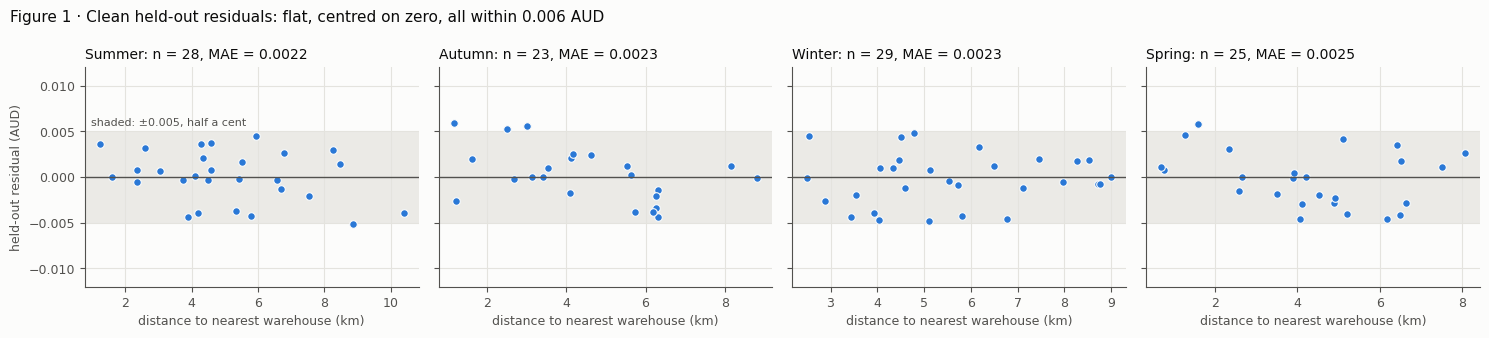

In [42]:
BLUE, ORANGE = "#2a78d6", "#eb6834"          # figure colours
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3de", "#fcfcfb"

def _style(ax, title):
    ax.set_facecolor(SURFACE)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.set_title(title, fontsize=10, color=INK, loc="left")

scale_rows = []
for s in SEASONS:
    e = delivery_models[s].holdout_residuals_
    scale_rows.append({"season": s, "n_holdout": len(e), "median_e": np.median(e),
                       "MAD": np.median(np.abs(e - np.median(e)))})
pooled = np.concatenate([delivery_models[s].holdout_residuals_ for s in SEASONS])
scale_rows.append({"season": "pooled", "n_holdout": len(pooled), "median_e": np.median(pooled),
                   "MAD": np.median(np.abs(pooled - np.median(pooled)))})
scale = pd.DataFrame(scale_rows).set_index("season")
scale["robust_sigma = 1.4826 MAD"] = MAD_TO_SIGMA * scale["MAD"]
print("DELIV-06  clean held-out residual scale by season (AUD):\n" + scale.round(5).to_string())

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True, facecolor=SURFACE)
for ax, s in zip(axes, SEASONS):
    g = h[h["season"] == s]
    ax.axhspan(-0.005, 0.005, color=GRID, alpha=0.7, lw=0)
    ax.axhline(0, color=MUTED, lw=1)
    ax.scatter(g["distance_to_nearest_warehouse"], g["e"], s=30, color=BLUE, edgecolor=SURFACE, linewidth=0.8)
    _style(ax, f"{s}: n = {len(g)}, MAE = {g['e'].abs().mean():.4f}")
    ax.set_xlabel("distance to nearest warehouse (km)", fontsize=9, color=MUTED)
    ax.set_ylim(-0.012, 0.012)
axes[0].set_ylabel("held-out residual (AUD)", fontsize=9, color=MUTED)
axes[0].annotate("shaded: ±0.005, half a cent", xy=(0.02, 0.0056), xycoords=("axes fraction", "data"),
                 fontsize=8, color=MUTED)
fig.suptitle("Figure 1 · Clean held-out residuals: flat, centred on zero, all within 0.006 AUD",
             x=0.01, ha="left", fontsize=11, color=INK)
plt.tight_layout()
plt.show()

**Figure 1.** Held-out residuals are flat across distance. All 105 lie within ±0.006 AUD: the shaded band is the half-cent rounding bound alone, and the extra ≤0.001 is coefficient-estimation error (largest held-out |e| is 0.0060, DELIV-05).

outlier batch: 500 rows scored out of sample, 0 unscorable: True
  lower population: 476 rows, |e| from 0.00001 to 0.00612 AUD
  upper population: 24 rows, |e| from 6.2471 to 22.0007 AUD
  gap between them: x1,021
  corr(raw charge, |residual|) = 0.52  <- related, but size alone cannot separate them


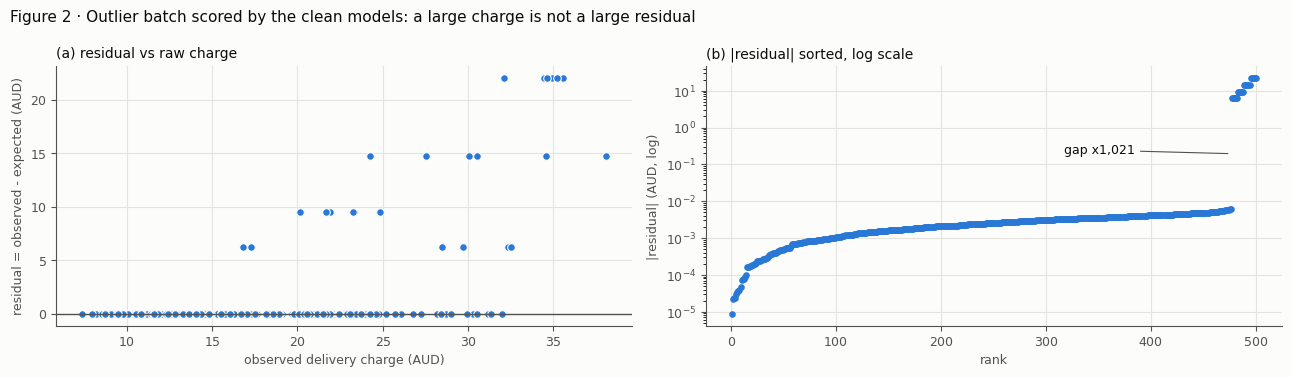

In [43]:
e_out = delivery_residuals(outlier_raw, delivery_models)
obs_out = _to_number(outlier_raw[DELIVERY_TARGET], DELIVERY_TARGET)
abs_sorted = np.sort(e_out.abs().to_numpy())
jump = int(np.argmax(np.diff(np.log10(abs_sorted))))          # largest multiplicative gap
print(f"outlier batch: {len(e_out)} rows scored out of sample, 0 unscorable: {e_out.notna().all()}")
print(f"  lower population: {jump + 1} rows, |e| from {abs_sorted[0]:.5f} to {abs_sorted[jump]:.5f} AUD")
print(f"  upper population: {len(abs_sorted) - jump - 1} rows, |e| from {abs_sorted[jump + 1]:.4f} to {abs_sorted[-1]:.4f} AUD")
print(f"  gap between them: x{abs_sorted[jump + 1] / abs_sorted[jump]:,.0f}")
print(f"  corr(raw charge, |residual|) = {np.corrcoef(obs_out, e_out.abs())[0, 1]:.2f}  <- related, but size alone cannot separate them")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), facecolor=SURFACE)
ax = axes[0]
ax.scatter(obs_out, e_out, s=30, color=BLUE, edgecolor=SURFACE, linewidth=0.8)
ax.axhline(0, color=MUTED, lw=1)
_style(ax, "(a) residual vs raw charge")
ax.set_xlabel("observed delivery charge (AUD)", fontsize=9, color=MUTED)
ax.set_ylabel("residual = observed - expected (AUD)", fontsize=9, color=MUTED)
ax = axes[1]
ax.scatter(np.arange(1, len(abs_sorted) + 1), abs_sorted, s=14, color=BLUE)
ax.set_yscale("log")
_style(ax, "(b) |residual| sorted, log scale")
ax.set_xlabel("rank", fontsize=9, color=MUTED)
ax.set_ylabel("|residual| (AUD, log)", fontsize=9, color=MUTED)
ax.annotate(f"gap x{abs_sorted[jump + 1] / abs_sorted[jump]:,.0f}", xy=(jump + 1, np.sqrt(abs_sorted[jump] * abs_sorted[jump + 1])),
            xytext=(-120, 0), textcoords="offset points", fontsize=9, color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
fig.suptitle("Figure 2 · Outlier batch scored by the clean models: a large charge is not a large residual",
             x=0.01, ha="left", fontsize=11, color=INK)
plt.tight_layout()
plt.show()

**Figure 2.** Several charges above AUD 30 sit on the zero line, while some large residuals come from
ordinary AUD 17–25 charges, so charge size alone cannot find the anomalies. On a log scale the
residuals form two groups, cent-sized and about a thousand times larger, with nothing in between.

#### Decision rule - DELIV-07

Remove an outlier-batch order when |e − m| > τ. Here e is the observed minus the expected charge from
the order's season model, m is the median clean held-out residual, and τ = 3.5 × 1.4826 × MAD of
those residuals. This is a Hampel identifier: the median is the reference value and 1.4826 × MAD the
robust measure of variation, so the anomalies cannot inflate the scale that judges them. The cut-off
3.5 is the modified z-score value; the common cut-off of 3 gives τ = 0.0090, which removes the same
24 orders because both lie in the plateau below.

- It uses the residual, not the raw charge, so an expensive but valid delivery is not penalised. The
  residual from the seasonal linear model is the outlier score, which is how a linear model detects
  outliers across several attributes at once.
- m and τ come only from clean held-out rows, so no judged charge helps set its own threshold.
- It is two-sided: an undercharge breaks the tariff as much as an overcharge.
- In this batch only `delivery_charges` can be wrong (spec 2), so a large residual points at the charge.

The spec 5 tolerances are marking tolerances, not this threshold. Flagged rows are removed, not repaired.

**What τ rests on.** The 3.5 cut-off and the 1.4826 constant are the Gaussian modified z-score
convention. The clean noise here is not Gaussian: it is cent rounding plus a little estimation error,
and no residual exceeds 0.006 on any of the 420 clean rows (DELIV-10). The guarantee therefore comes
from that bound and from the plateau under *Threshold sensitivity*, not from a Gaussian tail
probability. τ = 0.0104 sits just above one cent: a valid charge recorded one cent off would leave a
residual of up to about 0.016 and be removed. τ + 0.01 tolerates such an artefact and removes the same
24 orders, so this matters for future data, not for this decision.

In [44]:
def delivery_outlier_table(df, models):
    """Per-row evidence behind flag_outlier_rows (diagnostics and audit evidence)."""
    rule = residual_threshold(models)
    observed = _to_number(df[DELIVERY_TARGET], DELIVERY_TARGET)
    expected = predict_delivery_charge(df, models)
    residual = observed - expected
    table = pd.DataFrame({
        "order_id": df["order_id"],
        "season": df["season"],
        "observed_charge": observed,
        "expected_charge": expected,
        "residual": residual,
        "modified_z": (residual - rule["centre"]) / rule["robust_sigma"],
    })
    table["flag_remove"] = (residual - rule["centre"]).abs() > rule["tau"]   # two-sided
    return table


def flag_outlier_rows(df, models):
    """Return the order ids to remove, by the justified residual rule.

    A large charge is not a large residual: a valid delivery may be expensive
    and an erroneous charge may sit inside the ordinary charge range.
    """
    table = delivery_outlier_table(df, models)
    unscored = table["residual"].isna()
    if unscored.any():                 # never retain a row silently because it was not scored
        raise ValueError(f"{int(unscored.sum())} rows cannot be scored: "
                         f"{table.loc[unscored, 'order_id'].tolist()[:5]}")
    return sorted(table.loc[table["flag_remove"], "order_id"])

In [45]:
rule = residual_threshold(delivery_models)
print("DELIV-07  rule parameters (from clean held-out residuals only):")
for k in ("n_clean_residuals", "centre", "mad", "robust_sigma", "cutoff", "tau"):
    print(f"  {k:18s} = {rule[k]:.6f}" if isinstance(rule[k], float) else f"  {k:18s} = {rule[k]}")

outlier_table = delivery_outlier_table(outlier_raw, delivery_models)
OUTLIER_IDS_TO_REMOVE = flag_outlier_rows(outlier_raw, delivery_models)
outlier_table["raw_charge_pct_rank"] = outlier_table["observed_charge"].rank(pct=True)
outlier_table = outlier_table.join(outlier_raw[["is_expedited_delivery", "is_happy_customer"]]).assign(
    distance_to_nearest_warehouse=pd.to_numeric(outlier_raw["distance_to_nearest_warehouse"]))
flagged = outlier_table[outlier_table["flag_remove"]].sort_values("residual")
print(f"\nflagged for removal: {len(OUTLIER_IDS_TO_REMOVE)} of {len(outlier_raw)} "
      f"| positive residuals: {int((flagged['residual'] > 0).sum())}, negative: {int((flagged['residual'] < 0).sum())}")
print(f"distinct residual sizes (AUD, nearest 0.25): {sorted(set((flagged['residual'] * 4).round() / 4))}\n")
cols = ["order_id", "season", "distance_to_nearest_warehouse", "is_expedited_delivery", "is_happy_customer",
        "observed_charge", "expected_charge", "residual", "modified_z", "raw_charge_pct_rank"]
print(flagged[cols].to_string(index=False, formatters={
    "distance_to_nearest_warehouse": "{:.4f}".format, "observed_charge": "{:.2f}".format,
    "expected_charge": "{:.4f}".format, "residual": "{:+.4f}".format, "modified_z": "{:,.0f}".format,
    "raw_charge_pct_rank": "{:.0%}".format}))

fp_fit = flag_outlier_rows(fit_df, delivery_models)
fp_hold = flag_outlier_rows(holdout_df, delivery_models)
print(f"\nclean-row check (consistency only, not independent evidence for tau): flags {len(fp_fit)} of {len(fit_df)} "
      f"fit rows (in-sample) and {len(fp_hold)} of {len(holdout_df)} held-out rows (these set tau)")

DELIV-07  rule parameters (from clean held-out residuals only):
  n_clean_residuals  = 105
  centre             = -0.000024
  mad                = 0.002012
  robust_sigma       = 0.002984
  cutoff             = 3.500000
  tau                = 0.010442

flagged for removal: 24 of 500 | positive residuals: 24, negative: 0
distinct residual sizes (AUD, nearest 0.25): [6.25, 9.5, 14.75, 22.0]

  order_id season distance_to_nearest_warehouse is_expedited_delivery is_happy_customer observed_charge expected_charge residual modified_z raw_charge_pct_rank
CORD001276 Autumn                        5.1835                 False              True           17.29         11.0429  +6.2471      2,094                 74%
CORD001200 Spring                        7.4542                  True              True           29.69         23.4422  +6.2478      2,094                 96%
CORD001036 Spring                        2.3558                  True             False           28.47         22.2192  +6.250

#### Threshold sensitivity

The cell below finds every τ that returns the same set of ids.

In [46]:
a = (outlier_table["residual"] - rule["centre"]).abs()
lo, hi = a[~outlier_table["flag_remove"]].max(), a[outlier_table["flag_remove"]].min()
chosen = set(OUTLIER_IDS_TO_REMOVE)
grid = [(0.0050, "cent-rounding bound"), (0.0060, "just below the largest valid residual"),
        (rule["tau"], "chosen tau (modified z = 3.5)"), (rule["tau"] + 0.01, "tau + one cent: tolerates a one-cent artefact"),
        (0.05, ""), (0.08, "section 5 marking tolerance, NOT the rule"),
        (1.0, ""), (3.0, ""), (6.0, ""), (6.3, "just above the smallest anomaly"), (10.0, "")]
sens = pd.DataFrame([{"tau (AUD)": t, "flagged": int((a > t).sum()),
                      "same ids as the rule": set(outlier_table.loc[a > t, "order_id"]) == chosen, "note": note}
                     for t, note in grid])
print(sens.to_string(index=False, formatters={"tau (AUD)": "{:.4f}".format}))
print(f"\nplateau: any tau in ({lo:.5f}, {hi:.4f}) AUD returns exactly these {len(chosen)} ids, "
      f"a range of x{hi / lo:,.0f}")
print(f"chosen tau = {rule['tau']:.5f}: x{rule['tau'] / lo:.1f} above the largest valid residual, "
      f"x{hi / rule['tau']:,.0f} below the smallest anomaly")

# Each season's own median and MAD instead of the pooled ones.
per_season_tau = []
for s in SEASONS:
    e_s = np.asarray(delivery_models[s].holdout_residuals_)
    centre_s = float(np.median(e_s))
    tau_s = MODIFIED_Z_CUTOFF * MAD_TO_SIGMA * float(np.median(np.abs(e_s - centre_s)))
    in_s = outlier_table["season"].eq(s)
    flagged_s = set(outlier_table.loc[in_s & (outlier_table["residual"] - centre_s).abs().gt(tau_s), "order_id"])
    per_season_tau.append({"season": s, "own tau (AUD)": tau_s, "flagged": len(flagged_s),
                           "same ids as the pooled rule":
                               flagged_s == set(outlier_table.loc[in_s & outlier_table["flag_remove"], "order_id"])})
per_season_tau = pd.DataFrame(per_season_tau).set_index("season")
print("\nper-season thresholds (each season's own median and MAD) instead of the pooled one:")
print(per_season_tau.to_string(formatters={"own tau (AUD)": "{:.5f}".format}))
print(f"a valid charge recorded one cent off would leave |e - m| up to {0.01 + lo:.4f} > tau = {rule['tau']:.4f}; "
      f"tau + 0.01 = {rule['tau'] + 0.01:.4f} tolerates it and still returns the same {len(chosen)} ids: "
      f"{set(outlier_table.loc[a > rule['tau'] + 0.01, 'order_id']) == chosen}")

tau (AUD)  flagged  same ids as the rule                                          note
   0.0050       43                 False                           cent-rounding bound
   0.0060       25                 False         just below the largest valid residual
   0.0104       24                  True                 chosen tau (modified z = 3.5)
   0.0204       24                  True tau + one cent: tolerates a one-cent artefact
   0.0500       24                  True                                              
   0.0800       24                  True     section 5 marking tolerance, NOT the rule
   1.0000       24                  True                                              
   3.0000       24                  True                                              
   6.0000       24                  True                                              
   6.3000       18                 False               just above the smallest anomaly
  10.0000       12                 False   

The rule removes 24 orders, all overcharged, in four discrete amounts (about AUD 6.25, 9.50, 14.75
and 22.00); DELIV-08 shows these are exact surcharges added to the billed charge, not noise. It flags none of the 315 fit rows or
the 105 held-out rows, but that is only a consistency check: the fit rows trained the models and the
held-out rows set τ. The independent evidence is the plateau (any τ between about 0.0061 and 6.25 gives the
same 24 ids), the self-calibrated check DELIV-07b and the order-total identity DELIV-08. Each season's own
threshold (0.0105–0.0140) and τ + 0.01 give the same 24 as well, so neither pooling the noise scale nor
τ's closeness to one cent drives the result. τ is only 1.7× the
largest valid residual because clean noise is just cent rounding, so the decision rests on that plateau and
not on τ's own margin.

#### Self-calibrated cross-check - DELIV-07b

To test the choice of noise scale, each season is refitted on the outlier batch itself with
iterative trimming, using no clean rows and no τ. It returns the same 24 ids. This is a diagnostic
only and removes nothing.

In [47]:
def _trimmed_flags(df, cutoff=MODIFIED_Z_CUTOFF, max_iter=25):
    """Diagnostic only: flag rows by iterative trimming on the judged batch itself."""
    enc = encode_predictors(df)
    flagged, n_pass = set(), {}
    for season in SEASONS:
        g = enc[enc["season"] == season]
        X = g[DELIVERY_PREDICTORS].to_numpy(dtype=float)
        y = g[DELIVERY_TARGET].to_numpy(dtype=float)
        keep = np.ones(len(g), dtype=bool)
        for n_pass[season] in range(1, max_iter + 1):
            e = y - LinearRegression().fit(X[keep], y[keep]).predict(X)
            centre = np.median(e[keep])
            scale = MAD_TO_SIGMA * np.median(np.abs(e[keep] - centre))
            if scale == 0:
                raise ValueError(f"{season}: robust scale is zero")
            new_keep = np.abs(e - centre) <= cutoff * scale
            if (new_keep == keep).all():
                break
            keep = new_keep
        flagged |= set(g.loc[~keep, "order_id"])
    return flagged, n_pass


self_calibrated, n_pass = _trimmed_flags(outlier_raw)
print(f"DELIV-07b  iterative trimming on the outlier batch alone flags {len(self_calibrated)} rows "
      f"(passes to converge by season: {n_pass})")
print(f"           identical to the {len(OUTLIER_IDS_TO_REMOVE)} ids removed by the clean-calibrated rule: "
      f"{self_calibrated == set(OUTLIER_IDS_TO_REMOVE)}")
assert self_calibrated == set(OUTLIER_IDS_TO_REMOVE)

DELIV-07b  iterative trimming on the outlier batch alone flags 24 rows (passes to converge by season: {'Summer': 2, 'Autumn': 2, 'Winter': 3, 'Spring': 3})
           identical to the 24 ids removed by the clean-calibrated rule: True


#### Model-free check and naive rules - DELIV-08

In the outlier batch `order_price`, `coupon_discount` and `order_total` are correct, so the charge
actually billed can be recovered from the spec 3.2 identity, to within ±0.005:

$$c^* = \text{order\_total} - \text{order\_price}\,(1 - \text{coupon\_discount}/100)$$

It serves as corroboration and as reference labels for comparing rules, not as the detector, because
it would fail wherever `order_total` itself could be wrong.

This check rests on one stated assumption: only `delivery_charges` is corrupted in the outlier batch
(published batch guarantee), so `order_total` still reflects the charge originally billed. That is why
`c*` is a corroborating label and not ground truth, and why the residual rule above does not use it.
`c*` carries the cent rounding of `order_total` (±0.005), the billed charge is itself a cent-rounded
tariff value, and the model adds up to about 0.001 of estimation error, so agreement within 0.01 is the
expected noise budget.


In [48]:
ob = outlier_raw.set_index("order_id")
implied = (pd.to_numeric(ob["order_total"])
           - pd.to_numeric(ob["order_price"]) * (1 - pd.to_numeric(ob["coupon_discount"]) / 100))
ot = outlier_table.set_index("order_id").assign(implied_charge=implied)
arith_inconsistent = (ot["observed_charge"] - ot["implied_charge"]).abs() > 0.01 + 1e-9

print("DELIV-08  model-free corroboration via the order_total identity:")
print(f"  rows whose observed charge contradicts order_total : {int(arith_inconsistent.sum())}")
print(f"  identical to the residual rule's removal set        : {set(ot.index[arith_inconsistent]) == chosen}")
rem, ret = ot[ot["flag_remove"]], ot[~ot["flag_remove"]]
print(f"  removed rows : max |model expected - billed c*| = {(rem['expected_charge'] - rem['implied_charge']).abs().max():.4f} AUD")
print(f"                 -> the model recovers the charge each order was actually billed at")
print(f"  retained rows: max |observed - billed c*|       = {(ret['observed_charge'] - ret['implied_charge']).abs().max():.4f} AUD")
print(f"                 -> every retained charge is the billed charge (valid)")

# Every cent charge that reproduces a stored total by the spec 3.2 rule: the integer-cent search of MISS-03.
# A rounded total can allow two adjacent cents, so what was billed is a set, usually of one. (1.1's
# charge_from_total is not reused: its round(implied +- 0.01) search can skip a valid cent.)
def charges_reproducing_total(r):
    implied = float(r.order_total) - float(r.order_price) * (1 - float(r.coupon_discount) / 100)
    cents = int(round(implied * 100))
    return [c / 100 for c in range(cents - 2, cents + 3)
            if compute_order_total(r.order_price, r.coupon_discount, c / 100) == float(r.order_total)]


billed_sets = {r.order_id: charges_reproducing_total(r) for r in outlier_raw.itertuples(index=False)}
# The allowed charge nearest the model; it can differ from the only allowed charge only when a total allows two.
billed_cent = pd.Series({o: min(c, key=lambda v: abs(v - ot.at[o, "expected_charge"])) if c else np.nan
                         for o, c in billed_sets.items()})
ambiguous = {o for o, c in billed_sets.items() if len(c) > 1}
surcharge = (ot.loc[sorted(chosen), "observed_charge"] - billed_cent.loc[sorted(chosen)]).round(2)
retained_ok = sum(any(abs(ot.at[o, "observed_charge"] - v) < 1e-9 for v in billed_sets[o]) for o in ret.index)
print(f"  against the charges each total allows: removed rows exceed them by exactly "
      f"{sorted(float(x) for x in surcharge.unique())} AUD (ambiguous totals among them: {len(ambiguous & chosen)}); "
      f"{retained_ok} of {len(ret)} retained charges are allowed by their total ({len(ambiguous - chosen)} of "
      f"those totals allow two adjacent cents)")
print(f"                 max |model expected - allowed charge| over removed rows = "
      f"{(ot.loc[sorted(chosen), 'expected_charge'] - billed_cent.loc[sorted(chosen)]).abs().max():.4f} AUD")

# benchmark rules against the model-free labels
truth = arith_inconsistent
ch = ot["observed_charge"]
q1, q3 = ch.quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
raw_z = ch.groupby(ot["season"]).transform(lambda s: (s - s.mean()) / s.std(ddof=1))
rules = {
    f"raw charge > Tukey fence ({fence:.2f}), pooled": ch > fence,
    "raw charge |z| > 3 within season": raw_z.abs() > 3,
    "residual |e - m| > tau  (chosen)": ot["flag_remove"],
}
bench = pd.DataFrame([{"rule": k, "flagged": int(v.sum()),
                       "valid orders deleted": int((v & ~truth).sum()),
                       "anomalies missed": int((~v & truth).sum())} for k, v in rules.items()]).set_index("rule")
print("\nrules scored against the model-free labels (24 anomalous, 476 valid):\n" + bench.to_string())

DELIV-08  model-free corroboration via the order_total identity:
  rows whose observed charge contradicts order_total : 24
  identical to the residual rule's removal set        : True
  removed rows : max |model expected - billed c*| = 0.0052 AUD
                 -> the model recovers the charge each order was actually billed at
  retained rows: max |observed - billed c*|       = 0.0050 AUD
                 -> every retained charge is the billed charge (valid)
  against the charges each total allows: removed rows exceed them by exactly [6.25, 9.5, 14.75, 22.0] AUD (ambiguous totals among them: 0); 476 of 476 retained charges are allowed by their total (5 of those totals allow two adjacent cents)
                 max |model expected - allowed charge| over removed rows = 0.0054 AUD

rules scored against the model-free labels (24 anomalous, 476 valid):
                                          flagged  valid orders deleted  anomalies missed
rule                                            

erroneous charges inside the ordinary range: 10 of 24 removed rows are at or below the batch's 95th-percentile charge (AUD 28.38)
            season  observed_charge  expected_charge  implied_charge  residual
order_id                                                                      
CORD001144  Autumn            16.83          10.5756         10.5790    6.2544
CORD001276  Autumn            17.29          11.0429         11.0405    6.2471
CORD001277  Autumn            20.14          10.6393         10.6360    9.5007
CORD001477  Autumn            21.66          12.1585         12.1570    9.5015

valid deliveries that are expensive: the five highest retained charges
            season  distance_to_nearest_warehouse is_expedited_delivery is_happy_customer  observed_charge  expected_charge  residual
order_id                                                                                                                             
CORD001338  Winter                         5.8810       

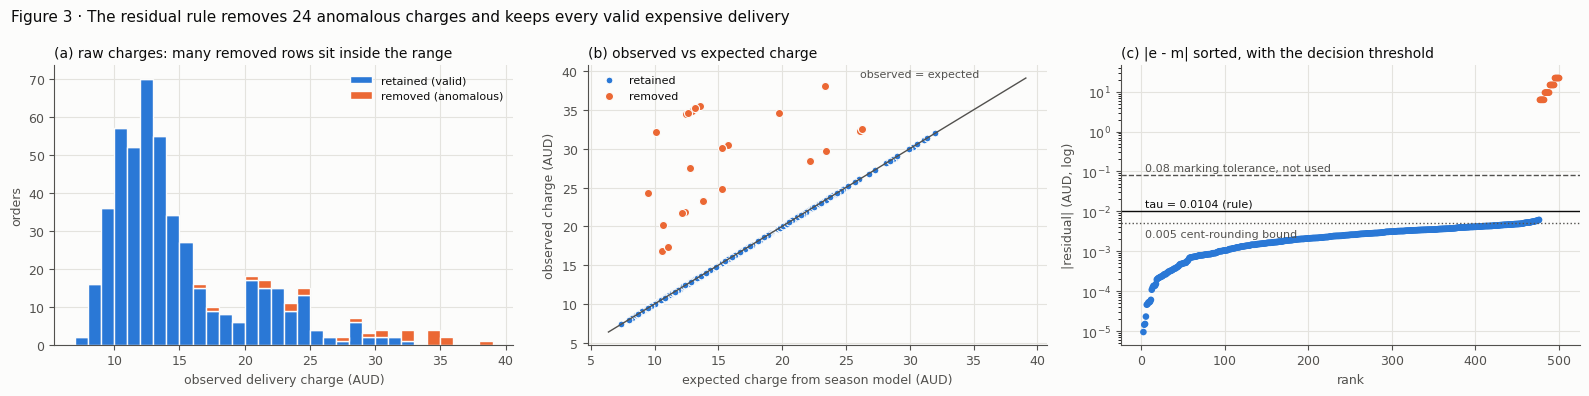

In [49]:
p95 = ch.quantile(0.95)
print(f"erroneous charges inside the ordinary range: {int((rem['observed_charge'] <= p95).sum())} of {len(rem)} "
      f"removed rows are at or below the batch's 95th-percentile charge (AUD {p95:.2f})")
print(rem.loc[rem["observed_charge"] <= p95].nsmallest(4, "observed_charge")[
      ["season", "observed_charge", "expected_charge", "implied_charge", "residual"]].round(4).to_string())
print("\nvalid deliveries that are expensive: the five highest retained charges")
print(ret.nlargest(5, "observed_charge")[["season", "distance_to_nearest_warehouse", "is_expedited_delivery",
      "is_happy_customer", "observed_charge", "expected_charge", "residual"]].round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4), facecolor=SURFACE)
bins = np.arange(np.floor(ch.min()), np.ceil(ch.max()) + 1, 1.0)
ax = axes[0]
ax.hist([ret["observed_charge"], rem["observed_charge"]], bins=bins, stacked=True, color=[BLUE, ORANGE],
        edgecolor=SURFACE, linewidth=1, label=["retained (valid)", "removed (anomalous)"])
_style(ax, "(a) raw charges: many removed rows sit inside the range")
ax.set_xlabel("observed delivery charge (AUD)", fontsize=9, color=MUTED)
ax.set_ylabel("orders", fontsize=9, color=MUTED)
ax.legend(frameon=False, fontsize=8, labelcolor=INK)
ax = axes[1]
lim = [ch.min() - 1, ch.max() + 1]
ax.plot(lim, lim, color=MUTED, lw=1)
ax.scatter(ret["expected_charge"], ret["observed_charge"], s=24, color=BLUE, edgecolor=SURFACE, linewidth=0.8, label="retained")
ax.scatter(rem["expected_charge"], rem["observed_charge"], s=34, color=ORANGE, edgecolor=SURFACE, linewidth=0.8, label="removed")
ax.annotate("observed = expected", xy=(lim[1] - 1, lim[1] - 1), xytext=(-110, 6), textcoords="offset points", fontsize=8, color=MUTED)
_style(ax, "(b) observed vs expected charge")
ax.set_xlabel("expected charge from season model (AUD)", fontsize=9, color=MUTED)
ax.set_ylabel("observed charge (AUD)", fontsize=9, color=MUTED)
ax.legend(frameon=False, fontsize=8, labelcolor=INK, loc="upper left")
ax = axes[2]
order = a.sort_values().index
colors = np.where(outlier_table.loc[order, "flag_remove"], ORANGE, BLUE)
ax.scatter(np.arange(1, len(order) + 1), a.loc[order], s=14, color=colors)
ax.set_yscale("log")
for y, text, style, dy in ((rule["tau"], f"tau = {rule['tau']:.4f} (rule)", "-", 3),
                           (0.005, "0.005 cent-rounding bound", ":", -10),
                           (0.08, "0.08 marking tolerance, not used", "--", 3)):
    ax.axhline(y, color=INK if style == "-" else MUTED, lw=1, ls=style)
    ax.annotate(text, xy=(5, y), xytext=(0, dy), textcoords="offset points", fontsize=8,
                color=INK if style == "-" else MUTED)
_style(ax, "(c) |e - m| sorted, with the decision threshold")
ax.set_xlabel("rank", fontsize=9, color=MUTED)
ax.set_ylabel("|residual| (AUD, log)", fontsize=9, color=MUTED)
fig.suptitle("Figure 3 · The residual rule removes 24 anomalous charges and keeps every valid expensive delivery",
             x=0.01, ha="left", fontsize=11, color=INK)
plt.tight_layout()
plt.show()

**How the method avoids deleting unusual but valid orders.**

- The 24 removed ids are exactly the orders whose charge contradicts their own total. Each exceeds the
  charge its total allows by one of four exact surcharges, and the model's expected charge matches that
  allowed charge within its season's clean held-out error (at most AUD 0.0054). Each of the other 476
  charges is one its total allows.
- The boxplot rule (a Tukey fence on raw charges) would delete 13 valid expensive orders and miss 9
  anomalies; a per-season 3σ edit rule (z > 3) misses 16. The residual rule makes neither error.
- 10 of the 24 anomalous charges are at or below the 95th percentile, while the highest retained
  charges (up to AUD 32) are valid Winter expedited deliveries with residuals of at most AUD 0.0051.

#### Retained rows - DELIV-09

The 476 retained rows never trained the model, so their fit below is out of sample. The formal
check on the exported CSV belongs to 2.2.

In [50]:
retained = outlier_raw[~outlier_raw["order_id"].isin(OUTLIER_IDS_TO_REMOVE)]
removed = outlier_raw[outlier_raw["order_id"].isin(OUTLIER_IDS_TO_REMOVE)]
assert len(retained) + len(removed) == len(outlier_raw) and set(retained["order_id"]).isdisjoint(removed["order_id"])
print(f"DELIV-09  reconciliation: {len(outlier_raw)} = {len(retained)} retained + {len(removed)} removed (disjoint)")

r_obs = _to_number(retained[DELIVERY_TARGET], DELIVERY_TARGET)
r_hat = predict_delivery_charge(retained, delivery_models)
fit_ret = pd.DataFrame([{"season": s, "n_retained": int((retained["season"] == s).sum()),
                         "r2_out_of_sample": r2_score(r_obs[retained["season"] == s], r_hat[retained["season"] == s]),
                         "mae": (r_obs - r_hat)[retained["season"] == s].abs().mean(),
                         "max_abs_e": (r_obs - r_hat)[retained["season"] == s].abs().max()}
                        for s in SEASONS]).set_index("season")
print("\nseasonal fit on the retained rows (never used for fitting):")
print(fit_ret.to_string(formatters={"r2_out_of_sample": "{:.7f}".format, "mae": "{:.4f}".format, "max_abs_e": "{:.4f}".format}))

refit_ret = seasonal_coefficients(_fit_by_season(retained))
print(f"\ndiagnostic refit on retained rows only: max |coef - chosen| = {(refit_ret - coef).abs().to_numpy().max():.4f} AUD")
print(f"(for contrast, fitting the full outlier batch moved them by {(alt_coefs['(e) outlier batch (500 rows, contains anomalies)'] - coef).abs().to_numpy().max():.3f} AUD)")

# Support: were any orders scored beyond the distances their season's model was fitted on?
fit_range = encode_predictors(fit_df).groupby("season")["distance_to_nearest_warehouse"].agg(["min", "max"])
scored_km = pd.to_numeric(outlier_raw["distance_to_nearest_warehouse"])
beyond_km = ((scored_km - outlier_raw["season"].map(fit_range["max"])).clip(lower=0)
             + (outlier_raw["season"].map(fit_range["min"]) - scored_km).clip(lower=0))
extrapolated = outlier_raw.loc[beyond_km > 0, "order_id"]
extrapolated_e = (outlier_table.set_index("order_id").loc[extrapolated, "residual"] - rule["centre"]).abs()
print(f"\nsupport: {len(extrapolated)} outlier-batch orders lie outside their season's fitted distance range "
      f"(by up to {beyond_km.max():.2f} km); removed among them: {int(extrapolated.isin(OUTLIER_IDS_TO_REMOVE).sum())}; "
      f"their largest |e - m| = {extrapolated_e.max():.4f} AUD")

DELIV-09  reconciliation: 500 = 476 retained + 24 removed (disjoint)

seasonal fit on the retained rows (never used for fitting):
        n_retained r2_out_of_sample    mae max_abs_e
season                                              
Summer         132        0.9999995 0.0026    0.0058
Autumn         120        0.9999996 0.0027    0.0061
Winter         121        0.9999998 0.0023    0.0051
Spring         103        0.9999996 0.0023    0.0056

diagnostic refit on retained rows only: max |coef - chosen| = 0.0028 AUD
(for contrast, fitting the full outlier batch moved them by 1.299 AUD)

support: 4 outlier-batch orders lie outside their season's fitted distance range (by up to 0.56 km); removed among them: 0; their largest |e - m| = 0.0034 AUD


The retained rows fit at R² ≈ 1 with MAE at the cent-rounding floor, and refitting on them alone
moves the coefficients by under AUD 0.003. Four orders lie up to 0.56 km beyond their season's fitted
distance range; all four are retained and fit within AUD 0.0034, so no decision rests on extrapolation.

#### Decision output

`OUTLIER_IDS_TO_REMOVE` lists the 24 orders. The payload below holds the matching audit-log rows for
`record_removed`. The next cell records the actual removals and assigns confidence from the residual rule and independent total evidence. The payload confidence remains a proposal until that cell runs.

In [51]:
# Prepared for the audit recorder's record_removed. Not recorded here. Column order follows the spec's audit schema.
billed = billed_cent.loc[OUTLIER_IDS_TO_REMOVE]   # the cent charge that reproduces each total (DELIV-08)
tab = outlier_table.set_index("order_id").loc[OUTLIER_IDS_TO_REMOVE]
removal_payload = pd.DataFrame({
    "source_file": OUTLIER_INPUT.name,
    "record_key": OUTLIER_IDS_TO_REMOVE,
    "field_name": DELIVERY_TARGET,
    "issue_type": "outlier_row",
    "original_value": ob.loc[OUTLIER_IDS_TO_REMOVE, DELIVERY_TARGET].to_numpy(),   # exact source text
    "corrected_value": "ROW_REMOVED",                                               # = the recorder's ROW_REMOVED marker
    "method": f"Sec 3.5 seasonal OLS residual rule: |observed - expected - m| > tau = {rule['tau']:.4f} (modified z > 3.5)",
    "evidence": [f"DELIV-07 e={r:+.2f} AUD, z={z:,.0f}; DELIV-08 billed charge {b:.2f} vs expected {x:.2f}"
                 for r, z, b, x in zip(tab["residual"], tab["modified_z"], billed, tab["expected_charge"])],
    "confidence": "high",   # placeholder; the next cell assigns the final confidence
})
print(f"\nprepared audit payload for the recorder: {len(removal_payload)} rows (not recorded here)")
print(removal_payload.head(3).to_string(index=False))
print(f"\nOUTLIER_IDS_TO_REMOVE ({len(OUTLIER_IDS_TO_REMOVE)}): {OUTLIER_IDS_TO_REMOVE}")


prepared audit payload for the recorder: 24 rows (not recorded here)
              source_file record_key       field_name  issue_type original_value corrected_value                                                                                          method                                                                       evidence confidence
Group005_outlier_data.csv CORD001026 delivery_charges outlier_row           38.1     ROW_REMOVED Sec 3.5 seasonal OLS residual rule: |observed - expected - m| > tau = 0.0104 (modified z > 3.5) DELIV-07 e=+14.75 AUD, z=4,943; DELIV-08 billed charge 23.35 vs expected 23.35       high
Group005_outlier_data.csv CORD001036 delivery_charges outlier_row          28.47     ROW_REMOVED Sec 3.5 seasonal OLS residual rule: |observed - expected - m| > tau = 0.0104 (modified z > 3.5)  DELIV-07 e=+6.25 AUD, z=2,095; DELIV-08 billed charge 22.22 vs expected 22.22       high
Group005_outlier_data.csv CORD001049 delivery_charges outlier_row           21.9 

In [52]:
# AUDIT_CONFIDENCE: validate support before assigning either high or medium.
def removal_confidence(row, expected_charge, residual_rule, model_report, shared_ok):
    """Confidence in a 1.3 outlier removal; weak or borderline evidence raises.

    A margin exceeding the season's worst clean held-out error is a practical
    evidence gate, not a statistical confidence interval. It does not change
    the 1.3 removal threshold or choose additional orders to remove.
    """
    metrics = model_report.loc[row.season]
    centre, tau = float(residual_rule['centre']), float(residual_rule['tau'])
    expected = float(expected_charge)
    residual = float(row.delivery_charges) - expected
    numbers = [centre, tau, expected, residual, float(metrics.n_train),
               float(metrics.n_holdout), float(metrics.r2_holdout),
               float(metrics.mae_holdout), float(metrics.max_abs_error)]
    if not all(math.isfinite(value) for value in numbers) or tau <= 0:
        raise ValueError(f'{row.order_id}: invalid residual or model evidence')
    if (not shared_ok or not float(metrics.n_train).is_integer()
            or not float(metrics.n_holdout).is_integer()
            or metrics.n_train < 4 or metrics.n_holdout < 2
            or metrics.r2_holdout < 0.99 or metrics.mae_holdout < 0
            or metrics.max_abs_error < metrics.mae_holdout):
        raise ValueError(f'{row.order_id}: model/input evidence needs investigation')
    margin = abs(residual - centre) - tau
    error_gate = max(0.005, float(metrics.max_abs_error))
    if margin <= error_gate:
        raise ValueError(f'{row.order_id}: removal is borderline; investigate before logging')
    # Corroboration that does not use the model: the cent charges that reproduce the stored order_total are
    # what was actually billed (charges_reproducing_total, DELIV-08; usually one, sometimes two adjacent
    # cents). The observed charge must differ from all of them by more than a cent, and the model must
    # recover one within the same error gate. Comparing with cent values, not the unrounded total - price x
    # (1 - coupon/100), keeps the total's own +-0.005 rounding out of the comparison, so the season's clean
    # held-out error is the right yardstick (DELIV-08 counts both roundings in its 0.01 budget).
    allowed = charges_reproducing_total(row)
    if allowed:
        contradiction = min(abs(float(row.delivery_charges) - c) for c in allowed)
        agreement = min(abs(expected - c) for c in allowed)
    else:
        contradiction = agreement = math.nan
    corroborated = bool(allowed) and contradiction > 0.01 and agreement <= error_gate
    confidence = 'high' if corroborated else 'medium'
    evidence = (f'AUDIT_CONFIDENCE: season={row.season}; n_train={int(metrics.n_train)}; '
                f'n_holdout={int(metrics.n_holdout)}; R2={metrics.r2_holdout:.6f}; '
                f'MAE={metrics.mae_holdout:.6f}; residual={residual:.6f}; '
                f'tau={tau:.6f}; margin={margin:.6f} > gate={error_gate:.6f}; '
                f'billed charge(s) allowed by total={allowed}; |observed - billed|={contradiction:.2f}; '
                f'|expected - billed|={agreement:.6f} (gate {error_gate:.6f}); confidence={confidence}')
    return confidence, evidence


removed_ids = set(OUTLIER_IDS_TO_REMOVE)
removed_mask = outlier_raw['order_id'].isin(removed_ids)
if not outlier_raw.order_id.is_unique or int(removed_mask.sum()) != len(removed_ids):
    raise AssertionError('Removal IDs must identify unique original outlier orders')
payload_by_id = removal_payload.set_index('record_key')
if not payload_by_id.index.is_unique or set(payload_by_id.index) != removed_ids:
    raise AssertionError('Removal payload and removal decisions disagree')
scored_by_id = outlier_table.set_index('order_id')
confidence_evidence = []
pending_removals = []
for row in outlier_raw.loc[removed_mask].itertuples(index=False):
    decision = payload_by_id.loc[row.order_id]
    if decision.original_value != row.delivery_charges:
        raise AssertionError(f'{row.order_id}: original charge text differs')
    confidence, support = removal_confidence(
        row, scored_by_id.at[row.order_id, 'expected_charge'], rule, report,
        bool(outlier_checks.loc[row.order_id].drop('order_total').all()))
    pending_removals.append((row, decision, confidence, support))
    confidence_evidence.append({'order_id': row.order_id, 'confidence': confidence,
                                'evidence': support})
# Validate all decisions first, then record them before filtering.
for row, decision, confidence, support in pending_removals:
    audit.record_removed(source_file=OUTLIER_INPUT, record_key=row.order_id,
        original_charge=row.delivery_charges, method=decision['method'],
        evidence=f"{decision['evidence']}; {support}", confidence=confidence)
clean_outlier = outlier_raw.loc[~removed_mask].copy()
print(f'OUTLIER_AUDIT_HANDOFF: PASS; {len(removed_ids)} logged removals; '
      f'{len(clean_outlier)} retained unchanged')
print(pd.DataFrame(confidence_evidence).to_string(index=False))


OUTLIER_AUDIT_HANDOFF: PASS; 24 logged removals; 476 retained unchanged
  order_id confidence                                                                                                                                                                                                                                                                                      evidence
CORD001026       high AUDIT_CONFIDENCE: season=Autumn; n_train=70; n_holdout=23; R2=1.000000; MAE=0.002311; residual=14.746677; tau=0.010442; margin=14.736259 > gate=0.005953; billed charge(s) allowed by total=[23.35]; |observed - billed|=14.75; |expected - billed|=0.003323 (gate 0.005953); confidence=high
CORD001036       high    AUDIT_CONFIDENCE: season=Spring; n_train=74; n_holdout=25; R2=1.000000; MAE=0.002506; residual=6.250762; tau=0.010442; margin=6.240343 > gate=0.005778; billed charge(s) allowed by total=[22.22]; |observed - billed|=6.25; |expected - billed|=0.000762 (gate 0.005778); confidence=high
CORD

#### Cross-checks for sections 1.1 and 1.2 - DELIV-11

These checks run after 1.1 and 1.2 have made their decisions and change nothing. They apply the 1.3 band
(|e − m| ≤ τ) to the dirty and missing batches as an independent second look. Nothing is repaired,
imputed or logged here.

In [53]:
# DELIV-11a => CROSS-CHECK for section 1.1, run after its repairs. Nothing is repaired, logged or written here.
# Score the UNREPAIRED dirty batch with the clean-trained models, then ask which single field explains each large residual.
tau, centre = rule["tau"], rule["centre"]   # the same centred band as every decision rule
dirty_scored = dirty_raw.assign(residual=delivery_residuals(dirty_raw, delivery_models))
suspects = dirty_scored[(dirty_scored["residual"] - centre).abs() > tau]


def _restores_fit(row, **override):
    """Would changing exactly one field bring the row back inside the clean noise band?"""
    trial = pd.DataFrame([{**row.to_dict(), **override}])
    return abs(delivery_residuals(trial, delivery_models).iloc[0] - centre) <= tau


def _single_field_causes(row):
    causes = []
    flipped = "False" if row["is_expedited_delivery"] == "True" else "True"
    if _restores_fit(row, is_expedited_delivery=flipped):
        causes.append("is_expedited_delivery")
    if _restores_fit(row, is_happy_customer=str(is_happy(row["latest_customer_review"], analyser, HAPPY_THRESHOLD))):
        causes.append("is_happy_customer")
    if _restores_fit(row, season=season_of(parse_order_date(row["date"]))):
        causes.append("season")
    lat = float(row["customer_lat"])
    if lat < 0 and _restores_fit(row, distance_to_nearest_warehouse=str(nearest_warehouse(lat, float(row["customer_long"]))[1])):
        causes.append("distance_to_nearest_warehouse")
    return causes


found = suspects.apply(_single_field_causes, axis=1)
cause = found.map(lambda c: c[0] if len(c) == 1 else ("delivery_charges (no predictor explains it)" if not c
                                                        else "ambiguous: " + "+".join(c)))
summary = (suspects.assign(cause=cause).groupby("cause")["residual"]
           .agg(rows="size", smallest_abs=lambda s: s.abs().min(), largest_abs=lambda s: s.abs().max()))
print(f"DELIV-11a  dirty batch: {len(suspects)} of {len(dirty_scored)} rows have |residual - m| > tau = {tau:.4f} AUD "
      f"with no repair applied\n")
print(summary.to_string(float_format="{:.3f}".format))

expedited_rows = suspects[cause == "is_expedited_delivery"]
name_set = set(warehouses["warehouse"])
non_model = pd.DataFrame({
    "order_price = cart x prices": expedited_rows.apply(
        lambda r: compute_order_price(parse_cart(r["shopping_cart"]), prices) == float(r["order_price"]), axis=1),
    "order_total identity": expedited_rows.apply(
        lambda r: compute_order_total(r["order_price"], r["coupon_discount"], r["delivery_charges"]) == float(r["order_total"]), axis=1),
    "date is ISO": expedited_rows["date"].map(lambda d: parse_order_date(d) == d),
    "season = season_of(date)": expedited_rows.apply(lambda r: season_of(parse_order_date(r["date"])) == r["season"], axis=1),
    "latitude is southern": expedited_rows["customer_lat"].astype(float) < 0,
    "distance = haversine": expedited_rows.apply(
        lambda r: abs(nearest_warehouse(r["customer_lat"], r["customer_long"])[1]
                      - float(r["distance_to_nearest_warehouse"])) <= 1e-4 + 1e-9, axis=1),
    "warehouse name valid": expedited_rows["nearest_warehouse"].isin(name_set),
    "happy = VADER": expedited_rows.apply(lambda r: str(is_happy(r["latest_customer_review"], analyser, HAPPY_THRESHOLD)) == r["is_happy_customer"], axis=1),
})
print(f"\nthe {len(expedited_rows)} is_expedited_delivery cases against every non-model check "
      f"(rows passing each of {len(expedited_rows)}):")
print(non_model.sum().astype(int).to_string())
beta = seasonal_coefficients(delivery_models)["b_expedited"]
print("\ntheir residual equals the season's expedited surcharge (a wrong flag shifts the charge by exactly beta2):")
print(pd.DataFrame({"season": expedited_rows["season"], "stated_expedited": expedited_rows["is_expedited_delivery"],
                    "residual": expedited_rows["residual"], "season_beta2": expedited_rows["season"].map(beta)}).round(3).to_string())

DELIV-11a  dirty batch: 40 of 500 rows have |residual - m| > tau = 0.0104 AUD with no repair applied

                                             rows  smallest_abs  largest_abs
cause                                                                       
delivery_charges (no predictor explains it)     8         7.252       23.753
distance_to_nearest_warehouse                   8         0.874        2.923
is_expedited_delivery                           8         9.996       12.999
is_happy_customer                               8         1.997        4.004
season                                          8         0.221        5.189

the 8 is_expedited_delivery cases against every non-model check (rows passing each of 8):
order_price = cart x prices    8
order_total identity           8
date is ISO                    8
season = season_of(date)       8
latitude is southern           8
distance = haversine           8
warehouse name valid           8
happy = VADER                  8

the


their residual equals the season's expedited surcharge (a wrong flag shifts the charge by exactly beta2):


     season stated_expedited  residual  season_beta2
127  Autumn            False    10.999        11.000
128  Winter            False    12.999        13.000
143  Summer             True    -9.996        10.001
159  Summer             True    -9.998        10.001
236  Summer             True    -9.997        10.001
348  Autumn            False    10.997        11.000
462  Autumn            False    10.995        11.000
481  Spring             True   -10.497        10.500


The unrepaired dirty batch has 40 rows outside the clean noise band. 32 are restored by changing
exactly one predictor (eight each for expedited, happy, season and distance) and 8 only by changing
the charge. The expedited rows pass every other check, including the order-total identity, so this
residual test is the only way 1.1 can find them.

In [54]:
# DELIV-11b => CROSS-CHECK for section 1.2, run after its recoveries. Nothing is imputed, logged or written here.
blank_exp = missing_raw[missing_raw["is_expedited_delivery"] == ""]
inverse = []
for _, r in blank_exp.iterrows():
    e = {guess: delivery_residuals(pd.DataFrame([{**r.to_dict(), "is_expedited_delivery": guess}]), delivery_models).iloc[0]
         for guess in ("False", "True")}
    best = min(e, key=lambda k: abs(e[k] - centre))
    inverse.append({"order_id": r["order_id"], "season": r["season"], "supported": best,
                    "e | expedited=False": e["False"], "e | expedited=True": e["True"],
                    "wrong / right |e - m|": abs(e["True" if best == "False" else "False"] - centre)
                    / max(abs(e[best] - centre), 1e-9)})
inverse = pd.DataFrame(inverse)
right = (inverse[["e | expedited=False", "e | expedited=True"]] - centre).abs().min(axis=1)
wrong = (inverse[["e | expedited=False", "e | expedited=True"]] - centre).abs().max(axis=1)
print(f"DELIV-11b  {len(inverse)} blank is_expedited_delivery cells: the wrong hypothesis leaves |e - m| >= {wrong.min():.3f} AUD, "
      f"the right one <= {right.max():.4f} AUD (tau = {tau:.4f})")
print(inverse.round(4).to_string(index=False))
assert (right <= tau).all() and (wrong > 9).all()

blank_charge = missing_raw[missing_raw["delivery_charges"] == ""]
algebra = (pd.to_numeric(blank_charge["order_total"])
           - pd.to_numeric(blank_charge["order_price"]) * (1 - pd.to_numeric(blank_charge["coupon_discount"]) / 100))
model_charge = predict_delivery_charge(blank_charge, delivery_models)
print(f"\n{len(blank_charge)} blank delivery_charges cells: Level-2 algebra is available for {int(algebra.notna().sum())} "
      f"(each row has exactly one blank), and the model agrees within {(algebra - model_charge).abs().max():.4f} AUD "
      "(marking tolerance 0.08)")

blank_season = missing_raw[missing_raw["season"] == ""]
date_season_fits = blank_season.apply(
    lambda r: abs(delivery_residuals(pd.DataFrame([{**r.to_dict(), "season": season_of(parse_order_date(r["date"]))}]), delivery_models).iloc[0] - centre) <= tau,
    axis=1)
print(f"{len(blank_season)} blank season cells: the date-implied season puts the observed charge inside the clean band "
      f"on {int(date_season_fits.sum())}/{len(blank_season)}")

DELIV-11b  10 blank is_expedited_delivery cells: the wrong hypothesis leaves |e - m| >= 9.996 AUD, the right one <= 0.0044 AUD (tau = 0.0104)
  order_id season supported  e | expedited=False  e | expedited=True  wrong / right |e - m|
CORD000533 Autumn     False              -0.0038            -11.0036              2933.3696
CORD000560 Winter      True              13.0020              0.0023              5639.6545
CORD000675 Winter     False               0.0043            -12.9954              2994.6296
CORD000755 Spring      True              10.4977             -0.0026              4141.3747
CORD000781 Summer     False               0.0044             -9.9962              2256.5515
CORD000784 Summer     False              -0.0029            -10.0035              3487.8050
CORD000842 Winter      True              12.9964             -0.0033              3989.9945
CORD000886 Autumn      True              10.9999              0.0001             85152.6708
CORD000927 Winter     False   

For the 10 blank `is_expedited_delivery` cells, the right value leaves a residual of at most half a
cent and the wrong one at least AUD 9.99, so the model decides them. Blank charges are recovered from
the total identity, and the model agrees within AUD 0.006. The date's season fits every blank-season
row. The last cell (DELIV-12) checks that typed or 1/0 versions of the data give identical residuals,
since the read-back in 2.2 will not use text columns.

In [55]:
# DELIV-12 => The read-back validation will supply typed frames (bool / float dtypes), not the text frames used so far.
# Confirm the scoring functions give the same residuals for text, typed and 1/0 spellings of the retained rows.
retained_text = outlier_raw[~outlier_raw["order_id"].isin(OUTLIER_IDS_TO_REMOVE)]
typed = retained_text.copy()
as_one_zero = retained_text.copy()
for col in DELIVERY_BOOLEANS:
    typed[col] = typed[col].map({"True": True, "False": False}).astype(bool)
    as_one_zero[col] = as_one_zero[col].map({"True": 1, "False": 0}).astype(int)
for col in ("distance_to_nearest_warehouse", DELIVERY_TARGET):
    typed[col] = pd.to_numeric(typed[col])
    as_one_zero[col] = pd.to_numeric(as_one_zero[col])

base = delivery_residuals(retained_text, delivery_models)
for label, frame in (("typed bool / float", typed), ("1 / 0 booleans", as_one_zero)):
    same = np.allclose(base, delivery_residuals(frame, delivery_models), rtol=0, atol=1e-12)
    print(f"DELIV-12  {label:18s} -> residuals identical to the text frame: {same}")
    assert same

DELIV-12  typed bool / float -> residuals identical to the text frame: True
DELIV-12  1 / 0 booleans     -> residuals identical to the text frame: True


#### Claims check - CLAIMS-13

The cell below re-tests, on this run's objects, every number the 1.3 text states, as RERUN-01 does for
Task 3. A FAIL stops the run: the text must change before it is presented.

In [56]:
# CLAIMS-13  Every number the 1.3 text states, re-tested on this run's objects.
a13 = (outlier_table["residual"] - rule["centre"]).abs()
removed13 = outlier_table.set_index("order_id").loc[OUTLIER_IDS_TO_REMOVE]
lo13, hi13 = a13[~outlier_table["flag_remove"]].max(), a13[outlier_table["flag_remove"]].min()
amounts = sorted(float(x) for x in set((removed13["residual"] * 4).round() / 4))
exact = sorted(float(x) for x in surcharge.unique())
billed_gap = (removed13["expected_charge"] - billed_cent.loc[OUTLIER_IDS_TO_REMOVE]).abs()
top_kept = ret.nlargest(5, "observed_charge")
cent_ids = set(outlier_table.loc[a13 > rule["tau"] + 0.01, "order_id"])
confidences = pd.Series({entry["order_id"]: entry["confidence"] for entry in confidence_evidence})
claims13 = pd.DataFrame([
    _check("CLAIM-13a removals", f"{len(removed13)} removed, all overcharged: {bool((removed13['residual'] > 0).all())}; "
           f"amounts {amounts}",
           len(removed13) == 24 and bool((removed13["residual"] > 0).all()) and amounts == [6.25, 9.5, 14.75, 22.0],
           "24 overcharges in four amounts (DELIV-07)"),
    _check("CLAIM-13b plateau", f"same ids for any tau in ({lo13:.5f}, {hi13:.4f}); tau {rule['tau']:.4f} is "
           f"x{rule['tau'] / lo13:.1f} the largest valid residual; cut-off 3 gives {3 * rule['robust_sigma']:.4f}",
           lo13 < 0.0062 and hi13 > 6.24 and lo13 < 3 * rule["robust_sigma"] < rule["tau"] < hi13,
           "the decision does not hinge on the cut-off (threshold sensitivity)"),
    _check("CLAIM-13c thresholds", f"per-season tau {per_season_tau['own tau (AUD)'].round(4).tolist()}, same ids: "
           f"{bool(per_season_tau['same ids as the pooled rule'].all())}; tau + 0.01 same ids: "
           f"{cent_ids == set(OUTLIER_IDS_TO_REMOVE)}; one-cent-off valid charge up to {0.01 + lo13:.4f}",
           bool(per_season_tau["same ids as the pooled rule"].all()) and cent_ids == set(OUTLIER_IDS_TO_REMOVE)
           and per_season_tau["own tau (AUD)"].between(0.0105, 0.0141).all()
           and rule["tau"] < 0.01 + lo13 < 0.0165 < rule["tau"] + 0.01,
           "neither pooling nor one-cent headroom drives the result (DELIV-07)"),
    _check("CLAIM-13d independent methods", f"DELIV-07b same 24: {self_calibrated == set(OUTLIER_IDS_TO_REMOVE)}; "
           f"DELIV-08 same 24: {set(ot.index[arith_inconsistent]) == set(OUTLIER_IDS_TO_REMOVE)}",
           self_calibrated == set(OUTLIER_IDS_TO_REMOVE)
           and set(ot.index[arith_inconsistent]) == set(OUTLIER_IDS_TO_REMOVE),
           "a self-calibrated refit and the model-free total identity agree"),
    _check("CLAIM-13e surcharges", f"observed - allowed: {exact}; ambiguous removed totals "
           f"{len(ambiguous & set(OUTLIER_IDS_TO_REMOVE))}; kept charges allowed by their total {retained_ok}/{len(ret)}, "
           f"{len(ambiguous - set(OUTLIER_IDS_TO_REMOVE))} with two allowed cents; max |expected - allowed| "
           f"{billed_gap.max():.4f}",
           exact == [6.25, 9.5, 14.75, 22.0] and not ambiguous & set(OUTLIER_IDS_TO_REMOVE)
           and retained_ok == len(ret) == 476 and len(ambiguous - set(OUTLIER_IDS_TO_REMOVE)) == 5
           and billed_gap.max() < 0.0055,
           "anomalies are exact surcharges on the billed charge (DELIV-08)"),
    _check("CLAIM-13f naive rules", f"valid deleted {list(bench['valid orders deleted'])}, missed "
           f"{list(bench['anomalies missed'])} (Tukey, season z > 3, residual rule)",
           list(bench["valid orders deleted"]) == [13, 0, 0] and list(bench["anomalies missed"]) == [9, 16, 0],
           "raw-value screens fail here (DELIV-08)"),
    _check("CLAIM-13g valid high charges", f"{int((rem['observed_charge'] <= p95).sum())} of 24 anomalies at or below "
           f"p95 {p95:.2f}; top kept {top_kept['observed_charge'].min():.2f}-{top_kept['observed_charge'].max():.2f}, "
           f"max |e| {top_kept['residual'].abs().max():.4f}",
           int((rem["observed_charge"] <= p95).sum()) == 10 and top_kept["observed_charge"].max() <= 32.0
           and top_kept["residual"].abs().max() < 0.00515,
           "large is not the same as wrong, in both directions"),
    _check("CLAIM-13h retained rows", f"out-of-sample R2 >= {fit_ret['r2_out_of_sample'].min():.7f}; refit shift "
           f"{(refit_ret - coef).abs().to_numpy().max():.4f}; beyond range {len(extrapolated)} (by up to "
           f"{beyond_km.max():.2f} km, removed {int(extrapolated.isin(OUTLIER_IDS_TO_REMOVE).sum())}), "
           f"max |e - m| {extrapolated_e.max():.4f}",
           fit_ret["r2_out_of_sample"].min() > 0.99999 and (refit_ret - coef).abs().to_numpy().max() < 0.003
           and len(extrapolated) == 4 and beyond_km.max() < 0.565
           and not extrapolated.isin(OUTLIER_IDS_TO_REMOVE).any() and extrapolated_e.max() < 0.0035,
           "kept rows fit the clean tariff; no decision rests on extrapolation (DELIV-09)"),
    _check("CLAIM-13i confidence", f"removal confidence {confidences.value_counts().to_dict()}",
           len(confidences) == 24 and bool(confidences.eq("high").all()),
           "every removal is corroborated by its own total (AUDIT_CONFIDENCE)"),
], columns=CHECK_COLUMNS)
print_checks(claims13)
assert claims13["passed"].all(), "A 1.3 claim no longer holds on this run: revise the 1.3 text first"

CLAIM-13a removals: PASS
    observed: 24 removed, all overcharged: True; amounts [6.25, 9.5, 14.75, 22.0]
    interpretation: 24 overcharges in four amounts (DELIV-07)
CLAIM-13b plateau: PASS
    observed: same ids for any tau in (0.00614, 6.2472); tau 0.0104 is x1.7 the largest valid residual; cut-
      off 3 gives 0.0090
    interpretation: the decision does not hinge on the cut-off (threshold sensitivity)
CLAIM-13c thresholds: PASS
    observed: per-season tau [0.0108, 0.0105, 0.0112, 0.014], same ids: True; tau + 0.01 same ids: True; one-
      cent-off valid charge up to 0.0161
    interpretation: neither pooling nor one-cent headroom drives the result (DELIV-07)
CLAIM-13d independent methods: PASS
    observed: DELIV-07b same 24: True; DELIV-08 same 24: True
    interpretation: a self-calibrated refit and the model-free total identity agree
CLAIM-13e surcharges: PASS
    observed: observed - allowed: [6.25, 9.5, 14.75, 22.0]; ambiguous removed totals 0; kept charges allowed
   

**Section 1.3 decision.** Remove the 24 orders in `OUTLIER_IDS_TO_REMOVE` and keep the other 476
unchanged. The export in 1.4 drops those ids, the audit log records one `ROW_REMOVED` row for each,
and 2.2 re-checks the removal set and every retained charge against the same rule on the files read back
from disk (READBACK_05).

### 1.4 Export the three cleaned CSVs

Export the original 16 columns in order and original units, without a pandas
index. Dirty and missing outputs must each retain all 500 original IDs; the
outlier output must contain exactly the IDs retained by 1.3. Each candidate
CSV is read back and checked before it replaces an existing output. Actual
repair frames are required: raw dirty/missing batches are never labelled clean.
The table below records observed disk row/column counts and PASS/BLOCKED status.


In [57]:
def write_clean_frame(frame, output, *, source_frame, expected_rows, expected_ids):
    """Export original units and schema, then verify the actual disk contents.

    Native replacements use the same canonical formatter as the recorder.
    Existing string values are preserved. Validation occurs before replacing
    an existing output; a failed candidate leaves the previous file intact.
    """
    if tuple(frame.columns) != ORDER_SCHEMA:
        raise ValueError(f'{output}: expected the original 16 columns in order')
    if len(frame) != expected_rows or not frame.order_id.is_unique:
        raise ValueError(f'{output}: incorrect row count or duplicate order IDs')
    if set(frame.order_id) != set(expected_ids):
        raise ValueError(f'{output}: IDs do not match the required retained input IDs')
    if not source_frame.order_id.is_unique or not set(expected_ids) <= set(source_frame.order_id):
        raise ValueError(f'{output}: source/retained IDs are invalid')
    prepared = frame.copy()
    for field in ORDER_SCHEMA:
        prepared[field] = prepared[field].map(
            lambda value: value if isinstance(value, str) else canonical_value(field, value))
    prepared = prepared.astype(str)
    problems = _output_value_problems(prepared)
    if (prepared == '').any().any() or problems:
        raise ValueError(f'{output}: incomplete or invalid values; examples={problems[:5]}')
    target = Path(output)
    inputs = {Path(p).resolve() for p in (DIRTY_INPUT, MISSING_INPUT, OUTLIER_INPUT)}
    if target.resolve() in inputs:
        raise ValueError('A cleaned export must never overwrite an original input')
    target.parent.mkdir(parents=True, exist_ok=True)
    from tempfile import NamedTemporaryFile
    with NamedTemporaryFile(dir=target.parent, prefix=f'.{target.name}.',
                            suffix='.tmp', delete=False) as handle:
        candidate = Path(handle.name)
    try:
        prepared.to_csv(candidate, index=False, encoding='utf-8')
        with candidate.open(encoding='utf-8', newline='') as handle:
            header = tuple(next(csv.reader(handle)))
        disk = _read(candidate)
        if header != ORDER_SCHEMA or tuple(disk.columns) != ORDER_SCHEMA:
            raise AssertionError(f'{target}: extra/index column or incorrect column order')
        pd.testing.assert_frame_equal(prepared.reset_index(drop=True), disk)
        if len(disk) != expected_rows or set(disk.order_id) != set(expected_ids):
            raise AssertionError(f'{target}: row/ID mismatch after read-back')
        candidate.replace(target)
    finally:
        candidate.unlink(missing_ok=True)
    return {'file': target.name, 'rows': len(disk), 'columns': len(header),
            'index_column': False, 'status': 'PASS'}


export_spec = {
    'dirty': ('clean_dirty', DIRTY_INPUT, DIRTY_OUTPUT, 500,
              set(audit_raw[DIRTY_INPUT.name].order_id)),
    'missing': ('clean_missing', MISSING_INPUT, MISSING_OUTPUT, 500,
                set(audit_raw[MISSING_INPUT.name].order_id)),
    'outlier': ('clean_outlier', OUTLIER_INPUT, OUTLIER_OUTPUT,
                len(outlier_raw) - len(removed_ids),
                set(outlier_raw.order_id) - removed_ids),
}
integration_pending = []
export_checks = []
for batch, (variable, source, output, count, ids) in export_spec.items():
    frame = globals().get(variable)
    if frame is None:
        integration_pending.append(f'{batch}: {variable} not available')
        export_checks.append({'file': output.name, 'rows': None, 'columns': None,
                              'index_column': None, 'status': 'BLOCKED'})
    else:
        export_checks.append(write_clean_frame(frame, output,
            source_frame=audit_raw[source.name], expected_rows=count, expected_ids=ids))
print('EXPORT_SECTION_1_4: ' + ('BLOCKED' if integration_pending else 'PASS'))
print(pd.DataFrame(export_checks).to_string(index=False))
if integration_pending:
    print('Pending repair frames: ' + '; '.join(integration_pending))


EXPORT_SECTION_1_4: PASS
                      file  rows  columns  index_column status
  Group005_dirty_clean.csv   500       16         False   PASS
Group005_missing_clean.csv   500       16         False   PASS
Group005_outlier_clean.csv   476       16         False   PASS


## Task 2 - Audit trail and validation (2 marks)

### 2.1 Generate the field-level audit log

The shared recorder `audit` logs each repair (1.1), recovery (1.2) and removal (1.3) when it is
made, and `audit_log.csv` is exported from it after 1.4. The value conventions and the confidence
levels follow.


#### Audit value conventions

The audit log records one entry for each corrected source field and one entry
for each removed outlier order. Its nine columns are
`source_file`, `record_key`, `field_name`, `issue_type`, `original_value`,
`corrected_value`, `method`, `evidence`, and `confidence`, in that order.

| Case | `source_file` and `record_key` | `field_name` and `issue_type` | `original_value` | `corrected_value` |
|---|---|---|---|---|
| Incorrect nonempty source field | Exact incoming dirty CSV **filename only**, without a directory path; unchanged source `order_id` | The one affected field; `dirty` | Original field value from the incoming CSV | The replacement written to the dirty clean CSV |
| Empty source field | Exact incoming missing CSV filename only; unchanged source `order_id` | The filled field; `missing` | Literal `<MISSING>` | The replacement written to the missing clean CSV |
| Removed delivery-charge outlier | Exact incoming outlier CSV filename only; removed source `order_id` | `delivery_charges`; `outlier_row` | The row's original delivery charge | Literal `ROW_REMOVED` |

A dirty order has at most one intentionally incorrect field, so it has at most
one audit entry; an order that is already correct has none. A missing-batch
order can have more than one audit entry when several different fields were
empty. An outlier audit entry describes removal of the entire order; it does
not describe a replacement
delivery charge. Unchanged values, equivalent formatting or CSV escaping, and
Task 3 analytical transformations are not cleansing changes and are not logged.

An empty source CSV field is recorded as `<MISSING>`. The exact review text
`No review submitted` is a valid prior-review sentinel, not an empty field;
its `is_happy_customer` value is `True` under the published rule. The original
audit value is the exact field text from the incoming CSV, read as strings. The
corrected audit value matches the value in the submitted cleaned CSV. Repaired
dates use valid `YYYY-MM-DD` calendar dates, seasons use the published capitalisation,
and boolean replacements use `True` or `False`.
Reconstructed monetary values use two decimal places, reconstructed distances
use four decimal places, and `customer_lat` replacements retain their
calculated precision. Corrected numeric values use plain decimal text without
surrounding whitespace. Originally valid source values remain equal in
meaning to the source.

`method` states the actual rule, calculation, or estimate used. `evidence`
points to a check, relationship, or model diagnostic in this notebook.
`confidence` records the defined `high`, `medium`, or `low` level for that
decision. The log is generated during cleansing and is checked against
the actual differences between the incoming and submitted CSVs in Task 2.2
(check `AUDIT_RECON`).


#### Confidence levels for audit decisions

`confidence` describes the strength of the evidence for the **specific logged
change or row removal**. It is assigned by the rule or model producing the
decision, using that order's own evidence where it varies—for example, an
outlier's residual relative to the justified decision threshold—rather than
automatically from the field name or issue type.

| Level | Definition | Evidence to record |
|---|---|---|
| `high` | A published deterministic rule or independent, consistent evidence identifies one correction or a clearly anomalous row, and the required inputs have been checked as reliable. There is no material competing interpretation. | Identify the rule and its checked inputs or corroborating relationship. If assigning `high` to an outlier, cite that row's seasonal residual and a documented margin rule showing why it is clearly beyond the removal threshold. |
| `medium` | The treatment is supported by suitable data and validation, but its exact value or classification still has measurable estimation uncertainty. This commonly applies to a well-evaluated seasonal delivery-charge estimate. | Point to training selection, held-out per-season sample size, R² and absolute error, plus the prediction or residual relevant to this order. |
| `low` | The treatment has a defensible basis but material uncertainty remains, such as limited reliable evidence or competing plausible interpretations. The uncertainty is disclosed rather than hidden. | State the competing explanation or limitation, the evidence used, and the validation result. If no defensible correction or removal can be chosen, report the unresolved issue instead of inventing a value. |

A high overall model fit does not by itself make every model-based replacement
`high`, and a large raw delivery charge does not by itself justify an outlier
removal. The `evidence` column references the relevant notebook calculation or
diagnostic for each decision. Confidence is based on those checks, not a claim
that AI approved the answer.

An unresolved issue produces no audit entry because no value is changed. It is reported
where it is found: DIRTY-02 lists any dirty order with no single-field repair or more than one, and
1.2 raises for investigation instead of filling an unsupported value. None occurred in this run.

For 1.1 dirty repairs, a repair is made only when exactly one single-field replacement makes the
order pass all nine DIRTY-01 checks; under the guarantee of at most one wrong field, no competing
field then remains. The repair is `high` when a published rule or the order's other fields fix the
new value (72 repairs; for a latitude, the stored distance and warehouse match exactly after the sign
flip). It is `medium` when only the delivery model identifies it: the eight `is_expedited_delivery`
flips, where the stored flag misses its season model by at least AUD 9.99 and the repaired flag fits
within AUD 0.005 (τ = 0.0104). An order with no such replacement, or several, would stay unchanged and
be reported as unresolved; none occurred.

For 1.2 missing-value recoveries, `high` is assigned to deterministic recoveries (warehouse,
distance, season, happiness, order price, order total, and a delivery charge when exactly one
cent value reproduces the observed total) once their inputs and checks pass. Model-mediated
choices are `medium` even with a large separation: every recovered `is_expedited_delivery` flag,
and a delivery charge when two candidates reproduce the total and the model picks between them
(MISS-02 to MISS-04). An unsupported or tied case raises for investigation instead of being filled.

**AUDIT_CONFIDENCE (1.3 outlier removals).** Both high and medium require checked
non-charge inputs, a validated season model (at least two held-out rows,
held-out R² ≥ 0.99 and finite MAE), and a residual beyond the justified 1.3
threshold. Its excess beyond that boundary must also exceed the larger of
AUD 0.005 and that season's maximum clean held-out absolute error. This extra
gate avoids accepting a borderline decision; it is an empirical safeguard,
not a statistical confidence interval and it does not change the removal rule.
High additionally requires corroboration from the stored total, which does not use the model: the cent
charges that reproduce `order_total` (what was actually billed; the integer-cent search of MISS-03,
because a rounded total can allow two adjacent cents) must all differ from the observed charge by more
than one cent, and the model's expected charge must match one of them within the same error gate. The
comparison uses cent values rather than the unrounded total − price × (1 − coupon/100), which also
carries the total's own ±0.005 rounding (DELIV-08 counts both roundings in its 0.01 budget). Medium is
used only after
the model, inputs and margin gates pass, when that independent corroboration
is absent; model estimation uncertainty is then retained explicitly. Invalid
model evidence or an insufficient margin raises for investigation instead of
defaulting to medium. Each log entry records its season, held-out n, R², MAE,
residual, boundary margin, billed charge and both corroboration distances under `AUDIT_CONFIDENCE`.

In [58]:
audit.write_csv(AUDIT_OUTPUT)
audit_disk = _read(AUDIT_OUTPUT)
pd.testing.assert_frame_equal(audit.to_frame(), audit_disk)
if tuple(audit_disk.columns) != AUDIT_COLUMNS:
    raise AssertionError('AUDIT_EXPORT: incorrect nine-column header')
print(f'AUDIT_EXPORT: PASS; {len(audit_disk)} actual decisions; exact read-back')
if integration_pending:
    print('AUDIT_SCOPE: PARTIAL; pending frames: ' + '; '.join(integration_pending))
print(audit.summary().to_string(index=False))


AUDIT_EXPORT: PASS; 184 actual decisions; exact read-back
              source_file  issue_type                    field_name confidence  n
  Group005_dirty_data.csv       dirty                  customer_lat       high  8
  Group005_dirty_data.csv       dirty                          date       high  8
  Group005_dirty_data.csv       dirty              delivery_charges       high  8
  Group005_dirty_data.csv       dirty distance_to_nearest_warehouse       high  8
  Group005_dirty_data.csv       dirty         is_expedited_delivery     medium  8
  Group005_dirty_data.csv       dirty             is_happy_customer       high  8
  Group005_dirty_data.csv       dirty             nearest_warehouse       high  8
  Group005_dirty_data.csv       dirty                   order_price       high  8
  Group005_dirty_data.csv       dirty                   order_total       high  8
  Group005_dirty_data.csv       dirty                        season       high  8
Group005_missing_data.csv     missing   

The exported audit describes actual decisions only. `AUDIT_EXPORT` checks the stored log against the CSV read from disk; it does not establish final input/output reconciliation.

**The final log** holds 184 entries: 80 dirty repairs (72 `high`, 8 `medium`), 80 missing-value
recoveries (70 `high`, 10 `medium`) and 24 outlier removals (all `high`). The 18 `medium` decisions are
the `is_expedited_delivery` flags chosen by the delivery model. Every removal is `high` because its
observed charge contradicts its own total by at least AUD 6.25 and the model recovers the billed cent
charge within its season's clean held-out error. The submitted A2 log marked CORD001200 `medium` by
comparing the model with the unrounded total-implied charge against a 0.005 gate; the A3 revision note in
1.3 explains the change. No decision needed `low`.


### 2.2 Read back and validate the submitted outputs

The seven checks below use new string reads of the three submitted cleaned
CSVs, their original inputs and `audit_log.csv`. They cover:

1. Exact ordered schemas, no index, parseable types and completeness.
2. Unique/preserved IDs, 500 dirty and 500 missing rows, and the reconciled
   removed/retained outlier ID lists.
3. Cart structure and current-price consistency using the shared price rule.
4. Calendar/season, warehouse/location/distance, happiness and arithmetic rules.
5. The frozen seasonal models, a reproducible original held-out split,
   per-season n/R²/MAE and residuals of the exported retained orders.
6. Preservation of valid information, retained outlier values and input integrity
   (harmless numeric/boolean/cart representations remain equivalent under §5).
7. Actual file differences versus exactly one corresponding audit entry (`AUDIT_RECON`).

Each row reports an observed result, PASS/FAIL/BLOCKED status and interpretation.
Detailed model metrics, failure IDs and removed/retained IDs are visible below
and saved in `audit_test_results/task2_checks.csv` and `task2_details.json`.
Invalid prerequisites block dependent calculations explicitly. Missing repair
frames block final validation even if stale output files exist from an earlier
run. Fix failed checks and rerun before submitting.


### Small isolated audit regression

The temporary fixture checks recording, equivalent numeric text, an unlogged
change, a duplicate entry and an empty header. It contains four sample orders,
uses a separate recorder and never writes to the real output paths. Its PASS
is separate from the seven real-data read-back checks below.


In [59]:
def smoke_test():
    """Small, isolated recording/reconciliation regression; never a real-data pass."""
    template = dict(zip(ORDER_SCHEMA, [
        '', 'FIXTURE', '2026-03-01', 'Thompson',
        json.dumps([{'product': 'Fixture', 'quantity': 1}]), '8.00', '10.00',
        '-37.8', '144.9', '0', '18.00', 'Autumn', 'False', '1.0000', 'Good', 'True']))
    raw = {b: pd.DataFrame([{**template, 'order_id': f'FIX_{b}_{i}'}
                           for i in range(2 if b == 'outlier' else 1)], columns=ORDER_SCHEMA)
           for b in ('dirty', 'missing', 'outlier')}
    raw['dirty'].at[0, 'season'] = 'Summer'
    raw['missing'].at[0, 'order_price'] = ''
    clean = {b: f.copy() for b, f in raw.items()}
    clean['dirty'].at[0, 'season'] = 'Autumn'
    clean['missing'].at[0, 'order_price'] = '8.0'  # harmless typed-export spelling
    clean['outlier'] = clean['outlier'].iloc[1:].copy()
    recorder = AuditRecorder(warehouse_names=['Thompson'])
    for batch, field, before, after in [('dirty', 'season', 'Summer', 'Autumn'),
                                       ('missing', 'order_price', '', '8.00')]:
        recorder.record_change(source_file=f'Group005_{batch}_data.csv',
            record_key=f'FIX_{batch}_0', field_name=field, issue_type=batch,
            original_value=before, corrected_value=after, method='Synthetic fixture',
            evidence='AUDIT_SYNTHETIC_SMOKE', confidence='high')
    recorder.record_removed(source_file='Group005_outlier_data.csv',
        record_key='FIX_outlier_0', original_charge='10.00', method='Synthetic removal',
        evidence='AUDIT_SYNTHETIC_SMOKE', confidence='medium')
    with TemporaryDirectory(prefix='block5_smoke_') as folder:
        root = Path(folder)
        for b in raw:
            raw[b].to_csv(root / f'Group005_{b}_data.csv', index=False)
            clean[b].to_csv(root / f'Group005_{b}_clean.csv', index=False)
        path = recorder.write_csv(root / 'audit_log.csv')
        kwargs = {f'{b}_{side}': root / f'Group005_{b}_{suffix}.csv'
                  for b in raw for side, suffix in [('input', 'data'), ('clean', 'clean')]}
        def reconcile():
            return reconcile_audit(**kwargs, audit_log=path, expected_batch_rows=None)
        result = reconcile()
        assert result.passed and len(recorder.rows) == 3
        log = recorder.to_frame()
        log.iloc[1:].to_csv(path, index=False)
        result = reconcile()
        assert not result.passed and len(result.missing_entries) == 1
        pd.concat([log, log.iloc[[0]]], ignore_index=True).to_csv(path, index=False)
        result = reconcile()
        assert not result.passed and len(result.extra_entries) == 1
        empty = _read(AuditRecorder().write_csv(root / 'empty.csv'))
        assert empty.empty and tuple(empty.columns) == AUDIT_COLUMNS
    print('AUDIT_SYNTHETIC_SMOKE: PASS; recording, numeric equivalence, '
          'missing/duplicate entries and empty header; temporary fixtures only')


smoke_test()


AUDIT_SYNTHETIC_SMOKE: PASS; recording, numeric equivalence, missing/duplicate entries and empty header; temporary fixtures only


#### Missing-batch read-back - section 1.2

Validate the exported missing CSV and its audit entries on their own, before the seven checks
below that cover all three batches.

In [60]:
missing_disk = pd.read_csv(MISSING_OUTPUT, dtype=str, keep_default_na=False)
missing_audit_disk = pd.read_csv(AUDIT_OUTPUT, dtype=str, keep_default_na=False)
pd.testing.assert_frame_equal(clean_missing.reset_index(drop=True), missing_disk)
missing_readback_validation = validate_missing_recovery(
    missing_raw, missing_disk, missing_audit_disk, check_prefix="MISS-08-READBACK")
print(f"MISSING_READBACK: PASS; {len(missing_disk)} orders; "
      f"{int(missing_source_mask.to_numpy().sum())} imputations; observed values preserved; audit reconciled")


MISS-08-READBACK-SCHEMA: PASS
    observed: shape=(500, 16)
    interpretation: Exactly the original 16 columns in order, without an index column.
MISS-08-READBACK-IDS: PASS
    observed: rows=500; IDs preserved=True
    interpretation: Retain every original order once; comparison is independent of row order.
MISS-08-READBACK-COMPLETE: PASS
    observed: remaining blanks=0; parse problems=0
    interpretation: Numeric, date, boolean, seasonal and cart values must be complete and parseable.
MISS-08-READBACK-PRESERVE: PASS
    observed: source blanks=80; changes=80
    interpretation: Only originally empty fields change; every observed field stays exactly equal.
MISS-08-READBACK-RULES: PASS
    observed: {'date_standard': 500, 'season': 500, 'location_plausible': 500, 'nearest_warehouse': 500,
      'distance': 500, 'happiness': 500, 'order_price': 500, 'order_total': 500}
    interpretation: Check cart prices, calendar, season, coordinates, warehouse, distance, sentiment and total
     

In [61]:
TASK2_CHECK_IDS = (
    'READBACK_01_SCHEMA_TYPES_COMPLETENESS',
    'READBACK_02_IDS_ROWS',
    'READBACK_03_CART_PRICES',
    'READBACK_04_SHARED_RULES',
    'READBACK_05_SEASONAL_DELIVERY',
    'READBACK_06_PRESERVATION',
    'AUDIT_RECON',
)


def validate_exported_outputs(*, raw_paths, clean_paths, audit_path,
                              expected_removed_ids, models, split, residual_rule,
                              expected_batch_rows=500):
    """Seven Task 2.2 checks on fresh disk reads, never the in-memory clean frames.

    Reuse the published shared-rule calculations and the frozen seasonal models. Recompute
    held-out metrics from the original complete missing-batch rows read from disk.
    A blocked prerequisite is reported explicitly, without inventing a pass.
    """
    checks, details = [], {}
    def add(number, observed, passed, interpretation, *, blocked=False):
        checks.append({'check_id': TASK2_CHECK_IDS[number-1],
                       'observed': observed, 'passed': bool(passed) and not blocked,
                       'status': 'BLOCKED' if blocked else ('PASS' if passed else 'FAIL'),
                       'interpretation': interpretation})
    def finish(reconciliation=None):
        table = pd.DataFrame(checks)
        status = ('FAIL' if table.status.eq('FAIL').any() else
                  'BLOCKED' if table.status.eq('BLOCKED').any() else 'PASS')
        return {'status': status, 'checks': table, 'details': details,
                'reconciliation': reconciliation}
    required = [*raw_paths.values(), *clean_paths.values(), audit_path]
    absent = [str(p) for p in required if not Path(p).is_file()]
    if absent:
        for number in range(1, 8):
            add(number, f'Missing files: {absent}', False,
                'Supply the actual inputs and complete/export every repair batch.', blocked=True)
        return finish()
    try:
        raw = {b: _read(p) for b, p in raw_paths.items()}
        clean = {b: _read(p) for b, p in clean_paths.items()}
        log = _read(audit_path)
        bad_headers = []
        # _read validates physical record widths once and retains the original
        # header, before pandas can infer an index or rename duplicate columns.
        for b in ('dirty', 'missing', 'outlier'):
            for kind, frames in [('input', raw), ('output', clean)]:
                frame = frames[b]
                if frame.attrs['csv_header'] != ORDER_SCHEMA or tuple(frame.columns) != ORDER_SCHEMA:
                    bad_headers.append(f'{b} {kind}: unexpected ordered header')
        if log.attrs['csv_header'] != AUDIT_COLUMNS or tuple(log.columns) != AUDIT_COLUMNS:
            bad_headers.append('audit: unexpected ordered header')
        schema_ok = not bad_headers
    except (OSError, ValueError, StopIteration, csv.Error, pd.errors.ParserError) as error:
        schema_ok, bad_headers = False, [f'{type(error).__name__}: {error}']
    if not schema_ok:
        add(1, str(bad_headers), False, 'Fix CSV headers, order, index columns or parsing.')
        for number in range(2, 8):
            add(number, 'Schema/read prerequisite failed', False,
                'Cannot safely interpret records until the CSV schema is correct.', blocked=True)
        return finish()

    blanks = {b: int((f == '').to_numpy().sum()) for b, f in clean.items()}
    value_errors = {b: _output_value_problems(f) for b, f in clean.items()}
    warehouse_errors = {b: f.loc[~f.nearest_warehouse.isin(warehouses.warehouse),
                                 'order_id'].tolist() for b, f in clean.items()}
    values_ok = not any(blanks.values()) and not any(value_errors.values())
    values_ok = values_ok and not any(warehouse_errors.values())
    details['values'] = {'blank_cells': blanks, 'invalid_values': value_errors,
                         'unknown_warehouse_ids': warehouse_errors}
    add(1, f'16 ordered columns; nine audit columns; no index; blanks={blanks}; '
        f'invalid values={sum(map(len, value_errors.values()))}; '
        f'unknown warehouses={sum(map(len, warehouse_errors.values()))}', values_ok,
        'Dates/numbers/booleans must parse; cleaned fields must be complete and categories valid.')

    input_ids = {b: set(f.order_id) for b, f in raw.items()}
    output_ids = {b: set(f.order_id) for b, f in clean.items()}
    removed = input_ids['outlier'] - output_ids['outlier']
    retained = output_ids['outlier']
    logged_removed = log.loc[log.issue_type.eq('outlier_row')]
    all_raw_ids = [oid for f in raw.values() for oid in f.order_id]
    all_clean_ids = [oid for f in clean.values() for oid in f.order_id]
    ids_ok = (
        all(len(f) == expected_batch_rows and f.order_id.is_unique for f in raw.values())
        and len(all_raw_ids) == len(set(all_raw_ids))
        and all(oid and oid == oid.strip() for oid in all_raw_ids + all_clean_ids)
        and all(f.order_id.is_unique for f in clean.values())
        and len(all_clean_ids) == len(set(all_clean_ids))
        and all(len(clean[b]) == expected_batch_rows and output_ids[b] == input_ids[b]
                for b in ('dirty', 'missing'))
        and retained <= input_ids['outlier']
        and removed == set(expected_removed_ids)
        and Counter(logged_removed.record_key) == Counter(removed)
        and logged_removed.source_file.eq(Path(raw_paths['outlier']).name).all()
        and logged_removed.field_name.eq('delivery_charges').all()
        and logged_removed.corrected_value.eq('ROW_REMOVED').all())
    details['outlier_ids'] = {'removed': sorted(removed), 'retained': sorted(retained),
                              'logged_removed': logged_removed.record_key.tolist()}
    add(2, f"rows={{{', '.join(f'{b}: {len(f)}' for b, f in clean.items())}}}; "
        f'removed={len(removed)}; retained={len(retained)}; '
        f'removed = input − output = logged IDs: {ids_ok}', ids_ok,
        'Dirty/missing keep all 500 original IDs; outlier removals must match section 1.3 and the log.')

    cart_errors = {b: _cart_problems(f) for b, f in clean.items()}
    price_errors = {b: [] for b in clean}
    if not any(cart_errors.values()):
        for b, frame in clean.items():
            for row in frame.itertuples(index=False):
                try:
                    expected = compute_order_price(parse_cart(row.shopping_cart), prices)
                    if not same_meaning('order_price', str(expected), row.order_price):
                        price_errors[b].append(row.order_id)
                except (ValueError, TypeError, KeyError, OverflowError):
                    price_errors[b].append(row.order_id)
    cart_price_ok = not any(cart_errors.values()) and not any(price_errors.values())
    details['cart_prices'] = {'cart_errors': cart_errors, 'price_mismatch_ids': price_errors}
    add(3, f'invalid carts={sum(map(len, cart_errors.values()))}; '
        f'price mismatches={sum(map(len, price_errors.values()))}', cart_price_ok,
        'Parse cart JSON and recompute each order price from this group’s inferred current prices (CART-PRICE).')

    shared = {}
    shared_failures = {}
    if values_ok and cart_price_ok:
        try:
            for b, frame in clean.items():
                normalised = frame.copy()
                for field in BOOLEAN_COLUMNS:
                    normalised[field] = normalised[field].str.lower().map(BOOL_TEXT)
                shared[b] = check_shared_rules(normalised)
                required_rules = ['date_standard', 'season', 'location_plausible',
                                  'nearest_warehouse', 'distance', 'happiness', 'order_total']
                shared_failures[b] = {
                    rule_name: shared[b].index[~shared[b][rule_name]].tolist()
                    for rule_name in required_rules}
            shared_ok = not any(ids for f in shared_failures.values() for ids in f.values())
            add(4, f'failed orders by rule={{{", ".join(f"{b}: " + str({r: len(ids) for r, ids in f.items()}) for b, f in shared_failures.items())}}}',
                shared_ok, 'Reuse the shared calendar, Australian season, haversine/warehouse, location, frozen VADER and total rules.')
        except (ValueError, TypeError, KeyError, OverflowError) as error:
            add(4, f'{type(error).__name__}: {error}', False,
                'Investigate the reported shared-rule calculation failure.')
    else:
        add(4, 'Invalid/incomplete output values or carts', False,
            'Repair the failed value/cart prerequisite before recalculating business rules.', blocked=True)
    details['shared_rule_failure_ids'] = shared_failures

    model_evidence_valid = False
    confidence_metrics = None
    if values_ok:
        try:
            training = select_training_rows(raw['missing'])
            fit_ids, holdout_ids = set(split['fit_ids']), set(split['holdout_ids'])
            training_ids = set(training.order_id)
            seeded_fit, seeded_holdout = _seasonal_split(training, RANDOM_SEED)
            split_ok = bool(fit_ids and holdout_ids and not fit_ids & holdout_ids
                            and fit_ids | holdout_ids == training_ids
                            and split['seed'] == RANDOM_SEED
                            and fit_ids == set(seeded_fit.order_id)
                            and holdout_ids == set(seeded_holdout.order_id))
            holdout = training.loc[training.order_id.isin(holdout_ids)].copy()
            # Evaluating the seasonal models updates their residual cache. Use copies
            # so read-back validation cannot modify the original frozen evidence.
            from copy import deepcopy
            evaluation_models = deepcopy(models)
            metrics = evaluate_seasonal_models(evaluation_models, holdout)
            recomputed_rule = residual_threshold(evaluation_models)
            rule_ok = all(math.isclose(float(residual_rule[k]), float(recomputed_rule[k]),
                                      rel_tol=0, abs_tol=1e-12) for k in ('centre', 'tau'))
            model_ok = (set(metrics.index) == set(SEASONS)
                        and metrics[['r2_holdout', 'mae_holdout', 'max_abs_error']].apply(
                            lambda col: np.isfinite(col)).all().all()
                        and metrics.r2_holdout.ge(0.99).all()
                        and metrics.mae_holdout.ge(0).all()
                        and metrics.n_holdout.ge(2).all()
                        and all(int(metrics.at[s, 'n_train']) ==
                                int(((training.season == s) & training.order_id.isin(fit_ids)).sum())
                                for s in SEASONS))
            residual_failures, disk_fit = {}, []
            for b, frame in clean.items():
                residuals = delivery_residuals(frame, models)
                outside = residuals.isna() | ~np.isfinite(residuals) | (
                    residuals - float(residual_rule['centre'])).abs().gt(float(residual_rule['tau']))
                residual_failures[b] = frame.loc[outside, 'order_id'].tolist()
                predicted = predict_delivery_charge(frame, models)
                for season in SEASONS:
                    chosen = frame.season.eq(season)
                    y = pd.to_numeric(frame.loc[chosen, 'delivery_charges'])
                    hat = predicted.loc[chosen]
                    disk_fit.append({'batch': b, 'season': season, 'n': int(chosen.sum()),
                        'r2': float(r2_score(y, hat)) if len(y) >= 2 else None,
                        'mae': float(mean_absolute_error(y, hat)) if len(y) else None})
            raw_residuals = delivery_residuals(raw['outlier'], models)
            raw_scores_valid = raw_residuals.notna().all() and np.isfinite(raw_residuals).all()
            flagged_ids = set(raw['outlier'].loc[
                (raw_residuals - float(residual_rule['centre'])).abs().gt(
                    float(residual_rule['tau'])), 'order_id'])
            removal_rule_ok = bool(raw_scores_valid and flagged_ids == removed
                                   and flagged_ids == set(expected_removed_ids))
            model_evidence_valid = bool(split_ok and rule_ok and model_ok)
            confidence_metrics = metrics
            seasonal_ok = (model_evidence_valid and removal_rule_ok
                           and not any(residual_failures.values()))
            details['delivery'] = {'heldout': metrics.reset_index().to_dict('records'),
                'disk_fit_descriptive': disk_fit, 'outside_band_ids': residual_failures,
                'split_valid': split_ok, 'rule_unchanged': rule_ok,
                'raw_rule_removed_ids': sorted(flagged_ids),
                'removals_match_raw_residual_rule': removal_rule_ok}
            add(5, f'held-out seasons={len(metrics)}; split valid={split_ok}; '
                f'models validated={bool(model_ok)}; threshold reproduced={rule_ok}; '
                f'removals match raw rule={removal_rule_ok}; '
                f'outside-band orders={sum(map(len, residual_failures.values()))}', seasonal_ok,
                'Re-evaluate frozen models on original held-out rows; all exported retained charges must satisfy the justified residual rule. Disk-fit summaries are descriptive, not fresh held-out evidence.')
        except (ValueError, TypeError, KeyError, AttributeError, OverflowError, RuntimeError) as error:
            add(5, f'{type(error).__name__}: {error}', False,
                'Investigate model/split/residual evidence; no new threshold is fitted to cleaned outputs.')
    else:
        add(5, 'Output values cannot safely be scored', False,
            'Resolve invalid/incomplete predictors and charges before the seasonal check.', blocked=True)

    reconciliation = reconcile_audit(
        dirty_input=raw_paths['dirty'], dirty_clean=clean_paths['dirty'],
        missing_input=raw_paths['missing'], missing_clean=clean_paths['missing'],
        outlier_input=raw_paths['outlier'], outlier_clean=clean_paths['outlier'],
        audit_log=audit_path, expected_batch_rows=expected_batch_rows)
    recon_checks = reconciliation.checks.set_index('check_id')
    if 'AUDIT_PRESERVATION' in recon_checks.index:
        item = recon_checks.loc['AUDIT_PRESERVATION']
        baseline = {Path(p).resolve(): digest for p, digest in
                    globals().get('audit_input_hashes', {}).items()}
        hash_coverage = all(Path(p).resolve() in baseline for p in raw_paths.values())
        changed_inputs = [str(p) for p, digest in baseline.items()
                          if not p.is_file() or _audit_digest(p) != digest]
        retained_values_ok = False
        exact_retained_text = False
        if ids_ok:
            retained_source = raw['outlier'].set_index('order_id', drop=False).loc[
                clean['outlier'].order_id, list(ORDER_SCHEMA)].reset_index(drop=True)
            retained_output = clean['outlier'].reset_index(drop=True)
            exact_retained_text = retained_source.equals(retained_output)
            retained_values_ok = exact_retained_text or all(
                same_meaning(field, before, after)
                for field in ORDER_SCHEMA
                for before, after in zip(retained_source[field], retained_output[field]))
        add(6, f'{item.observed}; retained values preserved={retained_values_ok}; '
            f'identical retained text={exact_retained_text}; '
            f'input hash coverage={hash_coverage}; original inputs/resources changed={changed_inputs}',
            bool(item.passed) and retained_values_ok and hash_coverage and not changed_inputs,
            'Preserve protected fields, observed missing-batch cells and retained outlier values; harmless numeric/boolean/cart representations remain equivalent under §5. Allow at most one dirty-field change per order. Input integrity requires the preflight checksum baseline.',
            blocked=not hash_coverage and bool(item.passed) and retained_values_ok and not changed_inputs)
    else:
        add(6, 'Source/output IDs cannot be safely paired', False,
            'Fix schema/ID prerequisites before checking preservation.', blocked=True)
    item = recon_checks.loc['AUDIT_RECON']
    confidence_errors = []
    confidence_checked = False
    if ids_ok and model_evidence_valid:
        try:
            raw_normalised = raw['outlier'].copy()
            for field in BOOLEAN_COLUMNS:
                raw_normalised[field] = raw_normalised[field].str.lower().map(BOOL_TEXT)
            input_checks = check_shared_rules(raw_normalised).drop(columns='order_total')
            predictions = predict_delivery_charge(raw['outlier'], models)
            records = raw['outlier'].set_index('order_id', drop=False)
            positions = {oid: i for i, oid in enumerate(raw['outlier'].order_id)}
            for entry in logged_removed.itertuples(index=False):
                row = records.loc[entry.record_key]
                expected_confidence, _ = removal_confidence(
                    row, predictions.iloc[positions[entry.record_key]], residual_rule,
                    confidence_metrics, bool(input_checks.loc[entry.record_key].all()))
                if entry.confidence != expected_confidence:
                    confidence_errors.append(f'{entry.record_key}: logged {entry.confidence}; '
                                             f'rule requires {expected_confidence}')
            confidence_checked = True
        except (ValueError, TypeError, KeyError, AttributeError, OverflowError) as error:
            confidence_errors.append(f'Cannot verify removal confidence: {type(error).__name__}: {error}')
    details['audit'] = {'checks': reconciliation.checks.to_dict('records'),
                        'missing_entries': reconciliation.missing_entries.to_dict('records'),
                        'extra_entries': reconciliation.extra_entries.to_dict('records'),
                        'removal_confidence_errors': confidence_errors}
    add(7, f'{item.observed}; removal confidence checked={confidence_checked}; '
        f'confidence errors={confidence_errors}',
        bool(item.passed) and confidence_checked and not confidence_errors,
        'Every actual field change and removal must match exactly one on-disk audit entry; original text and metadata must be valid. Outlier confidence must match AUDIT_CONFIDENCE.',
        blocked=bool(item.passed) and not confidence_checked and not confidence_errors)
    return finish(reconciliation)


def run_task2_readback():
    raw_paths = {'dirty': DIRTY_INPUT, 'missing': MISSING_INPUT, 'outlier': OUTLIER_INPUT}
    clean_paths = {'dirty': DIRTY_OUTPUT, 'missing': MISSING_OUTPUT, 'outlier': OUTLIER_OUTPUT}
    if integration_pending:
        rows = [{'check_id': name, 'observed': '; '.join(integration_pending),
                 'passed': False, 'status': 'BLOCKED',
                 'interpretation': 'Complete and export the actual dirty/missing repairs first.'}
                for name in TASK2_CHECK_IDS]
        result = {'status': 'BLOCKED', 'checks': pd.DataFrame(rows), 'details': {},
                  'reconciliation': None}
    else:
        result = validate_exported_outputs(raw_paths=raw_paths, clean_paths=clean_paths,
            audit_path=AUDIT_OUTPUT, expected_removed_ids=OUTLIER_IDS_TO_REMOVE,
            models=delivery_models, split=DELIVERY_SPLIT, residual_rule=rule)
    print('TASK2_READBACK_ALL_SEVEN: ' + result['status'])
    print_checks(result['checks'])
    if 'delivery' in result['details']:
        print('\nREADBACK_05 held-out n, R-squared, MAE and maximum absolute error:')
        print(pd.DataFrame(result['details']['delivery']['heldout']).to_string(index=False))
        print('\nSeasonal fit on disk outputs (descriptive; missing batch includes training rows):')
        print(pd.DataFrame(result['details']['delivery']['disk_fit_descriptive']).to_string(index=False))
    if 'outlier_ids' in result['details']:
        ids = result['details']['outlier_ids']
        print(f"Removed IDs (input − output = logged): {ids['removed']}")
        print(f"Retained outlier IDs ({len(ids['retained'])}): {ids['retained']}")
    folder = OUTPUT_DIR / 'audit_test_results'
    folder.mkdir(parents=True, exist_ok=True)
    result['checks'].to_csv(folder / 'task2_checks.csv', index=False)
    (folder / 'task2_details.json').write_text(json.dumps({
        'status': result['status'], 'checks': result['checks'].to_dict('records'),
        'details': result['details']}, indent=2, default=str) + '\n', encoding='utf-8')
    if result['status'] == 'FAIL':
        raise AssertionError('Task 2.2 failed; inspect the seven checks and audit_test_results.')
    return result


task2_readback = run_task2_readback()
audit_recon = task2_readback['reconciliation']


TASK2_READBACK_ALL_SEVEN: PASS
READBACK_01_SCHEMA_TYPES_COMPLETENESS: PASS
    observed: 16 ordered columns; nine audit columns; no index; blanks={'dirty': 0, 'missing': 0, 'outlier':
      0}; invalid values=0; unknown warehouses=0
    interpretation: Dates/numbers/booleans must parse; cleaned fields must be complete and categories valid.
READBACK_02_IDS_ROWS: PASS
    observed: rows={dirty: 500, missing: 500, outlier: 476}; removed=24; retained=476; removed = input −
      output = logged IDs: True
    interpretation: Dirty/missing keep all 500 original IDs; outlier removals must match section 1.3 and the
      log.
READBACK_03_CART_PRICES: PASS
    observed: invalid carts=0; price mismatches=0
    interpretation: Parse cart JSON and recompute each order price from this group’s inferred current prices
      (CART-PRICE).
READBACK_04_SHARED_RULES: PASS
    observed: failed orders by rule={dirty: {'date_standard': 0, 'season': 0, 'location_plausible': 0,
      'nearest_warehouse': 0, '

#### Shared-rule and outlier evidence in the read-back checks

The real smoke evidence is now included in `READBACK_03_CART_PRICES`,
`READBACK_04_SHARED_RULES` and `READBACK_05_SEASONAL_DELIVERY`. These checks
exercise the shared calculations and frozen seasonal models on files read
from disk, so a second large synthetic or duplicate real-data run is unnecessary.
`TASK2_READBACK_ALL_SEVEN` can pass only when every required check passes.


In [62]:
print('RULES_OUTLIER_AUDIT_READBACK: ' + task2_readback['status'])
print('Final Task 2 completion is based on the seven disk checks, not the synthetic fixture.')


RULES_OUTLIER_AUDIT_READBACK: PASS
Final Task 2 completion is based on the seven disk checks, not the synthetic fixture.


**Interpretation of the read-back checks.** All seven checks pass on the files read back from disk.
Their tolerances are set in the code:

- READBACK_03 and READBACK_04 compare each stored value exactly with the published rule after its
  rounding: prices and totals to the cent, distances to four decimal places, and dates, seasons,
  warehouses and happiness flags as text.
- READBACK_05 accepts an order when |e − m| ≤ τ = 0.0104 AUD. m and τ are recomputed from the clean
  held-out residuals and must match the 1.3 values to within 1e-12; held-out n, R², MAE and maximum
  error are printed per season above.
- READBACK_06 and AUDIT_RECON compare values by meaning under spec 5 (for example `8` and `8.00`,
  `True` and `true`, equivalent cart JSON). Any other difference is a change that needs exactly one
  audit entry.

The checks cover different failures. Schema and completeness (01) and the ID flow (02) say nothing
about whether values are right. The rule and model checks (03 to 05) show consistency, not truth.
Preservation (06) and AUDIT_RECON (07) show that nothing changed outside the logged decisions.
Together they still cannot detect a wrong value that satisfies every rule: the 18 expedited flags
repaired or recovered by the model are the closest case, which is why they are `medium`. A PASS
therefore supports the outputs; it does not prove each value matches the reference.

## Task 3 - Customer profiling and transformation (3 marks)

**Purpose.** Prepare numeric customer attributes for possible future *distance-based* exploratory
segmentation, and find out whether differences in units, scales or distributions would decide which
customers look similar. No clustering or prediction model is fitted and no number of clusters is chosen.

**Flow.** 3.1 builds one row per customer from the three submitted CSVs and selects three attributes;
3.2 diagnoses them in original units; 3.3 compares z-score and min-max scaling; 3.4 compares nonlinear
transformations; 3.5 turns that evidence into one recommendation per attribute and re-derives it from
the files on disk (RERUN-01). Task 3 works on a separate analysis copy. It never changes the cleaned
CSVs, never writes a CSV and never adds an audit entry.

**A3 revision of 3.1, 3.2 and 3.5.** The submitted A2 notebook is kept unchanged. This copy revises
only these three sections; 3.3, 3.4 and Tasks 1-2 are untouched.

| Change | Why | Supporting check |
|---|---|---|
| PROF-01f tests latitude, longitude, warehouse and distance per customer, before and after cleaning | The old test read distance only, so it could not see a missed latitude repair, as its text claimed | 22 customers vary in the raw inputs, 0 in the outputs |
| PROF-02 reconciles orders, customers and money, and traces Task 1 decisions into Task 3 | "No unresolved input problem" was stated, not shown | 36 value changes and 24 removals reach Task 3, all `high` |
| PROF-03 shows one customer's orders becoming one profile row | Makes the grain visible | sums of counts and totals reconcile |
| BASE-01/02 add domain counts and show who the extreme customers are | 3.3 and 3.4 need zeros, negatives and constants ruled out; extremes need a cause | no missing values, zeros or negatives; the 6 fenced spenders have 1-2 orders |
| EVID-01 recomputes 3.5's evidence and compares it with 3.2-3.4 | REC-01 depended on the return format of an external helper | every difference is 0 |
| DIST-01 measures how each alternative changes customers' nearest neighbours | The effect on relative distances was described, not measured | raw units keep 7% of neighbours, min-max 71% |
| 3.5 reconciles 3.4's square-root result for `total_paid` with "none" for `mean_order_value` | Read side by side, the two sections looked contradictory | sqrt skew −0.02 vs −0.50 |
| RERUN-01 regenerates the evidence and REC-01 from disk and re-tests 11 claims | It previously re-tested numbers held in memory | identical table; 16 of 16 checks pass |

### 3.1 Build the customer-level analysis copy

PROF-01 checks that Task 3 reads the submitted files and that they are safe to aggregate. PROF-02
reconciles orders and customers from the inputs to the analysis copy and traces which Task 1 decisions
reach the fields Task 3 uses. PROF-03 aggregates to one row per `customer_id`, shows one customer's
orders becoming one profile row, and selects three of the four candidate attributes:

| Attribute | Definition over retained orders | Unit | Describes |
|---|---|---|---|
| `order_count` | count of distinct `order_id` | orders | activity |
| `total_paid` | sum of `order_total` | AUD | spending volume |
| `mean_order_value` | mean of `order_total` | AUD | spending per order |
| `mean_delivery_distance` | mean of `distance_to_nearest_warehouse` | km | delivery geography |

`order_total` is the discounted item price plus delivery, so the paid attributes are not profit or
merchandise revenue. Customer IDs are never transformed. The profiles describe the retained 2019 A2
sample only, not complete customer histories or lifetime value.

In [63]:
# PROF-01  Task 3 reads the three cleaned CSVs as submitted, never in-memory frames or raw batches.
import itertools
from IPython.display import display

T3_FILES = {"dirty": DIRTY_OUTPUT, "missing": MISSING_OUTPUT, "outlier": OUTLIER_OUTPUT}
T3_INPUTS = {"dirty": DIRTY_INPUT, "missing": MISSING_INPUT, "outlier": OUTLIER_INPUT}
blocked = [*globals().get("integration_pending", []),
           *(f"{path.name} not found" for path in T3_FILES.values() if not path.is_file())]
if blocked:
    raise RuntimeError("Task 3 is blocked until 1.4 exports all three cleaned CSVs ("
                       + "; ".join(blocked) + "). Raw batches are never substituted.")

# Fingerprint what Task 3 reads, so RERUN-01 can show these files were neither changed nor replaced.
T3_FINGERPRINT = {path.name: _audit_digest(path) for path in (*T3_FILES.values(), AUDIT_OUTPUT)}
T3_CSVS_BEFORE = sorted(path.name for path in OUTPUT_DIR.glob("*.csv"))

t3_frames = {batch: _read(path) for batch, path in T3_FILES.items()}          # exact submitted text
analysis_orders = pd.concat([frame.assign(source_batch=batch) for batch, frame in t3_frames.items()],
                            ignore_index=True)                                 # separate analysis copy
raw_orders = pd.concat([audit_raw[path.name].assign(source_batch=batch) for batch, path in T3_INPUTS.items()],
                       ignore_index=True)                                      # untouched inputs, for contrast
t3_audit = _read(AUDIT_OUTPUT)
t3_removed = set(t3_audit.loc[t3_audit["issue_type"].eq("outlier_row"), "record_key"])
source_ids = {batch: set(frame["order_id"]) for batch, frame in raw_orders.groupby("source_batch")}
output_ids = {batch: set(frame["order_id"]) for batch, frame in t3_frames.items()}

used = ["customer_id", "order_total", "distance_to_nearest_warehouse"]
blanks = int(analysis_orders[used].apply(lambda col: col.str.strip().eq("")).to_numpy().sum())
order_total = _to_number(analysis_orders["order_total"], "order_total")        # raises on non-numeric text
distance = _to_number(analysis_orders["distance_to_nearest_warehouse"], "distance_to_nearest_warehouse")
order_date = pd.to_datetime(analysis_orders["date"], format="%Y-%m-%d")       # raises on a non-ISO date
fresh = {batch: None if globals().get(name) is None
         else globals()[name].astype(str).reset_index(drop=True).equals(t3_frames[batch])
         for batch, name in (("dirty", "clean_dirty"), ("missing", "clean_missing"),
                             ("outlier", "clean_outlier"))}

GEOGRAPHY_FIELDS = ["customer_lat", "customer_long", "nearest_warehouse", "distance_to_nearest_warehouse"]


def geography_variation(orders):
    """Per location field, True for a customer whose stored value differs across their orders (blanks ignored)."""
    customers = pd.Index(sorted(orders["customer_id"].unique()), name="customer_id")
    return pd.DataFrame({field: orders.loc[orders[field].ne("")].groupby("customer_id")[field].nunique()
                                .gt(1).reindex(customers, fill_value=False)
                         for field in GEOGRAPHY_FIELDS})


geo_raw, geo_out = geography_variation(raw_orders), geography_variation(analysis_orders)
geography = pd.DataFrame({"raw inputs": geo_raw.sum(), "submitted outputs": geo_out.sum()})
geography.loc["any field (distinct customers)"] = [int(geo_raw.any(axis=1).sum()), int(geo_out.any(axis=1).sum())]

schema_ok = all(tuple(frame.columns) == ORDER_SCHEMA for frame in t3_frames.values())
flow_ok = (output_ids["dirty"] == source_ids["dirty"] and output_ids["missing"] == source_ids["missing"]
           and output_ids["outlier"] == source_ids["outlier"] - t3_removed
           and t3_removed <= source_ids["outlier"])
values_ok = blanks == 0 and bool((order_total > 0).all() and (distance >= 0).all())
geography_ok = int(geo_out.to_numpy().sum()) == 0

contract = pd.DataFrame([
    _check("PROF-01a schema", f"original 16 ordered columns in all three files: {schema_ok}", schema_ok,
           "same structure as the deliverables"),
    _check("PROF-01b keys", f"{len(analysis_orders)} rows; {analysis_orders['order_id'].nunique()} distinct order_id",
           analysis_orders["order_id"].is_unique, "one row per order, unique within and across batches"),
    _check("PROF-01c row flow", f"dirty {len(output_ids['dirty'])}/500 and missing {len(output_ids['missing'])}/500 "
           f"IDs kept; outlier = input - {len(t3_removed)} ROW_REMOVED IDs: {flow_ok}", flow_ok,
           "removed outliers are not restored; no ID added"),
    _check("PROF-01d fields", f"blank cells {blanks}; order_total > 0 and distance >= 0: {values_ok}", values_ok,
           "complete, numeric, in-domain inputs for the aggregation"),
    _check("PROF-01e freshness", f"files equal this run's exported frames: {fresh}",
           all(flag is not False for flag in fresh.values()), "Task 3 uses the outputs 1.4 wrote in this run"),
    _check("PROF-01f geography", f"customers whose location varies across their orders: raw inputs "
           f"{geography.iat[-1, 0]} -> submitted outputs {geography.iat[-1, 1]}", geography_ok,
           "one address per customer; a missed latitude, warehouse or distance repair would break it"),
], columns=CHECK_COLUMNS)
print_checks(contract)
print("\nPROF-01f  customers with more than one value of each location field:")
print(geography.to_string())
assert contract["passed"].all(), "Task 3 input contract failed: resolve or explain it before profiling"

PROF-01a schema: PASS
    observed: original 16 ordered columns in all three files: True
    interpretation: same structure as the deliverables
PROF-01b keys: PASS
    observed: 1476 rows; 1476 distinct order_id
    interpretation: one row per order, unique within and across batches
PROF-01c row flow: PASS
    observed: dirty 500/500 and missing 500/500 IDs kept; outlier = input - 24 ROW_REMOVED IDs: True
    interpretation: removed outliers are not restored; no ID added
PROF-01d fields: PASS
    observed: blank cells 0; order_total > 0 and distance >= 0: True
    interpretation: complete, numeric, in-domain inputs for the aggregation
PROF-01e freshness: PASS
    observed: files equal this run's exported frames: {'dirty': True, 'missing': True, 'outlier': True}
    interpretation: Task 3 uses the outputs 1.4 wrote in this run
PROF-01f geography: PASS
    observed: customers whose location varies across their orders: raw inputs 22 -> submitted outputs 0
    interpretation: one address p

In [64]:
# PROF-02  Reconcile orders and customers from the inputs to the analysis copy, and trace which Task 1
# decisions reach the fields that Task 3 aggregates.
by_batch = analysis_orders.groupby("source_batch", sort=False)
counts = pd.DataFrame({
    "input orders": raw_orders.groupby("source_batch").size(),
    "removed": pd.Series({batch: len(source_ids[batch] - output_ids[batch]) for batch in T3_FILES}),
    "retained orders": by_batch.size(),
    "distinct orders": by_batch["order_id"].nunique(),
    "customers": by_batch["customer_id"].nunique(),
}).reindex(list(T3_FILES))
counts.loc["combined"] = [len(raw_orders), len(t3_removed), len(analysis_orders),
                          analysis_orders["order_id"].nunique(), analysis_orders["customer_id"].nunique()]
hit = raw_orders.set_index("order_id").loc[sorted(t3_removed), "customer_id"]   # customer of each removed order
input_customers = set(raw_orders["customer_id"])
absent = sorted(input_customers - set(analysis_orders["customer_id"]))
multi_batch = int(analysis_orders.groupby("customer_id")["source_batch"].nunique().gt(1).sum())
print("PROF-02  orders and customers, inputs -> analysis copy (one row per retained order)")
print(counts.to_string())
print(f"\norders:    {len(raw_orders)} input - {len(t3_removed)} removed outliers = {len(analysis_orders)} retained")
print(f"customers: {len(input_customers)} input - {len(absent)} with no retained order {absent} = "
      f"{analysis_orders['customer_id'].nunique()} profiled")
print(f"orders dated {order_date.min():%Y-%m-%d} to {order_date.max():%Y-%m-%d}; {multi_batch} customers have "
      f"orders in more than one batch; the removals took {len(hit)} orders from {hit.nunique()} customers "
      f"({int(hit.value_counts().gt(1).sum())} lost two)")

# Only order_total and distance_to_nearest_warehouse feed the attributes, and a removal changes which
# orders are counted. Every other logged decision is invisible to Task 3.
reach = pd.Series(np.select([t3_audit["issue_type"].eq("outlier_row"),
                             t3_audit["field_name"].isin(["order_total", "distance_to_nearest_warehouse"])],
                            ["order excluded", "value aggregated"], "not read by Task 3"), index=t3_audit.index)
lineage = (t3_audit.assign(task3=reach, field=t3_audit["field_name"].where(reach.ne("not read by Task 3"),
                                                                           "other fields"))
           .pivot_table(index=["task3", "issue_type", "field"], columns="confidence", values="record_key",
                        aggfunc="count", fill_value=0)
           .reindex(columns=["high", "medium", "low"], fill_value=0))
below_high = t3_audit.loc[reach.ne("not read by Task 3") & t3_audit["confidence"].ne("high")]
print(f"\nthe {len(t3_audit)} decisions in audit_log.csv, by how they reach Task 3 and their confidence:")
print(lineage.to_string())
print("decisions reaching Task 3 below high confidence: "
      + (", ".join(f"{r.record_key} ({r.issue_type}, {r.confidence}; customer {hit.get(r.record_key, '?')})"
                   for r in below_high.itertuples()) or "none"))

PROF-02  orders and customers, inputs -> analysis copy (one row per retained order)
          input orders  removed  retained orders  distinct orders  customers
dirty              500        0              500              500        312
missing            500        0              500              500        314
outlier            500       24              476              476        304
combined          1500       24             1476             1476        477

orders:    1500 input - 24 removed outliers = 1476 retained
customers: 478 input - 1 with no retained order ['CUS00317'] = 477 profiled
orders dated 2019-01-01 to 2019-12-31; 333 customers have orders in more than one batch; the removals took 24 orders from 23 customers (1 lost two)

the 184 decisions in audit_log.csv, by how they reach Task 3 and their confidence:
confidence                                                    high  medium  low
task3              issue_type  field                                           
no

In [65]:
# PROF-03  Aggregate to one row per customer and test the candidate attributes for redundancy.
T3_FEATURES = ["order_count", "mean_order_value", "mean_delivery_distance"]      # the selected three
T3_UNITS = {"order_count": "orders", "total_paid": "AUD", "mean_order_value": "AUD",
            "mean_delivery_distance": "km"}
SHORT = {"order_count": "count", "total_paid": "total", "mean_order_value": "mean_value",
         "mean_delivery_distance": "distance"}


def build_customer_profiles(orders):
    """One row per customer_id over the retained orders, with all four candidate attributes.

    Paid values use order_total (discounted items plus delivery). customer_id is the index
    and is never transformed. Parsing is strict, so a malformed cell raises, never coerces.
    """
    numeric = orders.assign(
        order_total=_to_number(orders["order_total"], "order_total"),
        distance=_to_number(orders["distance_to_nearest_warehouse"], "distance_to_nearest_warehouse"))
    return numeric.groupby("customer_id").agg(
        order_count=("order_id", "nunique"),
        total_paid=("order_total", "sum"),
        mean_order_value=("order_total", "mean"),
        mean_delivery_distance=("distance", "mean"),
    ).sort_index()


def axis_shares(frame):
    """Share of squared z-distance on each principal axis (correlation-matrix eigenvalues).

    Three non-redundant attributes give about 1/3 each; one dominant axis means the
    attributes largely repeat the same information.
    """
    eigen = np.linalg.eigvalsh(frame.corr().to_numpy())[::-1]
    return eigen / eigen.sum()


def redundancy_shares(candidates):
    """axis_shares for every three-attribute candidate set, most even split first."""
    return pd.DataFrame(
        [{"candidate set": " + ".join(SHORT[c] for c in subset),
          **dict(zip(["axis 1", "axis 2", "axis 3"], axis_shares(candidates[list(subset)])))}
         for subset in itertools.combinations(candidates.columns, 3)]
    ).set_index("candidate set").sort_values("axis 1")


profile_candidates = build_customer_profiles(analysis_orders)
profiles = profile_candidates[T3_FEATURES].copy()            # untransformed baseline for 3.2-3.5
grain = {
    "one row per customer_id": bool(profiles.index.is_unique
                                    and len(profiles) == analysis_orders["customer_id"].nunique()),
    "sum of order_count = retained orders": int(profile_candidates["order_count"].sum()) == len(analysis_orders),
    "sum of total_paid = sum of order_total": math.isclose(profile_candidates["total_paid"].sum(),
                                                           order_total.sum(), rel_tol=0, abs_tol=1e-6),
}
print(f"PROF-03  {len(profiles)} customer profiles from {len(analysis_orders)} retained orders "
      f"(AUD {order_total.sum():,.2f} paid in total)")
for label, passed in grain.items():
    print(f"  [{'PASS' if passed else 'FAIL'}] {label}")
assert all(grain.values()), "customer grain does not reconcile to the order-level analysis copy"

# The grain on one customer: their retained orders become one profile row.
example = profile_candidates["order_count"].idxmax()
example_orders = (analysis_orders.loc[analysis_orders["customer_id"].eq(example),
                                      ["order_id", "source_batch", "date", "order_total",
                                       "distance_to_nearest_warehouse"]]
                  .sort_values("date"))
print(f"\nexample: the {len(example_orders)} retained orders of {example} (submitted text) -> one profile row")
print(example_orders.to_string(index=False))
print(profile_candidates.loc[[example]].to_string(float_format="{:,.4f}".format))

identity_gap = (profile_candidates["total_paid"]
                - profile_candidates["order_count"] * profile_candidates["mean_order_value"]).abs().max()
redundancy_table = redundancy_shares(profile_candidates)
print(f"\nmax |total_paid - order_count x mean_order_value| = {identity_gap:.1e} AUD -> exact dependence")
shown = profile_candidates.rename(columns=SHORT)
print(pd.concat({"Pearson r": shown.corr(), "Spearman rho": shown.corr(method="spearman")},
                axis=1).round(2).to_string())
print("\nshare of squared z-distance on each principal axis (about 1/3 each = no redundancy):")
print(redundancy_table.round(3).to_string())

PROF-03  477 customer profiles from 1476 retained orders (AUD 5,467,474.08 paid in total)
  [PASS] one row per customer_id
  [PASS] sum of order_count = retained orders
  [PASS] sum of total_paid = sum of order_total

example: the 9 retained orders of CUS00114 (submitted text) -> one profile row
  order_id source_batch       date order_total distance_to_nearest_warehouse
CORD000142        dirty 2019-02-04     5130.63                        3.8912
CORD000190        dirty 2019-06-16      2659.7                        3.8912
CORD000196        dirty 2019-07-18     1849.03                        3.8912
CORD000859      missing 2019-08-10     1328.99                        3.8912
CORD000357        dirty 2019-09-01      2838.3                        3.8912
CORD001143      outlier 2019-09-23     3143.99                        3.8912
CORD000559      missing 2019-11-28      1969.8                        3.8912
CORD000680      missing 2019-12-15      3841.1                        3.8912
CORD000835

**Analysis copy (PROF-01, PROF-02).** Task 3 reads the three CSVs exactly as submitted, fingerprints
them for RERUN-01 and tags each row with `source_batch` in a separate copy. All six input checks pass,
and the copy reconciles at every step:

- **Orders:** 1,500 input orders − 24 `ROW_REMOVED` outliers = **1,476 retained orders** (500 dirty +
  500 missing + 476 outlier), each `order_id` distinct. Removed outliers are not restored.
- **Customers:** 478 input customers − 1 (CUS00317, whose only order was an outlier) = **477 profiles**.
  333 customers have orders in more than one batch, so profiling the batches separately would split them.
- **Money:** the 477 profiles' `total_paid` sums to the 1,476 order totals, AUD 5,467,474.08.

**Which cleaning decisions reach Task 3, and how sure are they?** Task 3 reads only `order_total` and
`distance_to_nearest_warehouse`, plus the set of retained orders. Of the 184 audit entries, 36 changed one
of those two fields (dirty repairs and missing recoveries of totals and distances), all `high` confidence
because a published rule recomputes them exactly. The 24 removals decide which orders are counted, and all
24 are `high`: each charge contradicts its own total and the model recovers the billed charge (1.3,
AUDIT_CONFIDENCE). The 18 `medium` expedited-flag decisions are not read by Task 3. No unresolved or
weakly supported value therefore enters the attributes.

**One address per customer (PROF-01f).** In the outputs every customer has one latitude, longitude,
warehouse and distance across all their orders, while 22 customers varied in the raw inputs (8 lost
latitude signs, 8 misspelt warehouses, 7 inflated distances). This confirms the 1.1 geography repairs from
cross-order consistency alone, independently of the haversine function. It cannot see a wrong value for a
customer with a single order, which is why it shows 7 of the 8 distance repairs. It also means
`mean_delivery_distance` is each customer's fixed distance, not an average of varying deliveries.

**Attribute selection (PROF-03).** We use **`order_count`** (activity), **`mean_order_value`** (spending
per order) and **`mean_delivery_distance`** (delivery geography), one per dimension named in the Task 3
purpose. `total_paid` is left out:
- It equals `order_count × mean_order_value` to within 3.6e-12 AUD and correlates 0.86 with
  `order_count`, so a distance using it beside either one would count the same behaviour twice.
- The redundancy table measures this after z-scoring. Every set containing `total_paid` puts 50-67% of
  the squared distance on one axis, and count + total + mean leaves only 1.2% on its third axis: three
  columns carrying about two dimensions. The selected set splits 0.36 / 0.33 / 0.31, close to the 1/3
  expected from non-redundant attributes.
- Total spend is not lost, because it is the product of two selected attributes. The trade-off is
  deliberate: two customers with equal totals but different habits (one large order against many small
  ones) stay apart, which suits a behavioural comparison.

### 3.2 Original scales, distributions and relationships

The untransformed baseline of the three selected attributes, kept for every later comparison: units,
domain and shape (BASE-01), extreme customers (BASE-02), relationships (Figure 4) and what raw units
would do to a customer-to-customer distance (BASE-03).

BASE-01  original scales, 477 customers
                          unit     min    median      mean        max        SD       IQR   skew  excess kurtosis  distinct  missing  zeros  negative  beyond 1.5 IQR
order_count             orders   1.000     3.000     3.094      9.000     1.636     2.000  0.753            0.444         9        0      0         0               5
mean_order_value           AUD 138.990 3,516.345 3,653.690 10,916.770 1,445.783 1,784.560  0.487            1.605       477        0      0         0               6
mean_delivery_distance      km   0.021     5.096     5.022     10.389     2.319     3.558 -0.049           -0.858       476        0      0         0               0

BASE-02  extreme customers. Continuous attributes: the two lowest and two highest (all three shown)
                                    order_count  mean_order_value  mean_delivery_distance
extreme on             customer_id                                                       
mean_order_valu

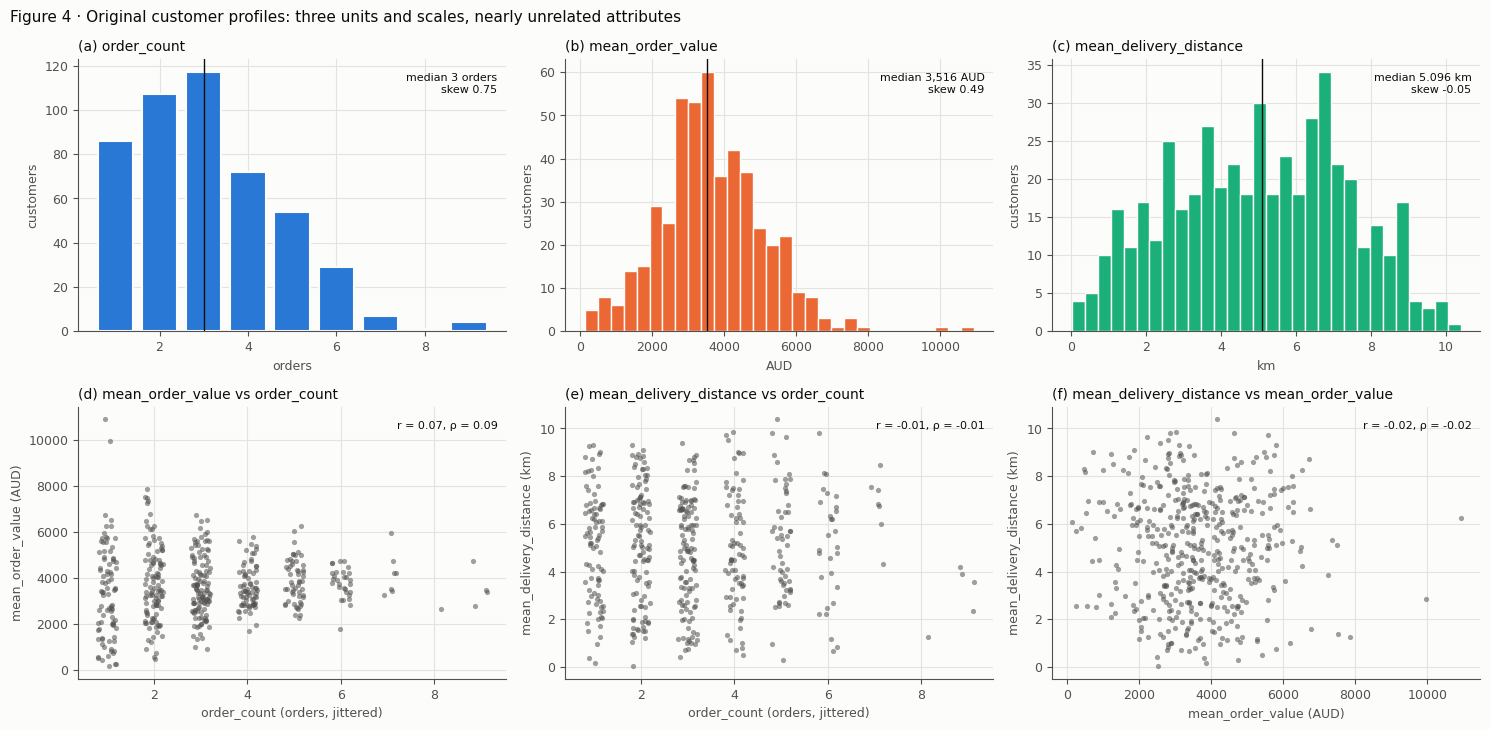

In [66]:
# BASE-01/02  Original-unit baseline of the three selected attributes (kept untransformed).
AQUA = "#1baf7a"                       # third categorical slot after BLUE and ORANGE
T3_COLOURS = {"order_count": BLUE, "mean_order_value": ORANGE, "mean_delivery_distance": AQUA}


def describe_attributes(frame):
    """Original-unit summary per attribute: domain, scale, centre, spread, shape and extremes."""
    q1, q3 = frame.quantile(0.25), frame.quantile(0.75)
    fence = 1.5 * (q3 - q1)
    return pd.DataFrame({
        "unit": [T3_UNITS[c] for c in frame], "min": frame.min(), "median": frame.median(),
        "mean": frame.mean(), "max": frame.max(), "SD": frame.std(ddof=0), "IQR": q3 - q1,
        "skew": frame.skew(), "excess kurtosis": frame.kurt(), "distinct": frame.nunique(),
        "missing": frame.isna().sum(), "zeros": frame.eq(0).sum(), "negative": frame.lt(0).sum(),
        "beyond 1.5 IQR": ((frame < q1 - fence) | (frame > q3 + fence)).sum(),
    })


baseline_summary = describe_attributes(profiles)
print(f"BASE-01  original scales, {len(profiles)} customers")
print(baseline_summary.to_string(float_format="{:,.3f}".format))

print("\nBASE-02  extreme customers. Continuous attributes: the two lowest and two highest (all three shown)")
extremes = pd.concat({attr: pd.concat([profiles.nsmallest(2, attr), profiles.nlargest(2, attr)])
                      for attr in T3_FEATURES[1:]}, names=["extreme on", "customer_id"])
print(extremes.to_string(float_format="{:,.2f}".format))
tally = profiles["order_count"].value_counts().sort_index()
print(f"order_count is discrete, so its extremes are ties: {tally.iloc[0]} customers "
      f"({tally.iloc[0] / len(profiles):.0%}) have {tally.index[0]} order, {tally.iloc[-1]} have {tally.index[-1]}")
fence_q1, fence_q3 = profiles["mean_order_value"].quantile([0.25, 0.75])
fenced = profiles.loc[profiles["mean_order_value"] > fence_q3 + 1.5 * (fence_q3 - fence_q1)]
print(f"mean_order_value beyond the upper 1.5 IQR fence: {len(fenced)} customers, AUD "
      f"{fenced['mean_order_value'].min():,.0f}-{fenced['mean_order_value'].max():,.0f}, each with "
      f"{fenced['order_count'].min()}-{fenced['order_count'].max()} orders")
print("\nspread of mean_order_value by order_count (means of more orders are more stable):")
print(profiles.groupby("order_count")["mean_order_value"].agg(customers="size", SD="std")
      .T.to_string(float_format="{:,.0f}".format))

fig, axes = plt.subplots(2, 3, figsize=(15, 7.4), facecolor=SURFACE)
axes[0, 0].bar(tally.index, tally.to_numpy(), width=0.8, color=T3_COLOURS["order_count"],
               edgecolor=SURFACE, linewidth=1.5)
for ax, attr in zip(axes[0, 1:], T3_FEATURES[1:]):
    ax.hist(profiles[attr], bins=30, color=T3_COLOURS[attr], edgecolor=SURFACE, linewidth=1)
for ax, attr, tag in zip(axes[0], T3_FEATURES, "abc"):
    median = profiles[attr].median()
    ax.axvline(median, color=INK, lw=1)
    _style(ax, f"({tag}) {attr}")
    ax.annotate(f"median {median:,.4g} {T3_UNITS[attr]}\nskew {profiles[attr].skew():.2f}",
                xy=(0.98, 0.95), xycoords="axes fraction", ha="right", va="top", fontsize=8, color=INK)
    ax.set_xlabel(T3_UNITS[attr], fontsize=9, color=MUTED)
    ax.set_ylabel("customers", fontsize=9, color=MUTED)

jitter = np.random.default_rng(RANDOM_SEED).uniform(-0.2, 0.2, len(profiles))   # display only
pairs = [("order_count", "mean_order_value"), ("order_count", "mean_delivery_distance"),
         ("mean_order_value", "mean_delivery_distance")]
for ax, (x, y), tag in zip(axes[1], pairs, "def"):
    shift = jitter if x == "order_count" else 0
    ax.scatter(profiles[x] + shift, profiles[y], s=14, color=MUTED, alpha=0.55, linewidth=0)
    _style(ax, f"({tag}) {y} vs {x}")
    ax.annotate(f"r = {profiles[x].corr(profiles[y]):.2f}, "
                f"ρ = {profiles[x].corr(profiles[y], method='spearman'):.2f}",
                xy=(0.98, 0.95), xycoords="axes fraction", ha="right", va="top", fontsize=8, color=INK)
    ax.set_xlabel(f"{x} ({T3_UNITS[x]}{', jittered' if x == 'order_count' else ''})",
                  fontsize=9, color=MUTED)
    ax.set_ylabel(f"{y} ({T3_UNITS[y]})", fontsize=9, color=MUTED)
fig.suptitle("Figure 4 · Original customer profiles: three units and scales, nearly unrelated attributes",
             x=0.01, ha="left", fontsize=11, color=INK)
plt.tight_layout()
plt.show()

In [67]:
# BASE-03  Would raw units let one attribute dominate customer-to-customer distance?
def pairwise_distances(frame):
    """Euclidean distance for every customer pair (upper triangle), in the frame's own units."""
    values = frame.to_numpy(dtype=float)
    full = np.sqrt(((values[:, None, :] - values[None, :, :]) ** 2).sum(axis=-1))
    return full[np.triu_indices(len(values), k=1)]


def distance_shares(frame):
    """Each attribute's share of the summed squared distance over all customer pairs.

    Exact identity: the sum over pairs of (x_i - x_j)^2 is n^2 times the population
    variance, so the share equals the attribute's share of total variance.
    """
    variance = frame.var(ddof=0)
    return variance / variance.sum()


def distance_drivers(frame):
    """Per attribute: typical pair gap, share of squared distance and corr(pairwise distance, |gap in it|)."""
    distances = pairwise_distances(frame)
    return pd.DataFrame({
        "unit": [T3_UNITS[c] for c in frame],
        "median gap between two customers": [np.median(pairwise_distances(frame[[c]])) for c in frame],
        "share of squared distance": distance_shares(frame),
        "corr with |gap|": [np.corrcoef(distances, pairwise_distances(frame[[c]]))[0, 1] for c in frame],
    }, index=frame.columns)


def neighbour_overlap(a, b, k=10):
    """Mean Jaccard overlap of each customer's k nearest neighbours in two representations."""
    def nearest(frame):
        values = frame.to_numpy(dtype=float)
        full = np.sqrt(((values[:, None, :] - values[None, :, :]) ** 2).sum(axis=-1))
        np.fill_diagonal(full, np.inf)
        return np.argsort(full, axis=1, kind="stable")[:, :k]
    return float(np.mean([len(set(x) & set(y)) / len(set(x) | set(y))
                          for x, y in zip(nearest(a), nearest(b))]))


raw_drivers = distance_drivers(profiles)
explicit = pd.Series({c: (pairwise_distances(profiles[[c]]) ** 2).sum() for c in profiles})
assert np.allclose(explicit / explicit.sum(), raw_drivers["share of squared distance"], rtol=1e-9)
spend_only_overlap = neighbour_overlap(profiles, profiles[["mean_order_value"]])
sd = profiles.std(ddof=0)
print(f"BASE-03  raw-unit Euclidean distance over all {len(pairwise_distances(profiles)):,} customer pairs "
      "(share verified pair by pair)")
print(raw_drivers.to_string(formatters={"median gap between two customers": "{:,.2f}".format,
                                        "share of squared distance": "{:.6%}".format,
                                        "corr with |gap|": "{:+.3f}".format}))
print(f"SD in own units: {sd['order_count']:.2f} orders, AUD {sd['mean_order_value']:,.0f}, "
      f"{sd['mean_delivery_distance']:.2f} km")
print(f"10-nearest-neighbour overlap with neighbours by mean_order_value alone: {spend_only_overlap:.3f}")

BASE-03  raw-unit Euclidean distance over all 113,526 customer pairs (share verified pair by pair)
                          unit median gap between two customers share of squared distance corr with |gap|
order_count             orders                             2.00                 0.000128%          -0.007
mean_order_value           AUD                         1,323.05                99.999615%          +1.000
mean_delivery_distance      km                             2.33                 0.000257%          -0.002
SD in own units: 1.64 orders, AUD 1,446, 2.32 km
10-nearest-neighbour overlap with neighbours by mean_order_value alone: 0.994


**Units and scale (BASE-01, BASE-03).** The attributes are measured in orders, AUD and km. A typical
pair of customers differs by 2 orders, AUD 1,323 and 2.3 km, and the SDs (1.6 orders, AUD 1,446 and
2.3 km) differ by about three orders of magnitude. In raw units `mean_order_value` supplies
**99.9996%** of the summed squared distance over all 113,526 customer pairs, an exact variance identity
verified pair by pair. Raw distance correlates +1.000 with the spending gap alone, and 99.4% of each
customer's 10 nearest neighbours are the ones spending alone would pick. A raw comparison would ignore
activity and geography because AUD numbers are larger, not because spending matters more. **Scaling is
required for this purpose.**

**Domain (BASE-01).** No attribute has missing values, zeros or negatives, and none is constant: the minima
are 1 order, AUD 139 and 0.021 km. Both scalers are therefore defined, and so are sqrt, log and log1p
(3.4), although log reacts strongly near the 0.021 km minimum.

**Distributions (Figure 4a-c).**
- `order_count` is discrete (9 values, 1-9, median 3) and mildly right-skewed (0.75); 86 customers
  (18%) have a single order and 4 have nine.
- `mean_order_value` is only moderately skewed (0.49) but heavy-tailed (excess kurtosis 1.6). The six
  customers beyond the upper 1.5 IQR fence (AUD 7,349-10,917) each have one or two orders (BASE-02).
- `mean_delivery_distance` is symmetric and bounded (0.02-10.39 km, skew −0.05) with lighter tails than
  a normal distribution (excess kurtosis −0.86). It is one fixed distance per customer (PROF-01f).

**The extremes are genuine (BASE-02).** Each extreme customer is built from orders that passed the 2.2
read-back rules (cart price, total arithmetic, haversine distance), so these are real behaviour in the
retained sample, not cleaning errors. Task 3 keeps them; trimming or winsorising would hide exactly the
customers an exploratory segmentation should notice.

**Relationships (Figure 4d-f, PROF-03).** The three attributes are nearly uncorrelated (|r| and |ρ| ≤
0.09), so none duplicates another in a distance. Panel (d) still shows one structural link: the spread of
`mean_order_value` narrows as orders accumulate (SD AUD 2,084 at one order against 913 at four), so the
most extreme spending positions belong to customers whose mean rests on one or two orders.

### 3.3 Compare standardisation and min-max scaling

z-score standardisation and min-max scaling are compared on the three attributes selected in 3.1
(SCALE-01 to SCALE-03).

SCALE-01 · 477 customers; attributes: ('order_count', 'mean_order_value', 'mean_delivery_distance')
                        original_min  original_median  original_max  original_std  z_mean  z_std    z_min    z_max  minmax_min  minmax_median  minmax_max  original_IQR    z_IQR  minmax_IQR
order_count                   1.0000           3.0000        9.0000       1.63604    -0.0    1.0 -1.28013  3.60972         0.0        0.25000         1.0         2.000  1.22246     0.25000
mean_order_value            138.9900        3516.3450    10916.7700    1445.78296     0.0    1.0 -2.43100  5.02363         0.0        0.31336         1.0      1784.560  1.23432     0.16558
mean_delivery_distance        0.0211           5.0955       10.3895       2.31928     0.0    1.0 -2.15610  2.31443         0.0        0.48941         1.0         3.558  1.53410     0.34316

SCALE-02 · Variance share of expected squared Euclidean distance
                        original  z_score  min_max
order_count                

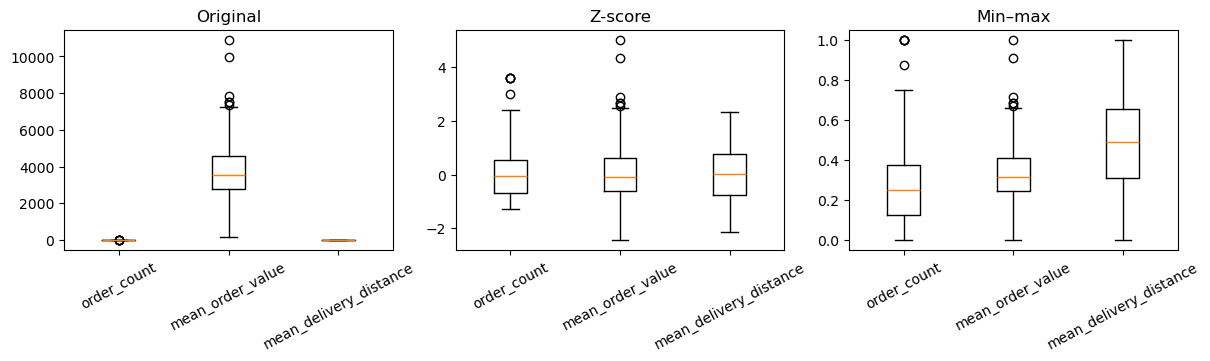

In [68]:
# Task 3.3: compare the two scalers on the three attributes selected in 3.1 (PROF-03).
# compare_scaling prints SCALE-01 and SCALE-02 and draws the original, z-score and min-max boxplots.
from group005_eda_scaling import compare_scaling

task33 = compare_scaling(profiles, T3_FEATURES)

In [69]:
# SCALE-03  Does min-max rest on a few customers? Range vs SD change without each attribute's 5 most extreme values.
def zscore(frame):
    """Population z-scores with this sample's mean and SD (the SCALE-01 convention)."""
    return (frame - frame.mean()) / frame.std(ddof=0)


def change_without_extremes(series, k=5):
    """Relative change in range and SD after dropping the k values farthest from the median."""
    kept = series.drop((series - series.median()).abs().nlargest(k).index)
    return pd.Series({"range change": np.ptp(kept) / np.ptp(series) - 1,
                      "SD change": kept.std(ddof=0) / series.std(ddof=0) - 1})


scale_shares = task33["distance_contributions"].rename(
    columns={"original": "raw", "z_score": "z-score", "min_max": "min-max"})
sensitivity = pd.DataFrame({c: change_without_extremes(profiles[c]) for c in T3_FEATURES}).T
print("SCALE-03  range vs SD change without each attribute's 5 most extreme customers")
print(sensitivity.to_string(float_format="{:+.1%}".format))

SCALE-03  range vs SD change without each attribute's 5 most extreme customers
                        range change  SD change
order_count                   -25.0%      -6.2%
mean_order_value              -33.1%      -6.9%
mean_delivery_distance         -8.6%      -1.9%


Both scalers are fitted to the 477 customer profiles from 3.1, and the untransformed baseline is kept.
z-score is `(x − mean) / population SD` and min-max is `(x − min) / (max − min)`. A constant attribute
would raise an error instead of dividing by zero; none occurs, and no attribute has zeros that matter
for scaling.

- **SCALE-01:** z-scored attributes have mean 0 and SD 1; min-max values span exactly 0 to 1, but
  their spread still differs by attribute (boxplots).
- **SCALE-02:** each attribute's share of the expected squared Euclidean distance between customers.
  z-scoring gives each one third. Min-max gives `mean_delivery_distance` 46% and `mean_order_value`
  only 16%, because min-max equalises ranges, not spread.
- **SCALE-03:** why the ranges mislead. Dropping each attribute's five most extreme customers shrinks
  its range by 9–33% but its SD by only 2–7%, so the min-max scale rests on a handful of customers
  while the z-score scale reflects typical variation.

Neither scaler changes skew or correlation. For distance-based comparison z-score is the more stable
choice; 3.5 gives the recommendation.

### 3.4 Compare nonlinear transformations

NONLIN-01 applies square root, log and log1p to each selected attribute, z-scores the result and
compares it with the untransformed attribute on the same z scale. All three attributes are strictly
positive here (`order_count` ≥ 1, `mean_order_value` ≥ AUD 139, `mean_delivery_distance` ≥ 0.021 km),
so every transform is defined. log is the most sensitive near zero, which matters for customers who
live next to a warehouse.

In [70]:
# NONLIN-01  Transform, then z-score: shape and tail effects on the three selected attributes.
TRANSFORMS = {"none": lambda s: s, "sqrt": np.sqrt, "log": np.log, "log1p": np.log1p}


def transform_effects(attr, name, top_k=max(1, round(0.01 * len(profiles)))):
    """Shape and distance effects of one transform followed by z-scoring.

    top-1% share: share of the attribute's summed squared z held by its top_k customers.
    low-tail of top 5: how many of those customers sit below the mean.
    gap ratio: (q25 - q10) / (q90 - q75) after the transform, relative to the same ratio before it;
    above 1 means the transform stretches low-end gaps relative to equal-rank high-end gaps.
    max |r|: largest |Pearson r| with the other two (untransformed) selected attributes.
    """
    x = profiles[attr]
    t = TRANSFORMS[name](x)
    z = (t - t.mean()) / t.std(ddof=0)
    top = z.pow(2).nlargest(top_k).index
    q = lambda s: s.quantile([0.10, 0.25, 0.75, 0.90]).to_numpy()
    (t10, t25, t75, t90), (x10, x25, x75, x90) = q(t), q(x)
    others = [c for c in T3_FEATURES if c != attr]
    return {"skew": t.skew(), "min z": z.min(), "max z": z.max(),
            "top-1% share": z.pow(2)[top].sum() / z.pow(2).sum(),
            "low-tail of top 5": int((z[top] < 0).sum()),
            "gap ratio": ((t25 - t10) / (t90 - t75)) / ((x25 - x10) / (x90 - x75)),
            "max |r|": max(abs(t.corr(profiles[o])) for o in others)}


assert (profiles > 0).all(axis=None), "log needs strictly positive attributes"
nonlinear_effects = pd.DataFrame({(a, m): transform_effects(a, m) for a in T3_FEATURES for m in TRANSFORMS}).T
print("NONLIN-01  transform, then z-score, on the three selected attributes")
print(nonlinear_effects.to_string(float_format="{:.3f}".format))

NONLIN-01  transform, then z-score, on the three selected attributes
                               skew  min z  max z  top-1% share  low-tail of top 5  gap ratio  max |r|
order_count            none   0.753 -1.280  3.610         0.128              0.000      1.000    0.066
                       sqrt   0.162 -1.494  2.798         0.078              0.000      1.755    0.072
                       log   -0.361 -1.691  2.113         0.045              0.000      3.106    0.076
                       log1p -0.082 -1.579  2.412         0.058              0.000      2.224    0.073
mean_order_value       none   0.487 -2.431  5.024         0.140              0.000      1.000    0.066
                       sqrt  -0.504 -3.729  3.577         0.126              3.000      1.467    0.128
                       log   -1.943 -6.169  2.331         0.249              5.000      2.158    0.186
                       log1p -1.939 -6.160  2.332         0.249              5.000      2.157    0.186
mean

**What NONLIN-01 shows.**
- `order_count`: the right tail is already moderate (top-1% share 0.13). log and sqrt lower it to
  0.05 and 0.08, but they stretch the low end: a 1-to-2-order gap then weighs 3.1× (log) or 1.8×
  (sqrt) an equal-rank gap among frequent customers.
- `mean_order_value`: log over-corrects. Skew goes from 0.49 to −1.94, the minimum z reaches −6.2 and
  all five most extreme customers become the cheapest single-order buyers (top-1% share 0.14 → 0.25).
  sqrt changes little (0.13) and loses the AUD meaning.
- `mean_delivery_distance`: symmetric already (skew −0.05). Every transform creates an artificial low
  tail from customers next to a warehouse (minimum z −3.5 sqrt, −3.6 log1p, −7.9 log).

No transform makes these attributes better for distance-based comparison, so 3.5 recommends none.
The supplementary comparison below shows the same transforms on customer `total_paid`, which 3.1
leaves out.

#### Supplementary comparison: customer `total_paid`

Compare the original `total_paid`, its square
root and `log1p` on a separate customer-level analysis copy. The purpose is to
examine how spending differences would influence future distance-based customer
comparison, not to obtain normality or to repair valid high-spending customers.

Section 3.1 leaves `total_paid` out because it repeats `order_count` × `mean_order_value`
(PROF-03), so this section is a supplementary comparison: it shows how customer spending
totals would behave under each transformation if a later analysis used them. NONLIN-01 above
applies the transformations to the three selected attributes.

#### Methods and rationale

| Representation | Definition and domain | Reason to compare / limitation |
|---|---|---|
| Original | `x`, observed finite nonnegative AUD | Retains absolute spending differences and a directly interpretable baseline. High values may dominate distances without scaling. |
| Square root | `sqrt(x)`; `x >= 0` | A fixed power transform that compresses high values more gently than a logarithm; a candidate when useful high-spending differences should remain visible. |
| Log1p | `ln(1 + x)`; mathematically `x > -1`, with `x >= 0` required here for paid amounts | Supports zero and provides a stronger compression contrast. It may overcompress the upper tail and accentuate a lower tail. The input unit is AUD (the added one corresponds to AUD 1). |

All methods must pass the observed domain checks; invalid values are reported,
not clipped, dropped or filled. Ordinary `log` requires strictly positive values.
It is not a separate candidate here: when the observed minimum is well above
AUD 1 its effect is close to `log1p`, while `log1p` also permits a future valid
zero. That convenience does not itself make it the preferred treatment.
Square root is already a power transformation (fixed exponent 0.5). Box-Cox or
Yeo-Johnson could be useful additional data-fitted alternatives, but are not
compared here; these results do not establish that square root outperforms them.
RobustScaler is a possible scaling comparison for section 3.3; its affine
transformation does not remove skewness or satisfy this nonlinear comparison.

Choose using observed distribution shape, upper/lower tail spacing, preservation
of useful customer differences and interpretability. Lower skewness alone is not
a success criterion. For a controlled distance-related comparison, apply the
same population z-score (`ddof=0`) **after** each candidate. This is a diagnostic
common scale, not a replacement for the scaling comparison in 3.3 or a final
scaling decision. Constant inputs map to zeros on this diagnostic scale;
undefined shape/spacing summaries are labelled missing rather than interpreted.

In [71]:
# NL-01: isolate and label the available, validated analysis sample.
nonlinear_protected_paths = [
    *[p for p in DATA_DIR.rglob("*") if p.is_file()],
    *[p for p in (DIRTY_OUTPUT, MISSING_OUTPUT, OUTLIER_OUTPUT, AUDIT_OUTPUT)
      if p.is_file()],
]
nonlinear_file_hashes_before = {
    str(p): hashlib.sha256(p.read_bytes()).hexdigest()
    for p in nonlinear_protected_paths
}
nonlinear_audit_before = audit.to_frame().copy(deep=True)
nonlinear_batch_frames, nonlinear_batch_rows = [], []
for nonlinear_batch, nonlinear_raw_path, nonlinear_clean_path, nonlinear_variable in (
    ("dirty", DIRTY_INPUT, DIRTY_OUTPUT, "clean_dirty"),
    ("missing", MISSING_INPUT, MISSING_OUTPUT, "clean_missing"),
    ("outlier", OUTLIER_INPUT, OUTLIER_OUTPUT, "clean_outlier"),
):
    nonlinear_ready = nonlinear_variable in globals() and nonlinear_clean_path.is_file()
    if not nonlinear_ready:
        nonlinear_batch_rows.append({
            "batch": nonlinear_batch, "included_orders": 0,
            "status": "EXCLUDED: clean CSV or completed in-memory batch unavailable",
        })
        continue
    nonlinear_frame = pd.read_csv(nonlinear_clean_path, dtype=str, keep_default_na=False)
    pd.testing.assert_frame_equal(
        nonlinear_frame.set_index("order_id").sort_index(),
        globals()[nonlinear_variable].set_index("order_id").sort_index(),
    )  # Reject stale on-disk results rather than silently treating them as final.
    if tuple(nonlinear_frame.columns) != ORDER_SCHEMA:
        raise ValueError(f"{nonlinear_batch}: wrong clean CSV schema")
    if not nonlinear_frame.order_id.is_unique or nonlinear_frame.eq("").any().any():
        raise ValueError(f"{nonlinear_batch}: duplicate order IDs or incomplete data")
    nonlinear_original = pd.read_csv(nonlinear_raw_path, dtype=str, keep_default_na=False)
    nonlinear_expected_ids = set(nonlinear_original.order_id)
    if nonlinear_batch == "outlier":
        nonlinear_removed = nonlinear_audit_before.loc[
            nonlinear_audit_before.source_file.eq(nonlinear_raw_path.name)
            & nonlinear_audit_before.issue_type.eq("outlier_row"), "record_key"]
        nonlinear_expected_ids -= set(nonlinear_removed)
    elif len(nonlinear_frame) != 500:
        raise ValueError(f"{nonlinear_batch}: expected 500 retained orders")
    if set(nonlinear_frame.order_id) != nonlinear_expected_ids:
        raise ValueError(f"{nonlinear_batch}: clean IDs do not reconcile to source/removals")
    if not check_shared_rules(nonlinear_frame).all().all():
        raise ValueError(f"{nonlinear_batch}: resolve business-rule inconsistencies first")
    nonlinear_batch_frames.append(nonlinear_frame.assign(source_batch=nonlinear_batch))
    nonlinear_batch_rows.append({"batch": nonlinear_batch,
        "included_orders": len(nonlinear_frame), "status": "INCLUDED: checked current clean output"})
if not nonlinear_batch_frames:
    raise RuntimeError("No completed clean batches are available for the nonlinear comparison")
nonlinear_batch_report = pd.DataFrame(nonlinear_batch_rows)
nonlinear_orders = pd.concat(nonlinear_batch_frames, ignore_index=True)
if not nonlinear_orders.order_id.is_unique or nonlinear_orders.customer_id.str.strip().eq("").any():
    raise ValueError("Customer aggregation requires unique orders and nonempty customer IDs")
nonlinear_orders["order_total"] = pd.to_numeric(nonlinear_orders.order_total, errors="raise")
if not np.isfinite(nonlinear_orders.order_total).all() or nonlinear_orders.order_total.lt(0).any():
    raise ValueError("Paid amounts must be finite and nonnegative; investigate instead of clipping")
nonlinear_total_paid = nonlinear_orders.groupby("customer_id", sort=True).order_total.sum().rename("total_paid")
nonlinear_total_paid_before = nonlinear_total_paid.copy(deep=True)
nonlinear_sample_label = (
    f"{len(nonlinear_orders)} retained orders | {len(nonlinear_total_paid)} customers"
)
print("NL-01  " + nonlinear_sample_label)
print(nonlinear_batch_report.to_string(index=False))
print("Excluded batches contribute no orders. Retained outliers are not restored. "
      "These are sample totals including delivery after the item discount, not profit or lifetime value.")


NL-01  1476 retained orders | 477 customers
  batch  included_orders                                 status
  dirty              500 INCLUDED: checked current clean output
missing              500 INCLUDED: checked current clean output
outlier              476 INCLUDED: checked current clean output
Excluded batches contribute no orders. Retained outliers are not restored. These are sample totals including delivery after the item discount, not profit or lifetime value.


In [72]:
def compare_total_paid(total_paid):
    """Return three candidate representations and diagnostics without mutation."""
    if not isinstance(total_paid, pd.Series) or total_paid.empty or not total_paid.index.is_unique:
        raise ValueError("Provide a nonempty Series indexed by unique customer IDs")
    original = pd.to_numeric(total_paid, errors="raise").astype(float).copy()
    if not np.isfinite(original).all() or original.lt(0).any():
        raise ValueError("total_paid must be finite and nonnegative")
    candidates = pd.DataFrame({
        "Original": original,
        "Square root": np.sqrt(original),
        "Log1p": np.log1p(original),
    }, index=original.index)
    standardised = pd.DataFrame(index=original.index)
    distribution_rows, spacing_rows = [], []
    for method in candidates:
        values = candidates[method]
        constant = values.nunique() == 1
        sd = float(values.std(ddof=0))
        standardised[method] = 0.0 if constant else (values - values.mean()) / sd
        q = values.quantile([0.01, 0.25, 0.5, 0.75, 0.95, 0.99])
        iqr = float(q.loc[0.75] - q.loc[0.25])
        z = standardised[method]
        distribution_rows.append({
            "method": method, "n": len(values), "min": values.min(),
            "median": q.loc[0.5], "p95": q.loc[0.95], "max": values.max(),
            "skew": np.nan if constant else values.skew(),
        })
        spacing_rows.append({
            "method": method,
            "upper_gap/IQR (p99-p50)": (q.loc[0.99] - q.loc[0.5]) / iqr if iqr > 0 else np.nan,
            "lower_gap/IQR (p50-p01)": (q.loc[0.5] - q.loc[0.01]) / iqr if iqr > 0 else np.nan,
            "z_min": z.min(), "z_max": z.max(),
            "z_p95_minus_p50": z.quantile(0.95) - z.quantile(0.5),
            "constant": constant,
        })
    return (candidates, standardised,
            pd.DataFrame(distribution_rows).set_index("method"),
            pd.DataFrame(spacing_rows).set_index("method"))


(non_linear_values, nonlinear_zscores, nonlinear_distribution,
 nonlinear_spacing) = compare_total_paid(nonlinear_total_paid)
nonlinear_domain_report = pd.Series({
    "customers": len(nonlinear_total_paid), "missing": nonlinear_total_paid.isna().sum(),
    "negative": nonlinear_total_paid.lt(0).sum(), "zero": nonlinear_total_paid.eq(0).sum(),
    "unique_values": nonlinear_total_paid.nunique(),
    "min_AUD": nonlinear_total_paid.min(), "max_AUD": nonlinear_total_paid.max(),
})
print("NL-02  observed domain and candidate distributions — " + nonlinear_sample_label)
print(nonlinear_domain_report.to_string())
print(nonlinear_distribution.to_string(float_format=lambda value: f"{value:.6f}"))
print("Only Original is in AUD; sqrt and log1p have transformed units. "
      "NaN shape/spacing summaries mean undefined, not missing customer values.")
print("NL-03  relative tail spacing and a common z-score scale (ddof=0):")
print(nonlinear_spacing.to_string(float_format=lambda value: f"{value:.6f}"))
print("IQR-based gaps are dimensionless. Their comparison is unchanged by a positive "
      "affine rescaling. Common-scale z gaps help separate nonlinear effects from units.")


NL-02  observed domain and candidate distributions — 1476 retained orders | 477 customers
customers          477.00
missing              0.00
negative             0.00
zero                 0.00
unique_values      477.00
min_AUD            138.99
max_AUD          42563.75
               n        min       median          p95          max      skew
method                                                                      
Original     477 138.990000 10459.460000 24968.000000 42563.750000  0.828671
Square root  477  11.789402   102.271501   158.012657   206.309840 -0.022262
Log1p        477   4.941571     9.255358    10.125390    10.658782 -1.311604
Only Original is in AUD; sqrt and log1p have transformed units. NaN shape/spacing summaries mean undefined, not missing customer values.
NL-03  relative tail spacing and a common z-score scale (ddof=0):
             upper_gap/IQR (p99-p50)  lower_gap/IQR (p50-p01)     z_min    z_max  z_p95_minus_p50  constant
method                          

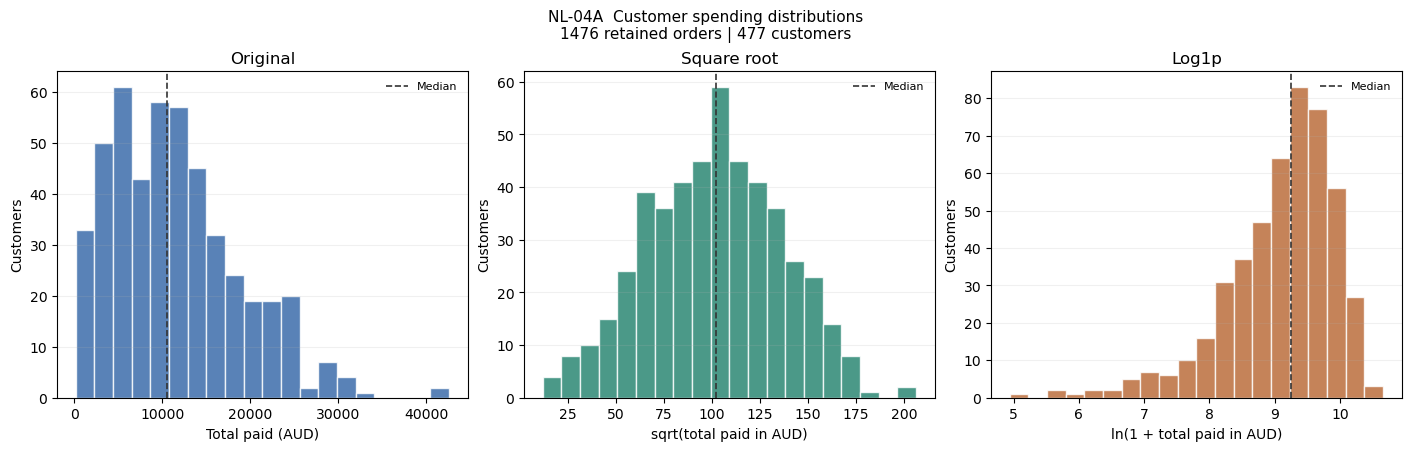

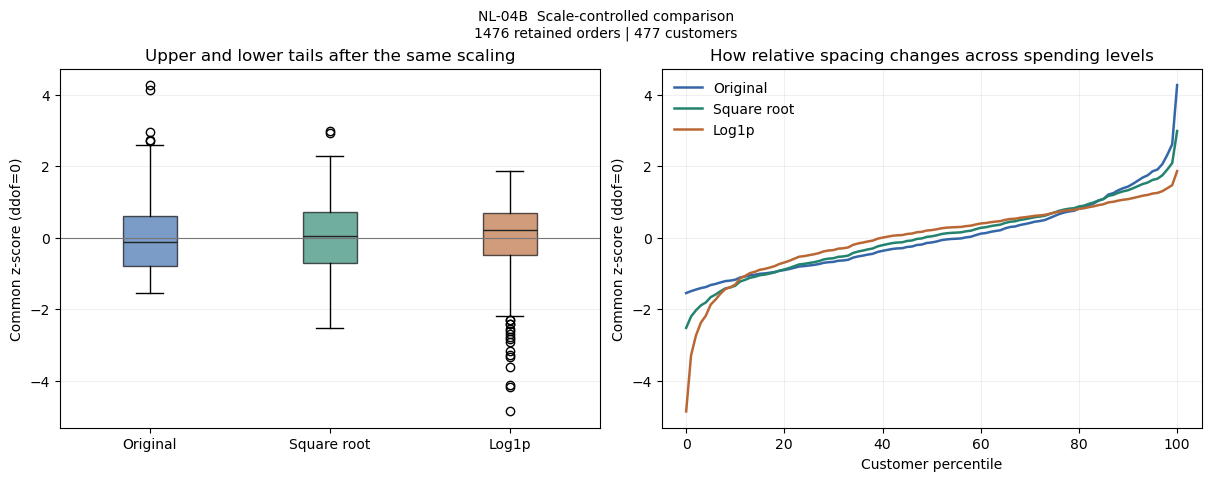

Boxplot fliers are descriptive customer extremes, not errors or rows to delete. Monotonic transformations preserve ranking but change gaps. These plots do not prove that meaningful customer clusters exist.


In [73]:
# NL-04: distribution shape on each method's own axis, then a common scale.
nonlinear_colours = {"Original": "#3567A8", "Square root": "#23836E", "Log1p": "#B96835"}
nonlinear_units = {"Original": "Total paid (AUD)",
                   "Square root": "sqrt(total paid in AUD)",
                   "Log1p": "ln(1 + total paid in AUD)"}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), constrained_layout=True)
for ax, method in zip(axes, non_linear_values.columns):
    values = non_linear_values[method]
    ax.hist(values, bins=20, color=nonlinear_colours[method], alpha=0.82, edgecolor="white")
    ax.axvline(values.median(), color="#333333", linestyle="--", linewidth=1.2, label="Median")
    ax.set(title=method, xlabel=nonlinear_units[method], ylabel="Customers")
    ax.legend(frameon=False, fontsize=8)
    ax.grid(axis="y", alpha=0.18)
fig.suptitle("NL-04A  Customer spending distributions\n" + nonlinear_sample_label, fontsize=11)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), constrained_layout=True)
boxes = axes[0].boxplot([nonlinear_zscores[m] for m in nonlinear_zscores],
                        tick_labels=list(nonlinear_zscores), patch_artist=True,
                        showfliers=True, medianprops={"color": "#222222"})
for box, method in zip(boxes["boxes"], nonlinear_zscores):
    box.set_facecolor(nonlinear_colours[method]); box.set_alpha(0.65)
axes[0].set(ylabel="Common z-score (ddof=0)", title="Upper and lower tails after the same scaling")
axes[0].axhline(0, color="#777777", linewidth=0.8)
axes[0].grid(axis="y", alpha=0.18)
nonlinear_percentiles = np.linspace(0, 1, 101)
for method in nonlinear_zscores:
    axes[1].plot(100 * nonlinear_percentiles,
                 nonlinear_zscores[method].quantile(nonlinear_percentiles),
                 color=nonlinear_colours[method], label=method, linewidth=1.8)
axes[1].set(xlabel="Customer percentile", ylabel="Common z-score (ddof=0)",
            title="How relative spacing changes across spending levels")
axes[1].legend(frameon=False)
axes[1].grid(alpha=0.18)
fig.suptitle("NL-04B  Scale-controlled comparison\n" + nonlinear_sample_label, fontsize=10)
plt.show()
print("Boxplot fliers are descriptive customer extremes, not errors or rows to delete. "
      "Monotonic transformations preserve ranking but change gaps. These plots "
      "do not prove that meaningful customer clusters exist.")


In [74]:
# NL-05: validate the analysis and verify that cleaning/audit artefacts are untouched.
nonlinear_checks = []
def nonlinear_check(name, condition, result):
    nonlinear_checks.append({"check": name, "passed": bool(condition), "observed": result})

nonlinear_check("Customer IDs and row count",
    non_linear_values.index.equals(nonlinear_total_paid.index)
    and nonlinear_zscores.index.equals(nonlinear_total_paid.index)
    and len(non_linear_values) == len(nonlinear_total_paid),
    f"{len(non_linear_values)} customers, identical index")
nonlinear_check("Domain and finite outputs",
    nonlinear_total_paid.ge(0).all() and np.isfinite(non_linear_values.to_numpy()).all()
    and np.isfinite(nonlinear_zscores.to_numpy()).all(),
    "nonnegative inputs; no NaN/inf introduced")
nonlinear_check("Raw baseline unchanged",
    nonlinear_total_paid.equals(nonlinear_total_paid_before)
    and non_linear_values["Original"].equals(nonlinear_total_paid.astype(float)),
    "original totals and customer membership retained")
nonlinear_check("Paid-total aggregation reconciles",
    np.isclose(nonlinear_total_paid.sum(), nonlinear_orders.order_total.sum(), rtol=1e-12, atol=1e-7),
    f"customer/order sums both AUD {nonlinear_total_paid.sum():.2f}")
nonlinear_check("Ranks and ties preserved",
    all(non_linear_values[m].rank(method="average").equals(
        non_linear_values["Original"].rank(method="average")) for m in non_linear_values),
    "all three representations have the same customer ranks")
nonlinear_check("Inverse recovery",
    np.allclose(non_linear_values["Square root"] ** 2, nonlinear_total_paid, rtol=1e-12, atol=1e-8)
    and np.allclose(np.expm1(non_linear_values["Log1p"]), nonlinear_total_paid, rtol=1e-12, atol=1e-8),
    "sqrt squared and expm1(log1p) recover baseline within floating-point tolerance")
nonlinear_check("Common-scale convention",
    all(np.allclose(nonlinear_zscores[m], 0) if non_linear_values[m].nunique() == 1
        else np.isclose(nonlinear_zscores[m].mean(), 0, atol=1e-12)
        and np.isclose(nonlinear_zscores[m].std(ddof=0), 1, atol=1e-12)
        for m in non_linear_values),
    "nonconstant columns: mean 0 and population SD 1; constants: zeros")
nonlinear_check("No cleaning/audit changes",
    nonlinear_audit_before.equals(audit.to_frame()) and all(
        p.is_file() and hashlib.sha256(p.read_bytes()).hexdigest() == nonlinear_file_hashes_before[str(p)]
        for p in nonlinear_protected_paths),
    f"audit entries and {len(nonlinear_protected_paths)} source/output files unchanged")
nonlinear_validation = pd.DataFrame(nonlinear_checks)
print("NL-05  validation:")
print(nonlinear_validation.to_string(index=False))
if not nonlinear_validation.passed.all():
    raise AssertionError("Investigate nonlinear comparison validation failures")

# NL-06: interpret the observed run instead of hard-coding earlier sample results.
nonlinear_skews = nonlinear_distribution["skew"]
nonlinear_square_root_supported = (
    np.isfinite(nonlinear_skews).all()
    and abs(nonlinear_skews["Square root"]) < abs(nonlinear_skews["Original"])
    and abs(nonlinear_skews["Square root"]) < abs(nonlinear_skews["Log1p"])
    and nonlinear_spacing.loc["Square root", "upper_gap/IQR (p99-p50)"]
        > nonlinear_spacing.loc["Log1p", "upper_gap/IQR (p99-p50)"]
)
print("\nNL-06  interpretation — " + nonlinear_sample_label)
print(f"Observed skewness: original={nonlinear_skews['Original']:.3f}; "
      f"sqrt={nonlinear_skews['Square root']:.3f}; log1p={nonlinear_skews['Log1p']:.3f}.")
print("Original / sqrt / log1p upper-tail gaps relative to IQR: "
      + " / ".join(f"{nonlinear_spacing.loc[m, 'upper_gap/IQR (p99-p50)']:.3f}"
                   for m in non_linear_values) + ".")
if nonlinear_square_root_supported:
    print("The current sample supports prioritising square root as a candidate: "
          "it reduces the observed right-skew without the marked left-skew of log1p, "
          "and retains more upper-tail spacing relative to the middle half of customers. "
          "This is a moderate-compression trade-off, not a normality or clustering guarantee.")
else:
    print("The current sample does not reproduce the proposed square-root rationale; "
          "review the shape and tail diagnostics before selecting a treatment.")
print("Lower skewness alone is insufficient. The common-scale plots show both tails; "
      "whether spending gaps should be compressed is a business/analysis choice. "
      "Raw AUD differences remain easier to interpret; log1p may suit a stronger "
      "relative-spending emphasis. No customer is deleted or labelled erroneous here.")
print("total_paid is not one of the three selected attributes (PROF-03); the recommendation for "
      "the selected attributes is REC-01 in 3.5, based on NONLIN-01.")


NL-05  validation:
                            check  passed                                                                       observed
       Customer IDs and row count    True                                                 477 customers, identical index
        Domain and finite outputs    True                                      nonnegative inputs; no NaN/inf introduced
           Raw baseline unchanged    True                               original totals and customer membership retained
Paid-total aggregation reconciles    True                                        customer/order sums both AUD 5467474.08
         Ranks and ties preserved    True                         all three representations have the same customer ranks
                 Inverse recovery    True sqrt squared and expm1(log1p) recover baseline within floating-point tolerance
          Common-scale convention    True              nonconstant columns: mean 0 and population SD 1; constants: zeros
        No cl

**Interpretation boundaries.** NL-01 identifies the actual included
batches and customer count; NL-02/03 quantify shape and relative spacing;
NL-04 displays the distributions and both tails under a common scale; NL-05
checks domain, identity, reversibility, aggregation and preservation; NL-06
states the rationale from the current run. The comparison
is descriptive and uses no holdout or fitted prediction model. It does not claim
independent predictive accuracy or select customer clusters.

The preferred candidate is not chosen solely by normality, a minimum skewness
score, or a smaller standard deviation in different units. The square-root
rationale is a balance between reducing upper-tail emphasis and preserving more
high-spending differentiation than log1p. Other power transformations have not been
ruled out by this three-method comparison.

`total_paid` includes delivery after the item discount. It is not profit, merchandise-only
revenue or lifetime customer value. Nonlinear transformations preserve ranking but not
original monetary distances, and the final choice depends on how customers are to be
compared, not just on distribution shape.

**Sources:** A2 specification, Section 4 Task 3 (customer-level aggregation,
nonlinear comparison, domain checks, sequencing and recommendation boundaries);
FIT5196 Week 8 *Data Transformation (I)*, slides 3 and 17 (purpose-specific
transformation and log scaling). All numerical evidence above is recomputed
from this group's retained clean outputs; no earlier provisional statistics are
hard-coded as final results.

### 3.5 Recommendations, boundaries and limitations

3.5 turns the evidence of 3.2-3.4 into one treatment per attribute:

- **EVID-01** recomputes every number the recommendation cites with one pure function of the customer
  profiles, and checks it against the tables 3.2, 3.3 and 3.4 display, so REC-01 cannot disagree with them.
- **DIST-01** measures what each alternative would do to customer comparison: how many of each customer's
  10 nearest neighbours stay the same, and how well the ranking of all pairwise distances is kept.
- **REC-01** is the required table, generated from that evidence, followed by the discussion of distances,
  extremes, interpretability, redundancy and limits.
- **RERUN-01** re-reads the submitted CSVs and re-derives the profiles, the evidence and REC-01 from disk.

In [75]:
# EVID-01  Every number REC-01 cites, recomputed by one pure function of the customer profiles (so RERUN-01
# can repeat it on the files on disk), then checked against what 3.2, 3.3 and 3.4 display.
T3_TRANSFORMS = {"none": lambda s: s, "sqrt": np.sqrt, "log": np.log, "log1p": np.log1p}
T3_DOMAIN = {"none": lambda s: s.notna(), "sqrt": lambda s: s >= 0, "log": lambda s: s > 0,
             "log1p": lambda s: s > -1}
T3_K = 10                                   # nearest neighbours compared in DIST-01


def standardise(frame):
    """Population z-score (ddof=0, as in 3.3); a constant attribute raises instead of dividing by zero."""
    sd = frame.std(ddof=0)
    if (sd == 0).any():
        raise ValueError(f"constant attribute(s): {list(sd.index[sd == 0])}")
    return (frame - frame.mean()) / sd


def rescale(frame, centre, spread):
    """(x - centre) / spread per attribute; a zero spread raises instead of dividing by zero."""
    if (spread == 0).any():
        raise ValueError(f"zero spread: {list(spread.index[spread == 0])}")
    return (frame - centre) / spread


def transform_metrics(frame, attr, name):
    """NONLIN-01's metrics for one attribute under one transform followed by z-scoring."""
    x = frame[attr]
    if not T3_DOMAIN[name](x).all():
        raise ValueError(f"{name} is undefined for some {attr} values")
    t = T3_TRANSFORMS[name](x)
    z = standardise(t.to_frame())[attr]
    top = z.pow(2).nlargest(max(1, round(0.01 * len(frame)))).index
    q = lambda s: s.quantile([0.10, 0.25, 0.75, 0.90]).to_numpy()
    (t10, t25, t75, t90), (x10, x25, x75, x90) = q(t), q(x)
    return {"skew": t.skew(), "min z": z.min(), "max z": z.max(),
            "top-1% share": z.pow(2)[top].sum() / z.pow(2).sum(),
            "low-tail of top 5": int((z[top] < 0).sum()),
            "gap ratio": ((t25 - t10) / (t90 - t75)) / ((x25 - x10) / (x90 - x75)),
            "max |r|": max(abs(t.corr(frame[o])) for o in frame if o != attr)}


def range_vs_sd_change(series, k=5):
    """Relative change in range and SD after dropping the k values farthest from the median (SCALE-03)."""
    kept = series.drop((series - series.median()).abs().nlargest(k).index)
    return pd.Series({"range change": np.ptp(kept) / np.ptp(series) - 1,
                      "SD change": kept.std(ddof=0) / series.std(ddof=0) - 1})


def local_shares(frame, k=T3_K):
    """Each attribute's share of the squared distance from every customer to its k nearest neighbours."""
    values = frame.to_numpy(dtype=float)
    full = np.sqrt(((values[:, None, :] - values[None, :, :]) ** 2).sum(axis=-1))
    np.fill_diagonal(full, np.inf)
    gaps = (values[np.argsort(full, axis=1, kind="stable")[:, :k]] - values[:, None, :]) ** 2
    return pd.Series(gaps.sum(axis=(0, 1)) / gaps.sum(), index=frame.columns)


def task3_evidence(candidates, features=T3_FEATURES, k=T3_K):
    """The 3.2-3.4 metrics REC-01 cites, plus DIST-01, as a pure function of the four candidate attributes."""
    frame = candidates[features]
    z = standardise(frame)
    q1, q3 = frame.quantile(0.25), frame.quantile(0.75)
    representations = {
        "raw units, no scaling": frame,
        "min-max scaling": rescale(frame, frame.min(), frame.max() - frame.min()),
        "robust scaling (median/IQR)": rescale(frame, frame.median(), q3 - q1),
        **{f"{name}({attr}), then z-score": standardise(frame.assign(**{attr: T3_TRANSFORMS[name](frame[attr])}))
           for attr in features for name in ("sqrt", "log", "log1p")},
    }
    z_ranks = pd.Series(pairwise_distances(z)).rank()
    return {
        "baseline": describe_attributes(frame).drop(columns="unit").astype(float),
        "parameters": pd.DataFrame({"mean": frame.mean(), "SD": frame.std(ddof=0)}),
        "shares": pd.DataFrame({"raw": distance_shares(frame), "z-score": distance_shares(z),
                                "min-max": distance_shares(representations["min-max scaling"])}),
        "fragility": pd.DataFrame({c: range_vs_sd_change(frame[c]) for c in features}).T,
        "nonlinear": pd.DataFrame({(a, m): transform_metrics(frame, a, m)
                                   for a in features for m in T3_TRANSFORMS}).T,
        "total_paid skew": pd.Series({m: T3_TRANSFORMS[m](candidates["total_paid"]).skew()
                                      for m in T3_TRANSFORMS}),
        "neighbourhood": pd.DataFrame(
            [{"alternative": label, f"{k}-NN overlap": neighbour_overlap(z, rep, k),
              "rank corr of pair distances": z_ranks.corr(pd.Series(pairwise_distances(rep)).rank())}
             for label, rep in representations.items()]).set_index("alternative"),
        "local shares": local_shares(z, k),
    }


def max_gap(a, b):
    """Largest absolute difference between two aligned numeric tables (inf if their shapes differ)."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    return float(np.max(np.abs(a - b))) if a.shape == b.shape else float("inf")


evidence = task3_evidence(profile_candidates)
helper = globals().get("task33")              # 3.3's helper output, when group005_eda_scaling.py is present
nl_cols = list(evidence["nonlinear"].columns)
agreement = {
    "3.2 BASE-01 summary": max_gap(evidence["baseline"], baseline_summary.drop(columns="unit").astype(float)),
    "3.3 SCALE-02 shares (compare_scaling)": (
        max_gap(evidence["shares"][["raw", "z-score", "min-max"]],
                helper["distance_contributions"].loc[T3_FEATURES, ["original", "z_score", "min_max"]])
        if helper is not None else np.nan),
    "3.3 SCALE-03 range/SD change": max_gap(evidence["fragility"], sensitivity.loc[T3_FEATURES, ["range change", "SD change"]]),
    "3.4 NONLIN-01 metrics": max_gap(evidence["nonlinear"], nonlinear_effects.loc[evidence["nonlinear"].index, nl_cols]),
    "3.4 NL-01 customer total_paid": max_gap(profile_candidates["total_paid"],
                                             nonlinear_total_paid.reindex(profile_candidates.index)),
}
agreement = pd.DataFrame({"max |difference|": agreement}).assign(
    agrees=lambda t: t["max |difference|"].le(1e-9) | t["max |difference|"].isna())
print("EVID-01  REC-01's evidence, recomputed here, against the tables shown in 3.2-3.4 "
      "(NaN = that section's helper is unavailable, so it is not compared):")
print(agreement.to_string(formatters={"max |difference|": "{:.1e}".format}))
assert agreement["agrees"].all(), "3.5 and the 3.2-3.4 tables disagree: resolve before recommending"

domain = pd.DataFrame({m: {a: bool(T3_DOMAIN[m](profiles[a]).all()) for a in T3_FEATURES} for m in T3_TRANSFORMS})
print("\ntransform defined for every customer (domain check on the observed minima "
      f"{profiles.min().round(3).to_dict()}):")
print(domain.to_string())
print("\nfitted z-score parameters (population mean and SD of the retained customers):")
print(evidence["parameters"].to_string(float_format="{:,.4f}".format))

EVID-01  REC-01's evidence, recomputed here, against the tables shown in 3.2-3.4 (NaN = that section's helper is unavailable, so it is not compared):
                                      max |difference|  agrees
3.2 BASE-01 summary                            0.0e+00    True
3.3 SCALE-02 shares (compare_scaling)          0.0e+00    True
3.3 SCALE-03 range/SD change                   0.0e+00    True
3.4 NONLIN-01 metrics                          0.0e+00    True
3.4 NL-01 customer total_paid                  0.0e+00    True

transform defined for every customer (domain check on the observed minima {'order_count': 1.0, 'mean_order_value': 138.99, 'mean_delivery_distance': 0.021}):
                        none  sqrt   log  log1p
order_count             True  True  True   True
mean_order_value        True  True  True   True
mean_delivery_distance  True  True  True   True

fitted z-score parameters (population mean and SD of the retained customers):
                             mean         

#### How much does each choice change who is similar? - DIST-01

A treatment matters for segmentation only through the distances it produces. Each alternative from 3.3
and 3.4 is compared with the candidate recommendation (no nonlinear transform, then z-score on all three
attributes) in two ways: the mean Jaccard overlap of each customer's 10 nearest neighbours (local
comparisons), and the rank correlation of all 113,526 pairwise distances (global comparisons). Robust
(median/IQR) scaling is added as a sensitivity check. This measures how much a choice moves
neighbourhoods, not whether clusters exist or are good.

DIST-01  Euclidean neighbourhoods of 477 customers, each alternative vs 'none, then z-score' (1 = identical neighbours / identical ranking of all pairs)
                                             10-NN overlap  rank corr of pair distances
alternative                                                                            
raw units, no scaling                                0.069                        0.506
log(mean_delivery_distance), then z-score            0.680                        0.933
min-max scaling                                      0.708                        0.956
log(order_count), then z-score                       0.740                        0.941
log1p(mean_delivery_distance), then z-score          0.753                        0.962
log(mean_order_value), then z-score                  0.761                        0.940
log1p(mean_order_value), then z-score                0.762                        0.940
log1p(order_count), then z-score                     0.

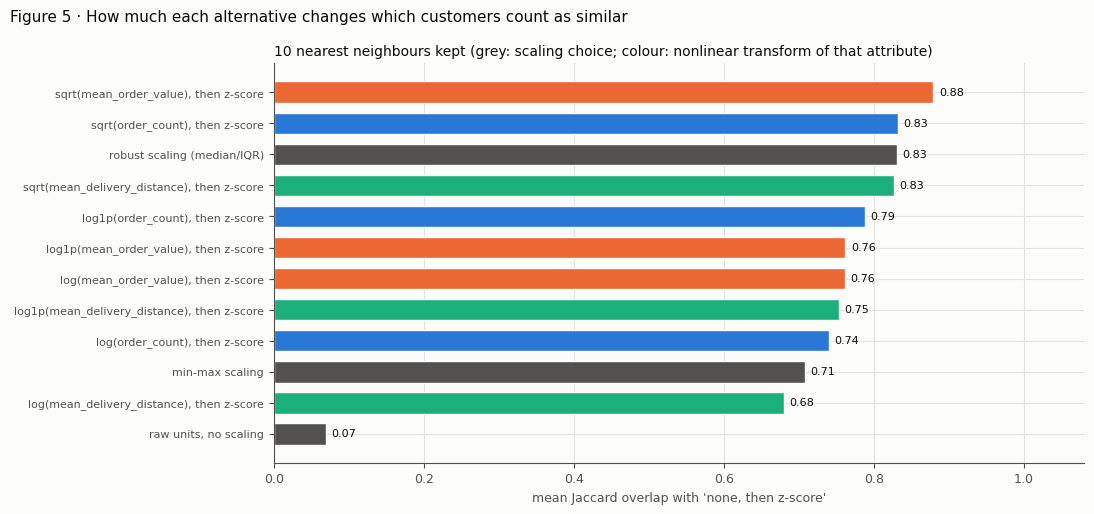

In [76]:
# DIST-01  What would each alternative do to customer comparison? Against the candidate recommendation
# (no nonlinear transform, then z-score), how many of each customer's 10 nearest neighbours stay the same?
neighbourhood = evidence["neighbourhood"].sort_values(f"{T3_K}-NN overlap")
print(f"DIST-01  Euclidean neighbourhoods of {len(profiles)} customers, each alternative vs "
      "'none, then z-score' (1 = identical neighbours / identical ranking of all pairs)")
print(neighbourhood.to_string(float_format="{:.3f}".format))
local = evidence["local shares"]
print(f"\nunder z-score each attribute holds exactly 1/3 of the squared distance over all pairs, but among each "
      f"customer's {T3_K} nearest neighbours the shares are "
      + ", ".join(f"{attr} {share:.0%}" for attr, share in local.items()))

colour = {label: (MUTED if label.startswith(("raw", "min-max", "robust"))
                  else next(T3_COLOURS[a] for a in T3_FEATURES if f"({a})" in label))
          for label in neighbourhood.index}
fig, ax = plt.subplots(figsize=(11, 5.2), facecolor=SURFACE)
ax.barh(neighbourhood.index, neighbourhood[f"{T3_K}-NN overlap"], color=[colour[l] for l in neighbourhood.index],
        edgecolor=SURFACE, height=0.7)
for y, value in enumerate(neighbourhood[f"{T3_K}-NN overlap"]):
    ax.annotate(f"{value:.2f}", xy=(value, y), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8, color=INK)
ax.set_xlim(0, 1.08)
_style(ax, f"{T3_K} nearest neighbours kept (grey: scaling choice; colour: nonlinear transform of that attribute)")
ax.set_xlabel("mean Jaccard overlap with 'none, then z-score'", fontsize=9, color=MUTED)
ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Figure 5 · How much each alternative changes which customers count as similar",
             x=0.01, ha="left", fontsize=11, color=INK)
plt.tight_layout()
plt.show()

#### Recommendation table - REC-01

Each row states the nonlinear transformation and the scaling separately. Had both been recommended, the
order would be fixed as nonlinear transform first, then scaling: z-scores are negative for every customer
below the mean, where log and sqrt are undefined, and scaling last is what keeps each attribute's weight
equal. No nonlinear transform is recommended here, so each treatment is a single z-score step, shown
with its fitted parameters so it can be applied to new customers unchanged.

In [77]:
# REC-01  Recommendation table, generated from the EVID-01 evidence so every number matches this run.
RECOMMENDED = {attr: ("none", "z-score") for attr in T3_FEATURES}   # (nonlinear, scaling), applied in that order


def recommendation_table(ev, candidates, removed_customers, lost_customers):
    """One row per selected attribute: methods, observed effect with evidence IDs, treatment, justification."""
    sh, se, ne, nb = ev["shares"], ev["fragility"], ev["nonlinear"], ev["neighbourhood"]
    base, par, local, tp = ev["baseline"], ev["parameters"], ev["local shares"], ev["total_paid skew"]
    m = lambda attr, name, metric: ne.at[(attr, name), metric]
    moved = lambda name, attr: 1 - nb.at[f"{name}({attr}), then z-score", f"{T3_K}-NN overlap"]
    q10, q25, q75, q90 = candidates["order_count"].quantile([0.10, 0.25, 0.75, 0.90])
    value = candidates["mean_order_value"]
    v1, v3 = value.quantile([0.25, 0.75])
    fenced = candidates.loc[(value < v1 - 1.5 * (v3 - v1)) | (value > v3 + 1.5 * (v3 - v1)), "order_count"]
    methods = ("raw; z-score and min-max (3.3); sqrt, log and log1p, each then z-score (3.4); "
               f"{T3_K}-nearest-neighbour check (DIST-01)")

    def treatment(attr):
        nonlinear, scaling = RECOMMENDED[attr]
        return (f"Nonlinear: {nonlinear}. Scaling: {scaling}, z = (x - {par.at[attr, 'mean']:,.3f}) / "
                f"{par.at[attr, 'SD']:,.3f} {T3_UNITS[attr]}.")

    rows = [
        {"Attribute": "order_count",
         "Observed effect / evidence reference":
             f"Discrete: {base.at['order_count', 'distinct']:.0f} values, {base.at['order_count', 'min']:.0f}-"
             f"{base.at['order_count', 'max']:.0f} orders, median {base.at['order_count', 'median']:.0f}, skew "
             f"{base.at['order_count', 'skew']:.2f}, no zeros (BASE-01). Raw units give it "
             f"{sh.at['order_count', 'raw']:.4%} of squared distance (BASE-03); z-score "
             f"{sh.at['order_count', 'z-score']:.0%}, min-max {sh.at['order_count', 'min-max']:.0%} (SCALE-02). "
             f"Tail is moderate: the top 1% of customers hold {m('order_count', 'none', 'top-1% share'):.0%} of its "
             f"squared z, max z {m('order_count', 'none', 'max z'):.1f}. log/sqrt cut that to "
             f"{m('order_count', 'log', 'top-1% share'):.0%}/{m('order_count', 'sqrt', 'top-1% share'):.0%} but "
             f"make the {q10:g}-to-{q25:g}-order step weigh {m('order_count', 'log', 'gap ratio'):.1f}x/"
             f"{m('order_count', 'sqrt', 'gap ratio'):.1f}x the {q75:g}-to-{q90:g}-order step (NONLIN-01); log moves "
             f"{moved('log', 'order_count'):.0%} of neighbours (DIST-01).",
         "Justification / limitation":
             "A linear count keeps every extra order worth the same step and its tail does not dominate, so "
             "z-score alone puts activity on the same footing as spending and distance. Limitation: only "
             f"{base.at['order_count', 'distinct']:.0f} values, so close neighbours often tie on count (it supplies "
             f"{local['order_count']:.0%} of squared {T3_K}-NN distance, not 33%). Counts cover retained A2 orders "
             f"only: the {len(removed_customers)} removed outliers came from {removed_customers.nunique()} customers, "
             f"and {', '.join(lost_customers) or 'none of them'} now {'has' if len(lost_customers) == 1 else 'have'} "
             "no order at all."},
        {"Attribute": "mean_order_value",
         "Observed effect / evidence reference":
             f"AUD {base.at['mean_order_value', 'min']:,.0f}-{base.at['mean_order_value', 'max']:,.0f}, skew "
             f"{base.at['mean_order_value', 'skew']:.2f} but excess kurtosis "
             f"{base.at['mean_order_value', 'excess kurtosis']:.1f}; the {len(fenced)} customers beyond its 1.5 IQR "
             f"fences have {fenced.min()}-{fenced.max()} orders (BASE-01/02). Raw units give it "
             f"{sh.at['mean_order_value', 'raw']:.4%} of squared distance, so raw distance is a spending distance "
             f"(BASE-03). min-max cuts it to {sh.at['mean_order_value', 'min-max']:.0%} because one AUD "
             f"{base.at['mean_order_value', 'max']:,.0f} customer sets the range (range "
             f"{se.at['mean_order_value', 'range change']:+.0%} vs SD {se.at['mean_order_value', 'SD change']:+.0%} "
             f"without the 5 most extreme customers, SCALE-03). log over-corrects: skew "
             f"{m('mean_order_value', 'none', 'skew'):.2f} to {m('mean_order_value', 'log', 'skew'):.2f}, min z "
             f"{m('mean_order_value', 'log', 'min z'):.1f}, and {m('mean_order_value', 'log', 'low-tail of top 5'):.0f} "
             f"of its 5 most extreme customers are then low spenders (NONLIN-01). sqrt flips the skew to "
             f"{m('mean_order_value', 'sqrt', 'skew'):.2f} and moves {moved('sqrt', 'mean_order_value'):.0%} of "
             "neighbours (DIST-01).",
         "Justification / limitation":
             "Equal AUD gaps stay equal distances and both tails stay visible; z-score stops AUD from swamping "
             f"orders and km. 3.4's sqrt result for total_paid does not transfer: total_paid is right-skewed "
             f"({tp['none']:.2f}) because it multiplies count by value, and sqrt nearly symmetrises it "
             f"({tp['sqrt']:.2f}), whereas here sqrt over-corrects to {m('mean_order_value', 'sqrt', 'skew'):.2f}. "
             f"Limitation: the top spender stays at z {m('mean_order_value', 'none', 'max z'):.1f}; means of 1-2 "
             "orders are noisy; order_total includes delivery after the coupon discount."},
        {"Attribute": "mean_delivery_distance",
         "Observed effect / evidence reference":
             f"{base.at['mean_delivery_distance', 'min']:.2f}-{base.at['mean_delivery_distance', 'max']:.2f} km, "
             f"symmetric (skew {base.at['mean_delivery_distance', 'skew']:.2f}) and flatter than normal (excess "
             f"kurtosis {base.at['mean_delivery_distance', 'excess kurtosis']:.2f}), no zeros; one address per "
             f"customer (PROF-01f, BASE-01). Raw units give it {sh.at['mean_delivery_distance', 'raw']:.4%} of "
             f"squared distance (BASE-03). min-max gives it the largest share, "
             f"{sh.at['mean_delivery_distance', 'min-max']:.0%}, because a flat distribution has a large SD relative "
             f"to its range (SCALE-02). sqrt/log1p/log create an artificial low tail (min z "
             f"{m('mean_delivery_distance', 'sqrt', 'min z'):.1f}/{m('mean_delivery_distance', 'log1p', 'min z'):.1f}/"
             f"{m('mean_delivery_distance', 'log', 'min z'):.1f}) from customers next to a warehouse (NONLIN-01); "
             f"log moves {moved('log', 'mean_delivery_distance'):.0%} of neighbours (DIST-01).",
         "Justification / limitation":
             "km gaps are directly meaningful and already well behaved; a log would make 0.02 vs 0.5 km look "
             "further apart than 5 vs 10 km. Limitation: straight-line distance to the nearest of three "
             "warehouses ignores direction, so customers on opposite sides of one warehouse look alike; log is "
             "undefined for a future customer at distance 0."},
    ]
    table = pd.DataFrame(rows)
    table.insert(1, "Methods compared", methods)
    table.insert(3, "Recommended treatment", [treatment(attr) for attr in table["Attribute"]])
    return table


def _markdown_table(frame):
    cells = frame.astype(str).apply(lambda col: col.str.replace("|", "\\|", regex=False))
    lines = ["| " + " | ".join(frame.columns) + " |", "|" + "---|" * frame.shape[1]]
    return "\n".join(lines + ["| " + " | ".join(row) + " |" for row in cells.itertuples(index=False)])


recommendation = recommendation_table(evidence, profile_candidates, hit, absent)
table = _markdown_table(recommendation)
display({"text/markdown": table, "text/plain": table}, raw=True)

recommended_features = standardise(profiles)          # analysis-only; never written to a CSV or the audit log
print(f"REC-01  {len(recommended_features)} customers x {len(T3_FEATURES)} attributes; order of operations: "
      "(1) no nonlinear transform, (2) z-score with the EVID-01 parameters; customer_id is the untouched index")
print(f"        result: mean {recommended_features.mean().abs().max():.0e}, SD "
      f"{recommended_features.std(ddof=0).round(12).unique()} per attribute; share of squared distance "
      + " / ".join(f"{s:.3f}" for s in distance_shares(recommended_features)))

| Attribute | Methods compared | Observed effect / evidence reference | Recommended treatment | Justification / limitation |
|---|---|---|---|---|
| order_count | raw; z-score and min-max (3.3); sqrt, log and log1p, each then z-score (3.4); 10-nearest-neighbour check (DIST-01) | Discrete: 9 values, 1-9 orders, median 3, skew 0.75, no zeros (BASE-01). Raw units give it 0.0001% of squared distance (BASE-03); z-score 33%, min-max 38% (SCALE-02). Tail is moderate: the top 1% of customers hold 13% of its squared z, max z 3.6. log/sqrt cut that to 5%/8% but make the 1-to-2-order step weigh 3.1x/1.8x the 4-to-5-order step (NONLIN-01); log moves 26% of neighbours (DIST-01). | Nonlinear: none. Scaling: z-score, z = (x - 3.094) / 1.636 orders. | A linear count keeps every extra order worth the same step and its tail does not dominate, so z-score alone puts activity on the same footing as spending and distance. Limitation: only 9 values, so close neighbours often tie on count (it supplies 26% of squared 10-NN distance, not 33%). Counts cover retained A2 orders only: the 24 removed outliers came from 23 customers, and CUS00317 now has no order at all. |
| mean_order_value | raw; z-score and min-max (3.3); sqrt, log and log1p, each then z-score (3.4); 10-nearest-neighbour check (DIST-01) | AUD 139-10,917, skew 0.49 but excess kurtosis 1.6; the 6 customers beyond its 1.5 IQR fences have 1-2 orders (BASE-01/02). Raw units give it 99.9996% of squared distance, so raw distance is a spending distance (BASE-03). min-max cuts it to 16% because one AUD 10,917 customer sets the range (range -33% vs SD -7% without the 5 most extreme customers, SCALE-03). log over-corrects: skew 0.49 to -1.94, min z -6.2, and 5 of its 5 most extreme customers are then low spenders (NONLIN-01). sqrt flips the skew to -0.50 and moves 12% of neighbours (DIST-01). | Nonlinear: none. Scaling: z-score, z = (x - 3,653.690) / 1,445.783 AUD. | Equal AUD gaps stay equal distances and both tails stay visible; z-score stops AUD from swamping orders and km. 3.4's sqrt result for total_paid does not transfer: total_paid is right-skewed (0.83) because it multiplies count by value, and sqrt nearly symmetrises it (-0.02), whereas here sqrt over-corrects to -0.50. Limitation: the top spender stays at z 5.0; means of 1-2 orders are noisy; order_total includes delivery after the coupon discount. |
| mean_delivery_distance | raw; z-score and min-max (3.3); sqrt, log and log1p, each then z-score (3.4); 10-nearest-neighbour check (DIST-01) | 0.02-10.39 km, symmetric (skew -0.05) and flatter than normal (excess kurtosis -0.86), no zeros; one address per customer (PROF-01f, BASE-01). Raw units give it 0.0003% of squared distance (BASE-03). min-max gives it the largest share, 46%, because a flat distribution has a large SD relative to its range (SCALE-02). sqrt/log1p/log create an artificial low tail (min z -3.5/-3.6/-7.9) from customers next to a warehouse (NONLIN-01); log moves 32% of neighbours (DIST-01). | Nonlinear: none. Scaling: z-score, z = (x - 5.022) / 2.319 km. | km gaps are directly meaningful and already well behaved; a log would make 0.02 vs 0.5 km look further apart than 5 vs 10 km. Limitation: straight-line distance to the nearest of three warehouses ignores direction, so customers on opposite sides of one warehouse look alike; log is undefined for a future customer at distance 0. |

REC-01  477 customers x 3 attributes; order of operations: (1) no nonlinear transform, (2) z-score with the EVID-01 parameters; customer_id is the untouched index
        result: mean 1e-16, SD [1.] per attribute; share of squared distance 0.333 / 0.333 / 0.333


**What the recommendation does to customer comparison.**
- *Relative distances.* Raw units turn the comparison into a spending comparison: spending holds
  99.9996% of squared distance (BASE-03), and only 7% of each customer's 10 nearest neighbours survive
  the move to the recommended representation (DIST-01). z-scoring gives each attribute exactly one third
  of the squared distance over all pairs, and because the three are nearly uncorrelated no behaviour is
  counted twice.
- *The scaler is the decision that matters most.* min-max keeps only 71% of neighbours and hands geography
  46% of the weight through the shape of its distribution (SCALE-02). Robust (median/IQR) scaling keeps
  83% but also re-weights by shape, down-weighting the flat distance distribution. Of the scalers compared,
  only z-score gives every attribute the same total weight.
- *Nonlinear transforms matter less, except log on distance.* sqrt on spending keeps 88% of neighbours.
  log on distance keeps only 68%, a bigger change than min-max, because it stretches short distances:
  0.02 against 0.5 km becomes a wider gap than 5 against 10 km (min z −7.9, NONLIN-01).
- *Extremes.* Genuine extremes stay visible: the top spender at z 5.0 and the 9-order customers at 3.6.
  Leaving the attributes linear treats both tails the same way, whereas log would make the cheapest
  single-order buyers the most isolated customers.
- *Interpretability.* One unit is one SD: 1.64 orders, AUD 1,446 or 2.32 km. Equal weighting is a
  modelling choice for exploration, not evidence that the three dimensions matter equally; a business
  priority would be expressed through explicit weights after scaling.
- *Redundancy.* `total_paid` stays out (PROF-03). It would repeat activity beside `order_count` and
  spending beside `mean_order_value`, so leaving it out means neither is counted twice.
- *Local and global weight differ.* Among each customer's 10 nearest neighbours, count supplies 26% of the
  squared distance, spending 39% and distance 34%. Close neighbours usually tie on the 9-value count, so
  local comparisons are decided mostly by spending and geography.

**Limitations and boundaries.**
- The profiles cover only the 1,476 retained 2019 A2 orders. The 24 removed outliers came from 23
  customers (CUS00024 lost two), so their activity is understated, and CUS00317 has no profile at all.
  None of this is lifetime value.
- Means of one or two orders are noisy (BASE-02), and the extreme spenders are exactly those customers.
- Paid values include delivery after the coupon discount; they are neither profit nor merchandise revenue.
- Distance is straight-line to the nearest of three warehouses and ignores direction.
- The z-score parameters (EVID-01) are statistics of this sample. New customers should be scaled with
  these frozen means and SDs rather than by refitting on the new batch, and a held-out evaluation would fit
  them on its training customers only. A future customer at distance 0 keeps z-score defined but breaks log.
- DIST-01 measures how far each choice moves neighbourhoods. It does not show that meaningful clusters
  exist, and no method is universally best: range (min-max) standardisation recovered simulated clusters
  well in Milligan and Cooper (1988). Here the evidence against min-max is that its weights rest on a few
  extreme customers (SCALE-03) and on distribution shape (SCALE-02), not on any known cluster structure.

**Sources:** A2 specification, Section 4 Task 3; Han, J., Kamber, M. and Pei, J. (2011). *Data Mining:
Concepts and Techniques* (3rd ed.), Section 3.5.2 (min-max and z-score normalisation); Milligan, G. W. and
Cooper, M. C. (1988). A study of standardization of variables in cluster analysis. *Journal of
Classification*, 5, 181-204.

#### Final rerun on the submitted CSVs - RERUN-01

The 3.1 gate opens only after 1.4 has written all three cleaned CSVs in the same run, so a fresh
**Restart & Run All** after the final repairs re-runs this whole section on the final files. This cell then
re-reads the three CSVs and `audit_log.csv` from disk, checks that they are byte-identical to the files
fingerprinted in 3.1 and that Task 3 wrote no CSV, rebuilds the profiles, recomputes every EVID-01 table,
regenerates REC-01 from those disk-derived numbers, and re-tests each claim the 3.1-3.5 text makes. A FAIL
stops the run: the final data have moved a conclusion, so the text must be revised before it is presented.

In [78]:
# RERUN-01  Re-read the submitted files and re-derive Task 3 from disk alone: profiles, evidence, REC-01.
rerun_frames = {batch: _read(path) for batch, path in T3_FILES.items()}
rerun_orders = pd.concat([frame.assign(source_batch=batch) for batch, frame in rerun_frames.items()],
                         ignore_index=True)
rerun_candidates = build_customer_profiles(rerun_orders)
rerun_evidence = task3_evidence(rerun_candidates)
rerun_table = recommendation_table(rerun_evidence, rerun_candidates, hit, absent)
rerun_redundancy = redundancy_shares(rerun_candidates)
digests_now = {path.name: _audit_digest(path) for path in (*T3_FILES.values(), AUDIT_OUTPUT)}
new_csvs = sorted({path.name for path in OUTPUT_DIR.glob("*.csv")} - set(T3_CSVS_BEFORE))
evidence_gap = max(max_gap(evidence[key], rerun_evidence[key]) for key in evidence)

# Every claim the 3.1-3.5 text makes, re-tested on the numbers derived from disk (not the in-memory copies).
sh, se, ne, nb = (rerun_evidence[key] for key in ("shares", "fragility", "nonlinear", "neighbourhood"))
keep = nb[f"{T3_K}-NN overlap"]
selected = " + ".join(SHORT[c] for c in T3_FEATURES)
chosen = rerun_candidates[T3_FEATURES]
off_diagonal = ~np.eye(len(T3_FEATURES), dtype=bool)
max_r = max(np.abs(chosen.corr().to_numpy()[off_diagonal]).max(),
            np.abs(chosen.corr(method="spearman").to_numpy()[off_diagonal]).max())
gap = (rerun_candidates["total_paid"] - rerun_candidates["order_count"] * rerun_candidates["mean_order_value"]).abs().max()
count_total_r = rerun_candidates["order_count"].corr(rerun_candidates["total_paid"])
log_value, none_value = ne.loc[("mean_order_value", "log")], ne.loc[("mean_order_value", "none")]
distance_tails = ne.loc["mean_delivery_distance", "top-1% share"]
count_effects = ne.loc["order_count"]
tp_skew = rerun_evidence["total_paid skew"]
sqrt_value = ne.at[("mean_order_value", "sqrt"), "skew"]

claims = pd.DataFrame([
    _check("RERUN-a files", f"SHA-256 of {len(digests_now)} files unchanged since 3.1: {digests_now == T3_FINGERPRINT}",
           digests_now == T3_FINGERPRINT, "Task 3 read, and left untouched, the submitted CSVs and audit log"),
    _check("RERUN-b outputs", f"new CSVs written since 3.1: {new_csvs}", not new_csvs,
           "profiles and transformed values stay in the notebook"),
    _check("RERUN-c profiles", f"rebuilt from disk = analysis copy: {rerun_candidates.equals(profile_candidates)}",
           rerun_candidates.equals(profile_candidates), "3.1-3.5 describe exactly the submitted data"),
    _check("RERUN-d evidence", f"max |difference| over all EVID-01 tables: {evidence_gap:.1e}", evidence_gap <= 1e-12,
           "every number REC-01 cites reproduces from disk"),
    _check("RERUN-e REC-01", f"table regenerated from disk is identical: {rerun_table.equals(recommendation)}",
           rerun_table.equals(recommendation), "the displayed recommendation is the disk result"),
    _check("CLAIM-1 selection (3.1)", f"{selected}: axis-1 share {rerun_redundancy.at[selected, 'axis 1']:.3f}, "
           f"lowest of {len(rerun_redundancy)} sets", rerun_redundancy["axis 1"].idxmin() == selected,
           "least redundant candidate set"),
    _check("CLAIM-2 dependence (3.1)", f"identity gap {gap:.1e} AUD; r(count, total) {count_total_r:.2f}",
           gap < 1e-6 and count_total_r >= 0.8, "total_paid repeats count x mean"),
    _check("CLAIM-3 raw units (3.2)", f"mean_order_value raw share {sh.at['mean_order_value', 'raw']:.6f}; "
           f"10-NN kept from raw {keep['raw units, no scaling']:.3f}",
           sh.at["mean_order_value", "raw"] >= 0.99 and keep["raw units, no scaling"] < 0.2,
           "raw distance is a spending distance"),
    _check("CLAIM-4 independence (3.2)", f"max |r| or |rho| among the selected: {max_r:.2f}", max_r < 0.1,
           "no selected attribute duplicates another"),
    _check("CLAIM-5 scalers (3.3)", f"z-score {sh['z-score'].round(3).to_dict()}; min-max {sh['min-max'].round(3).to_dict()}",
           bool(np.allclose(sh["z-score"], 1 / 3)) and sh.at["mean_order_value", "min-max"] < 0.25
           and sh["min-max"].idxmax() == "mean_delivery_distance",
           "z-score weighs all three equally; min-max under-weights spending, over-weights distance"),
    _check("CLAIM-6 fragility (3.3)", f"|range change| > |SD change| for all 3: "
           f"{bool((se['range change'].abs() > se['SD change'].abs()).all())}",
           bool((se["range change"].abs() > se["SD change"].abs()).all()), "min-max rests on a few customers"),
    _check("CLAIM-7 log spending (3.4)", f"skew {none_value['skew']:.2f} -> {log_value['skew']:.2f}; min z "
           f"{log_value['min z']:.1f}; top-1% {none_value['top-1% share']:.2f} -> {log_value['top-1% share']:.2f}; "
           f"low tail of top 5: {log_value['low-tail of top 5']:.0f}",
           log_value["skew"] < -1 and log_value["min z"] < -5
           and log_value["top-1% share"] > none_value["top-1% share"] and log_value["low-tail of top 5"] >= 4,
           "log over-corrects spending toward low spenders"),
    _check("CLAIM-8 distance (3.4)", f"top-1% share none {distance_tails['none']:.3f} vs others "
           f"{distance_tails.drop('none').round(3).to_dict()}",
           bool((distance_tails.drop("none") > distance_tails["none"]).all()),
           "every transform creates an artificial low tail"),
    _check("CLAIM-9 count (3.4)", f"top-1% share {count_effects.at['none', 'top-1% share']:.3f}; log gap ratio "
           f"{count_effects.at['log', 'gap ratio']:.2f}",
           count_effects.at["none", "top-1% share"] <= 0.15 and count_effects.at["log", "gap ratio"] >= 1.5,
           "moderate tail; transforms re-space the low end"),
    _check("CLAIM-10 sqrt transfer (3.5)", f"sqrt skew: total_paid {tp_skew['none']:.2f} -> {tp_skew['sqrt']:.2f}; "
           f"mean_order_value {none_value['skew']:.2f} -> {sqrt_value:.2f}",
           abs(tp_skew["sqrt"]) < 0.1 and sqrt_value < -0.4,
           "3.4's sqrt result for total_paid does not carry over to mean_order_value"),
    _check("CLAIM-11 neighbourhoods (3.5)", f"10-NN kept: min-max {keep['min-max scaling']:.2f}, robust "
           f"{keep['robust scaling (median/IQR)']:.2f}, sqrt(mean_order_value) "
           f"{keep['sqrt(mean_order_value), then z-score']:.2f}, log(distance) "
           f"{keep['log(mean_delivery_distance), then z-score']:.2f}",
           keep["min-max scaling"] < 0.75 and keep["sqrt(mean_order_value), then z-score"] > 0.85
           and keep["log(mean_delivery_distance), then z-score"] < 0.75,
           "the scaler and a log on distance change >25% of neighbours; sqrt on spending <15%"),
], columns=CHECK_COLUMNS)
print_checks(claims)
assert claims["passed"].all(), "A Task 3 claim no longer holds on the submitted CSVs: revise 3.1-3.5 first"
print(f"\nRERUN-01: PASS; Task 3 reproduced from {', '.join(T3_FINGERPRINT)}")

RERUN-a files: PASS
    observed: SHA-256 of 4 files unchanged since 3.1: True
    interpretation: Task 3 read, and left untouched, the submitted CSVs and audit log
RERUN-b outputs: PASS
    observed: new CSVs written since 3.1: []
    interpretation: profiles and transformed values stay in the notebook
RERUN-c profiles: PASS
    observed: rebuilt from disk = analysis copy: True
    interpretation: 3.1-3.5 describe exactly the submitted data
RERUN-d evidence: PASS
    observed: max |difference| over all EVID-01 tables: 0.0e+00
    interpretation: every number REC-01 cites reproduces from disk
RERUN-e REC-01: PASS
    observed: table regenerated from disk is identical: True
    interpretation: the displayed recommendation is the disk result
CLAIM-1 selection (3.1): PASS
    observed: count + mean_value + distance: axis-1 share 0.358, lowest of 4 sets
    interpretation: least redundant candidate set
CLAIM-2 dependence (3.1): PASS
    observed: identity gap 3.6e-12 AUD; r(count, total) 0

## Final reproducibility and submission check

This is a submission check, not an additional assessed task.

- Restart the kernel and Run All; retain the completed notebook's useful outputs.
- Check that this run reproduces the three cleaned CSVs, `audit_log.csv` and
  the Task 3 comparisons. Keep originals unchanged.
- Include matching `Group005_solution.py` and `requirements.txt`. The audit functions and tests are embedded in this notebook; include `group005_eda_scaling.py`, which 1.0 and 3.3 import.
- Put the required files in `Group005_A2_submission/` and ZIP that folder as
  `Group005_A2_submission.zip`, following the spec's checklist.
- Do not submit the raw inputs, frozen lexicon, environment or temporary files.
- Include the signed `Group005_AI_declaration.pdf`, including when no AI was
  used, and applicable complete chat exports with `AI_records/Group005_AI_index.pdf`.
- Write the AI index in English; export conversations in their original languages (spec 7).
- Cite external code and sources. This notebook does not replace the separate
  declaration or applicable AI records.

No separate EDA PDF, fixed figure count or ten-page report limit applies to A2.

### References and final notes

- Bird, S., Klein, E., & Loper, E. (2009). *Natural Language Processing with Python*. O'Reilly. (NLTK)
- Harris, C. R., et al. (2020). Array programming with NumPy. *Nature*, 585, 357-362.
- Hutto, C. J., & Gilbert, E. (2014). VADER: A parsimonious rule-based model for sentiment analysis
  of social media text. *Proceedings of the International AAAI Conference on Web and Social Media*, 8(1), 216-225.
- Hampel, F. R. (1974). The influence curve and its role in robust estimation. *Journal of the
  American Statistical Association*, 69(346), 383-393. (Hampel identifier, DELIV-07)
- Iglewicz, B., & Hoaglin, D. C. (1993). *How to Detect and Handle Outliers*. ASQC Quality Press.
  (modified z-score and the 3.5 cut-off, DELIV-07)
- McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th
  Python in Science Conference*, 56-61. (pandas)
- Rahm, E., & Do, H. H. (2000). Data cleaning: Problems and current approaches. *IEEE Data
  Engineering Bulletin*, 23(4), 3-13. (syntactical, semantic and integrity anomalies, 1.1)
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine
  Learning Research*, 12, 2825-2830.
- Sinnott, R. W. (1984). Virtues of the haversine. *Sky and Telescope*, 68(2), 159.
- Monash University (2026). *FIT5196 Data Wrangling: Assessment 2 specification and marking rubric*.

A fresh Restart & Run All from the notebook's directory recreates the three cleaned CSVs,
`audit_log.csv`, the Task 2 check files in `audit_test_results/` and every Task 3 result.